1. Bölüm – Gerekli Kütüphanelerin Yüklenmesi ve Çalışma Ortamının Hazırlanması

In [1]:
# Bu hücre, proje boyunca kullanacağımız temel
# görüntü işleme ve veri analizi kütüphanelerini yükler.

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Grafiklerin notebook içerisinde görünmesini sağlar.
%matplotlib inline

# Görsellerin daha net görünmesi için varsayılan boyutu ayarlar.
plt.rcParams["figure.figsize"] = (10, 6)

# Kullanılan kütüphanelerin sürümlerini kontrol eder.
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("Temel kütüphaneler başarıyla hazırlandı.")

OpenCV: 5.0.0
NumPy: 2.4.6
Pandas: 2.2.3
Temel kütüphaneler başarıyla hazırlandı.


2. Bölüm – Veri Setinin Colab'a Yüklenmesinin Kontrolü

In [3]:
# Colab ortamındaki dosya ve klasörleri listeler.
# Böylece veri setimizin yüklenip yüklenmediğini kontrol ederiz.

print("Colab /content klasöründeki dosyalar:\n")

for dosya in os.listdir("/content"):
    print(dosya)

Colab /content klasöründeki dosyalar:

.config
Fluo-N2DH-GOWT1.zip
sample_data


2. Bölüm – ZIP Dosyasının İçeriğinin İncelenmesi

In [4]:
# ZIP dosyasının içindeki klasör ve dosyaları inceler.
# Henüz dosyaları çıkartmaz; yalnızca içeriğini listeler.

import zipfile

zip_yolu = "/content/Fluo-N2DH-GOWT1.zip"

with zipfile.ZipFile(zip_yolu, "r") as zip_dosyasi:

    dosyalar = zip_dosyasi.namelist()

    print("ZIP içerisindeki toplam dosya sayısı:", len(dosyalar))
    print("\nİlk 30 dosya ve klasör:\n")

    for dosya in dosyalar[:30]:
        print(dosya)

ZIP içerisindeki toplam dosya sayısı: 803

İlk 30 dosya ve klasör:

Fluo-N2DH-GOWT1/
Fluo-N2DH-GOWT1/01/
Fluo-N2DH-GOWT1/01/t000.tif
Fluo-N2DH-GOWT1/01/t001.tif
Fluo-N2DH-GOWT1/01/t002.tif
Fluo-N2DH-GOWT1/01/t003.tif
Fluo-N2DH-GOWT1/01/t004.tif
Fluo-N2DH-GOWT1/01/t005.tif
Fluo-N2DH-GOWT1/01/t006.tif
Fluo-N2DH-GOWT1/01/t007.tif
Fluo-N2DH-GOWT1/01/t008.tif
Fluo-N2DH-GOWT1/01/t009.tif
Fluo-N2DH-GOWT1/01/t010.tif
Fluo-N2DH-GOWT1/01/t011.tif
Fluo-N2DH-GOWT1/01/t012.tif
Fluo-N2DH-GOWT1/01/t013.tif
Fluo-N2DH-GOWT1/01/t014.tif
Fluo-N2DH-GOWT1/01/t015.tif
Fluo-N2DH-GOWT1/01/t016.tif
Fluo-N2DH-GOWT1/01/t017.tif
Fluo-N2DH-GOWT1/01/t018.tif
Fluo-N2DH-GOWT1/01/t019.tif
Fluo-N2DH-GOWT1/01/t020.tif
Fluo-N2DH-GOWT1/01/t021.tif
Fluo-N2DH-GOWT1/01/t022.tif
Fluo-N2DH-GOWT1/01/t023.tif
Fluo-N2DH-GOWT1/01/t024.tif
Fluo-N2DH-GOWT1/01/t025.tif
Fluo-N2DH-GOWT1/01/t026.tif
Fluo-N2DH-GOWT1/01/t027.tif


2. Bölüm – Veri Setinin Yapısının Kontrol Edilmesi

In [5]:
# ZIP dosyasındaki ana klasörleri ve veri seti bölümlerini bulur.
# Böylece görüntü ve gerçek etiket dosyalarının eksiksiz olup
# olmadığını kontrol edebiliriz.

with zipfile.ZipFile(zip_yolu, "r") as zip_dosyasi:

    ana_klasorler = [
        "Fluo-N2DH-GOWT1/01/",
        "Fluo-N2DH-GOWT1/02/",
        "Fluo-N2DH-GOWT1/01_GT/",
        "Fluo-N2DH-GOWT1/02_GT/"
    ]

    for klasor in ana_klasorler:

        mevcut = any(
            dosya.startswith(klasor)
            for dosya in zip_dosyasi.namelist()
        )

        print(f"{klasor} :", "BULUNDU" if mevcut else "BULUNAMADI")

Fluo-N2DH-GOWT1/01/ : BULUNDU
Fluo-N2DH-GOWT1/02/ : BULUNDU
Fluo-N2DH-GOWT1/01_GT/ : BULUNDU
Fluo-N2DH-GOWT1/02_GT/ : BULUNDU


2. Bölüm – Veri Setinin Çıkartılması (Extracting Dataset)

In [6]:
# ZIP dosyasındaki görüntüleri Colab çalışma alanına çıkartır.
# Bu işlem orijinal ZIP dosyasını değiştirmez.

with zipfile.ZipFile(zip_yolu, "r") as zip_dosyasi:
    zip_dosyasi.extractall("/content")

# Çıkartılan veri setinin ana klasörünü tanımlar.
veri_yolu = "/content/Fluo-N2DH-GOWT1"

# Klasörün başarıyla oluşturulup oluşturulmadığını kontrol eder.
print("Veri seti klasörü mevcut mu:", os.path.exists(veri_yolu))

# Alt klasörleri listeler.
print("\nVeri setindeki klasörler:")

for klasor in sorted(os.listdir(veri_yolu)):
    print("-", klasor)

Veri seti klasörü mevcut mu: True

Veri setindeki klasörler:
- 01
- 01_ERR_SEG
- 01_GT
- 01_ST
- 02
- 02_ERR_SEG
- 02_GT
- 02_ST


2. Bölüm  – Veri Setinin Yüklenmesi ve İlk Görüntünün İncelenmesi

Görüntü boyutu: (1024, 1024)
Veri tipi: uint8
Minimum piksel değeri: 0
Maksimum piksel değeri: 221


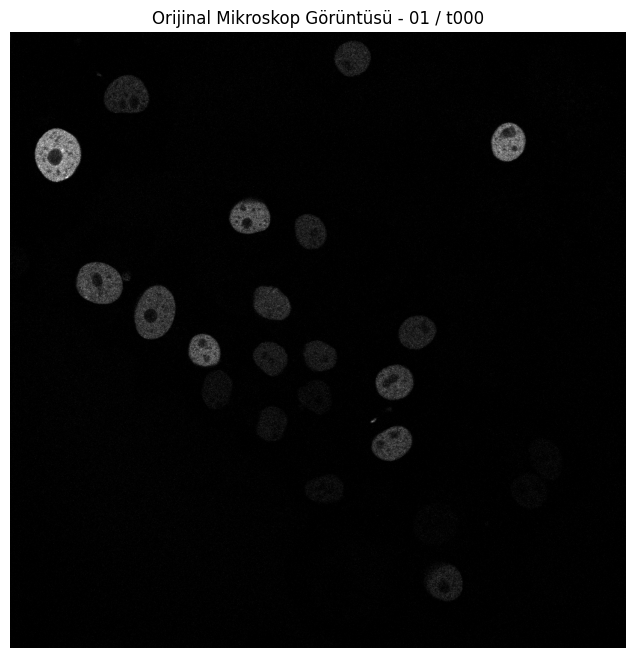

In [7]:
# İlk mikroskop görüntüsünü dosyadan okur.
# IMREAD_UNCHANGED, görüntünün orijinal piksel değerlerini korur.

ilk_goruntu_yolu = os.path.join(veri_yolu, "01", "t000.tif")

orijinal_goruntu = cv2.imread(
    ilk_goruntu_yolu,
    cv2.IMREAD_UNCHANGED
)

# Görüntünün başarıyla okunup okunmadığını kontrol eder.
if orijinal_goruntu is None:
    raise FileNotFoundError("Görüntü dosyası okunamadı!")

# Görüntünün teknik özelliklerini yazdırır.
print("Görüntü boyutu:", orijinal_goruntu.shape)
print("Veri tipi:", orijinal_goruntu.dtype)
print("Minimum piksel değeri:", orijinal_goruntu.min())
print("Maksimum piksel değeri:", orijinal_goruntu.max())

# Orijinal mikroskop görüntüsünü gösterir.
plt.figure(figsize=(8, 8))
plt.imshow(orijinal_goruntu, cmap="gray")
plt.title("Orijinal Mikroskop Görüntüsü - 01 / t000")
plt.axis("off")
plt.show()

Bölüm 2 – Görüntü boyutu ve yoğunluk analizi

In [61]:

# İki sekansın görüntü özelliklerini inceleyelim

import cv2
import numpy as np
import os
import pandas as pd

ana_klasor = "/content/Fluo-N2DH-GOWT1"

sonuclar = []

for sekans in ["01", "02"]:
    klasor = os.path.join(ana_klasor, sekans)

    dosyalar = sorted([
        f for f in os.listdir(klasor)
        if f.endswith(".tif")
    ])

    for dosya in dosyalar:
        yol = os.path.join(klasor, dosya)
        goruntu = cv2.imread(yol, cv2.IMREAD_UNCHANGED)

        sonuclar.append({
            "Sekans": sekans,
            "Dosya": dosya,
            "Yukseklik": goruntu.shape[0],
            "Genislik": goruntu.shape[1],
            "Veri_Tipi": str(goruntu.dtype),
            "Minimum": int(goruntu.min()),
            "Maksimum": int(goruntu.max()),
            "Ortalama": round(float(goruntu.mean()), 2),
            "Standart_Sapma": round(float(goruntu.std()), 2)
        })

ozellik_df = pd.DataFrame(sonuclar)

# Her sekansın genel özelliklerini özetleyelim
ozet_df = ozellik_df.groupby("Sekans").agg({
    "Yukseklik": "unique",
    "Genislik": "unique",
    "Veri_Tipi": "unique",
    "Minimum": "min",
    "Maksimum": "max",
    "Ortalama": "mean",
    "Standart_Sapma": "mean"
}).round(2)

print("SEKANSLARIN GENEL ÖZELLİKLERİ")
display(ozet_df)

print("TOPLAM İNCELENEN GÖRÜNTÜ:", len(ozellik_df))


SEKANSLARIN GENEL ÖZELLİKLERİ


,Yukseklik,Genislik,Veri_Tipi,Minimum,Maksimum,Ortalama,Standart_Sapma
Sekans,,,,,,,
01,[1024],[1024],[uint8],0,255,3.97,12.54
02,[1024],[1024],[uint8],0,182,2.09,5.61


TOPLAM İNCELENEN GÖRÜNTÜ: 184


Bölüm 2 – Veri Setinin Yoğunluk Dağılımının İncelenmesi

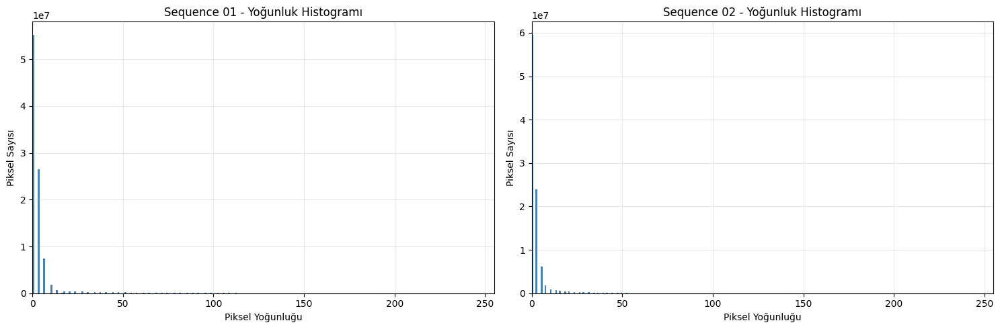

In [62]:

# İki sekansın yoğunluk dağılımlarını histogram ile karşılaştıralım

import matplotlib.pyplot as plt
import cv2
import os
import numpy as np

sekans_histogramlari = {}

for sekans in ["01", "02"]:
    klasor = os.path.join(ana_klasor, sekans)

    # Sekanstaki tüm görüntüleri okuyup piksel değerlerini birleştirelim
    piksel_degerleri = []

    dosyalar = sorted([
        f for f in os.listdir(klasor)
        if f.endswith(".tif")
    ])

    for dosya in dosyalar:
        goruntu = cv2.imread(
            os.path.join(klasor, dosya),
            cv2.IMREAD_UNCHANGED
        )

        piksel_degerleri.append(goruntu.ravel())

    sekans_histogramlari[sekans] = np.concatenate(piksel_degerleri)

# İki sekansın histogramlarını yan yana çizelim
fig, eksenler = plt.subplots(1, 2, figsize=(15, 5))

for ax, sekans in zip(eksenler, ["01", "02"]):
    ax.hist(
        sekans_histogramlari[sekans],
        bins=256,
        range=(0, 256),
        color="steelblue"
    )

    ax.set_title(f"Sequence {sekans} - Yoğunluk Histogramı")
    ax.set_xlabel("Piksel Yoğunluğu")
    ax.set_ylabel("Piksel Sayısı")
    ax.set_xlim(0, 255)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/rapor_gorselleri/02_sekans_histogramlari.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Bölüm 2 – Veri Setinin Görsel Olarak İncelenmesi

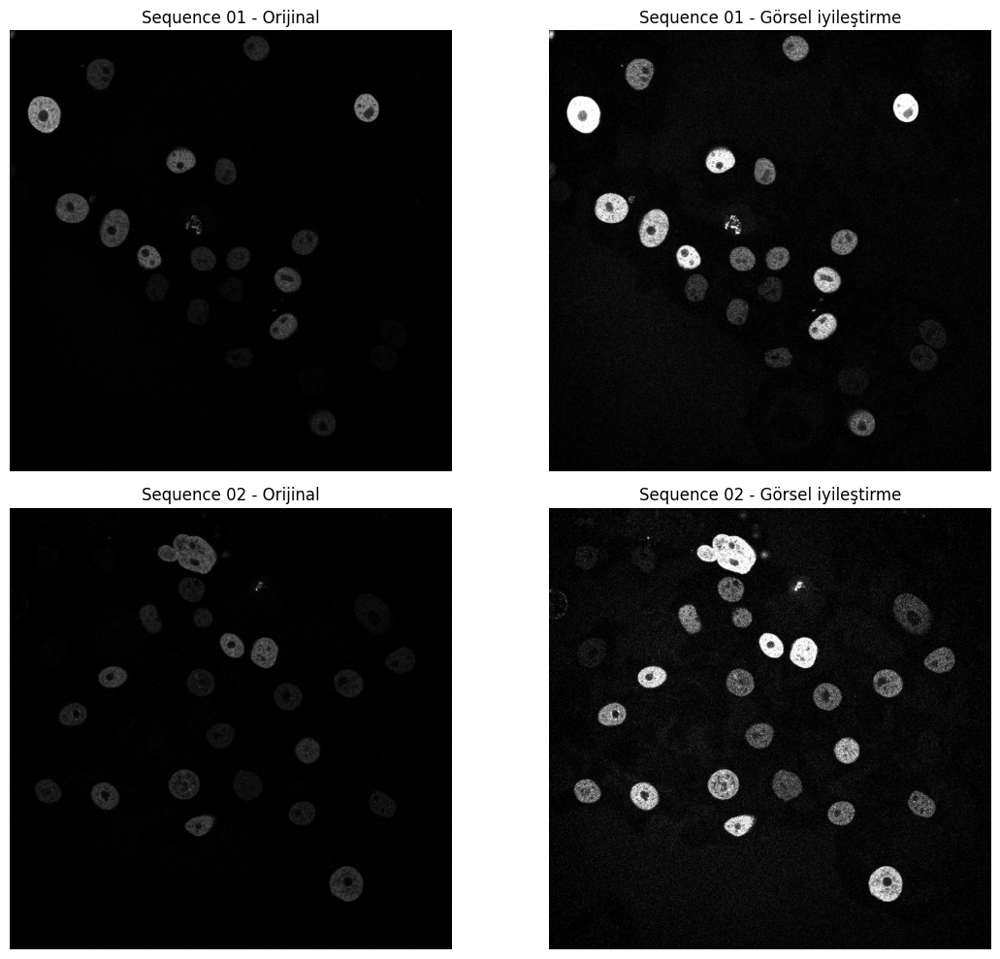

In [63]:

# İki sekansın temsilî görüntülerini karşılaştıralım

import matplotlib.pyplot as plt
import cv2
import os
import numpy as np

# İncelemek için iki temsilî görüntü seçiyoruz
ornekler = [
    ("01", "t008.tif"),
    ("02", "t043.tif")
]

fig, eksenler = plt.subplots(2, 2, figsize=(12, 10))

for satir, (sekans, dosya) in enumerate(ornekler):

    yol = os.path.join(ana_klasor, sekans, dosya)
    goruntu = cv2.imread(yol, cv2.IMREAD_UNCHANGED)

    # Görüntüyü yalnızca görsel inceleme için iyileştiriyoruz
    alt, ust = np.percentile(goruntu, (1, 99))
    goruntu_iyilestirilmis = cv2.normalize(
        np.clip(goruntu, alt, ust),
        None, 0, 255, cv2.NORM_MINMAX
    )

    eksenler[satir, 0].imshow(goruntu, cmap="gray")
    eksenler[satir, 0].set_title(f"Sequence {sekans} - Orijinal")

    eksenler[satir, 1].imshow(
        goruntu_iyilestirilmis, cmap="gray"
    )
    eksenler[satir, 1].set_title(
        f"Sequence {sekans} - Görsel iyileştirme"
    )

    for ax in eksenler[satir]:
        ax.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/rapor_gorselleri/03_sekans_gorsel_inceleme.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


6. Bölüm – Yoğunluk Dönüşümleri (Intensity Transformations) (Orjinal Görüntü)

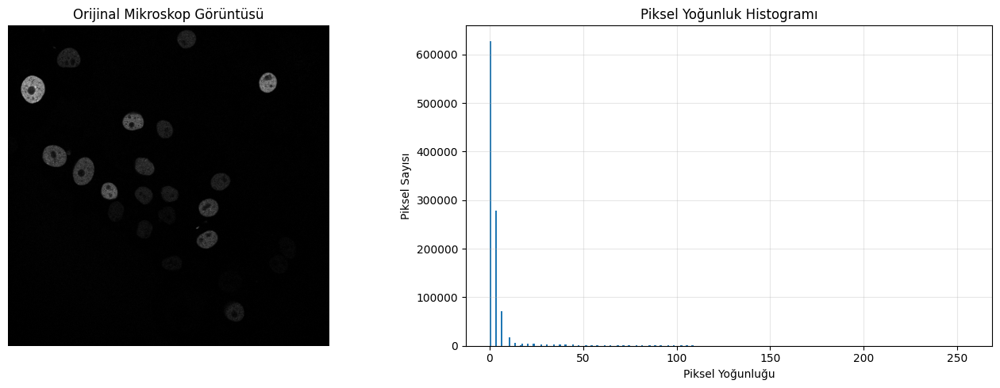

In [8]:
# Orijinal görüntüyü ve piksel yoğunluk histogramını birlikte gösterir.
# Histogram, görüntüdeki parlaklık değerlerinin dağılımını açıklar.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sol tarafta orijinal mikroskop görüntüsü.
axes[0].imshow(orijinal_goruntu, cmap="gray")
axes[0].set_title("Orijinal Mikroskop Görüntüsü")
axes[0].axis("off")

# Sağ tarafta piksel yoğunluk histogramı.
axes[1].hist(
    orijinal_goruntu.ravel(),
    bins=256,
    range=(0, 256)
)

axes[1].set_title("Piksel Yoğunluk Histogramı")
axes[1].set_xlabel("Piksel Yoğunluğu")
axes[1].set_ylabel("Piksel Sayısı")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

6. Bölüm – Yoğunluk Dönüşümleri (Intensity Transformations) (Kontrast Genişletme)

Alt sınır: 0.0
Üst sınır: 68.0


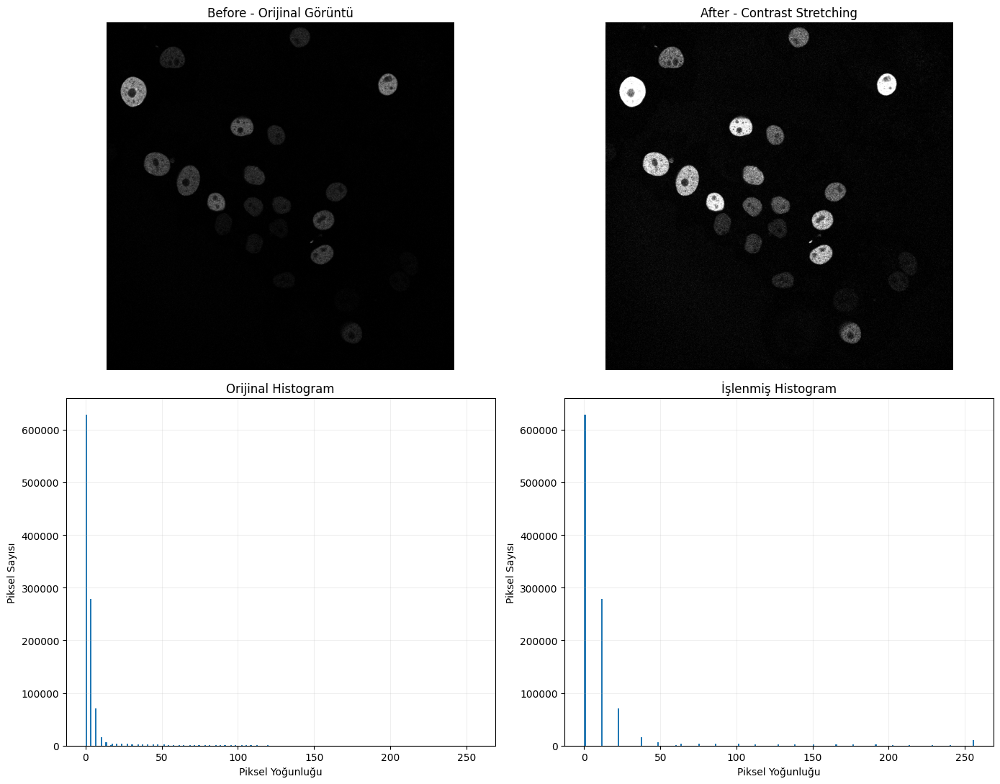

In [9]:
# Bu aşamada kontrast genişletme (Contrast Stretching)
# yöntemiyle hücrelerin görünürlüğünü artırmayı deniyoruz.

# Orijinal görüntünün %1 ve %99 yüzdelik değerlerini hesaplar.
# Böylece aşırı uçtaki piksel değerlerinin etkisini azaltırız.
alt_sinir = np.percentile(orijinal_goruntu, 1)
ust_sinir = np.percentile(orijinal_goruntu, 99)

# Piksel değerlerini belirlenen aralığa göre 0-255 arasına yayar.
kontrast_goruntu = np.clip(
    (orijinal_goruntu.astype(np.float32) - alt_sinir)
    / (ust_sinir - alt_sinir) * 255,
    0,
    255
).astype(np.uint8)

print("Alt sınır:", alt_sinir)
print("Üst sınır:", ust_sinir)

# Orijinal ve işlenmiş görüntüleri karşılaştırır.
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

axes[0, 0].imshow(orijinal_goruntu, cmap="gray")
axes[0, 0].set_title("Before - Orijinal Görüntü")

axes[0, 1].imshow(kontrast_goruntu, cmap="gray")
axes[0, 1].set_title("After - Contrast Stretching")

axes[1, 0].hist(orijinal_goruntu.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Orijinal Histogram")

axes[1, 1].hist(kontrast_goruntu.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("İşlenmiş Histogram")

for ax in axes.flat:
    if ax in axes[0]:
        ax.axis("off")
    else:
        ax.set_xlabel("Piksel Yoğunluğu")
        ax.set_ylabel("Piksel Sayısı")
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

6. Bölüm – Yoğunluk Dönüşümleri (Intensity Transformations) (Contrast Stretching)

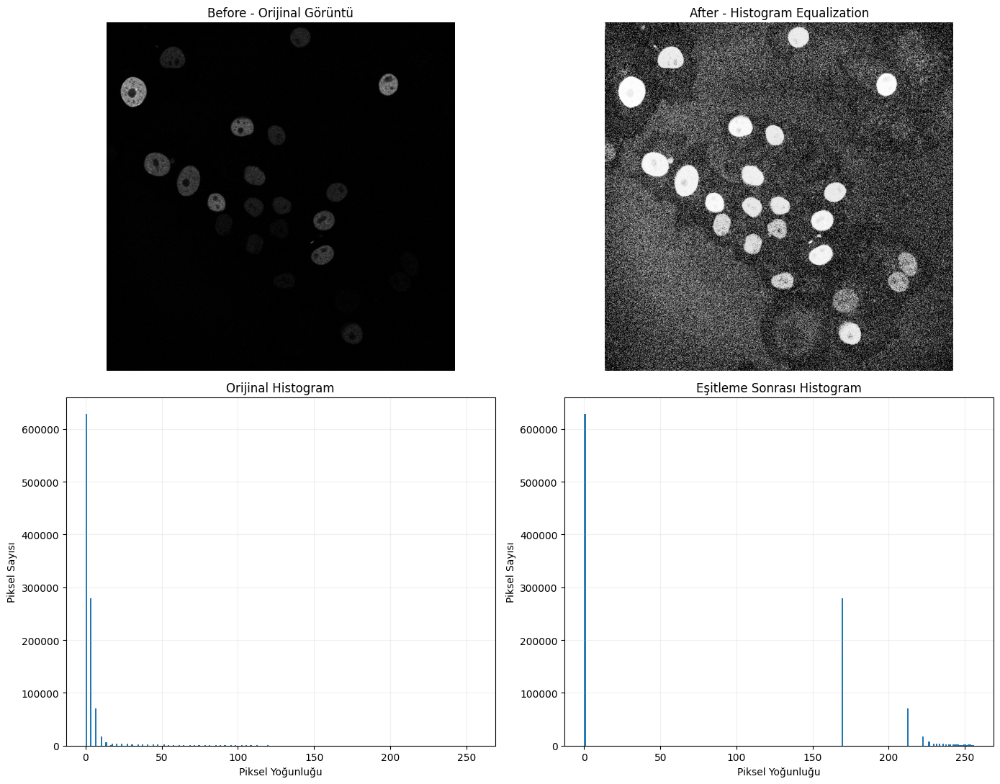

In [10]:
# HISTOGRAM EQUALIZATION (HİSTOGRAM EŞİTLEME)
# Bu yöntem, görüntüdeki piksel yoğunluklarını yeniden dağıtarak
# kontrastı artırmayı amaçlar.

# Orijinal görüntü üzerinden histogram eşitleme uygular.
# Böylece önceki Contrast Stretching işleminden etkilenmez.
histogram_goruntu = cv2.equalizeHist(orijinal_goruntu)

# Rapor için görsellerin kaydedileceği klasörü oluşturur.
rapor_klasoru = "/content/rapor_gorselleri"
os.makedirs(rapor_klasoru, exist_ok=True)

# İşlem öncesi ve sonrası görüntüleri karşılaştırır.
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Orijinal görüntü.
axes[0, 0].imshow(orijinal_goruntu, cmap="gray")
axes[0, 0].set_title("Before - Orijinal Görüntü")
axes[0, 0].axis("off")

# Histogram eşitleme uygulanmış görüntü.
axes[0, 1].imshow(histogram_goruntu, cmap="gray")
axes[0, 1].set_title("After - Histogram Equalization")
axes[0, 1].axis("off")

# Orijinal görüntünün histogramı.
axes[1, 0].hist(orijinal_goruntu.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Orijinal Histogram")

# İşlenmiş görüntünün histogramı.
axes[1, 1].hist(histogram_goruntu.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Eşitleme Sonrası Histogram")

# Histogram grafiklerinin eksenlerini ve ızgaralarını düzenler.
for ax in axes[1]:
    ax.set_xlabel("Piksel Yoğunluğu")
    ax.set_ylabel("Piksel Sayısı")
    ax.grid(alpha=0.2)

plt.tight_layout()

# Karşılaştırma görselini rapor için kaydeder.
plt.savefig(
    os.path.join(rapor_klasoru, "02_histogram_equalization.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

3. Bölüm – Veri Setinin İncelenmesi ve Görüntü Aralıklarının Kontrolü

In [13]:
# İki sekansın görüntü sayılarını ve kare aralıklarını kontrol eder.

for sekans in ["01", "02"]:
    klasor_yolu = os.path.join(veri_yolu, sekans)

    dosyalar = sorted([
        f for f in os.listdir(klasor_yolu)
        if f.lower().endswith(".tif")
    ])

    # Dosya adlarından kare numaralarını çıkarır.
    kare_numaralari = [
        int(os.path.splitext(f)[0][1:])
        for f in dosyalar
    ]

    print(f"\nSekans: {sekans}")
    print("Toplam görüntü:", len(dosyalar))
    print("İlk kare numarası:", min(kare_numaralari))
    print("Son kare numarası:", max(kare_numaralari))
    print("İlk 5 dosya:", dosyalar[:5])
    print("Son 5 dosya:", dosyalar[-5:])


Sekans: 01
Toplam görüntü: 92
İlk kare numarası: 0
Son kare numarası: 91
İlk 5 dosya: ['t000.tif', 't001.tif', 't002.tif', 't003.tif', 't004.tif']
Son 5 dosya: ['t087.tif', 't088.tif', 't089.tif', 't090.tif', 't091.tif']

Sekans: 02
Toplam görüntü: 92
İlk kare numarası: 0
Son kare numarası: 91
İlk 5 dosya: ['t000.tif', 't001.tif', 't002.tif', 't003.tif', 't004.tif']
Son 5 dosya: ['t087.tif', 't088.tif', 't089.tif', 't090.tif', 't091.tif']


3. Bölüm – Rastgele görüntü seçimi

In [66]:
# Gerekli kütüphaneleri kullanarak rastgele seçim yapar.
# Aynı tohum sayesinde seçimler her çalıştırmada tekrarlanabilir.

import random

rastgele = random.Random(29030)

# Sekans 01: Development ve Validation
development_adaylari = list(range(0, 87))
rastgele.shuffle(development_adaylari)

development_kareleri = sorted(development_adaylari[:10])

# Development karelerinden en az 5 kare uzaklıktaki
# kareler arasından Validation seçimi yapılır.
validation_adaylari = [
    kare for kare in range(92)
    if all(abs(kare - d) >= 5 for d in development_kareleri)
]

rastgele.shuffle(validation_adaylari)
validation_kareleri = sorted(validation_adaylari[:5])

# Sekans 02: Üç adet ardışık 5 karelik test bloğu.
blok_baslangiclari = list(range(0, 88))
rastgele.shuffle(blok_baslangiclari)

secili_bloklar = []

for baslangic in blok_baslangiclari:
    yeni_blok = set(range(baslangic, baslangic + 5))

    # Önceki test bloklarıyla en az 5 karelik boşluk bırakır.
    uygun = all(
        min(abs(a - b) for a in yeni_blok for b in eski_blok) >= 6
        for eski_blok in secili_bloklar
    )

    if uygun:
        secili_bloklar.append(yeni_blok)

    if len(secili_bloklar) == 3:
        break

secili_bloklar = sorted(secili_bloklar, key=min)

# Seçimleri ekrana yazdırır.
print("Development:", development_kareleri)
print("Validation:", validation_kareleri)

for i, blok in enumerate(secili_bloklar, 1):
    print(f"Test Block {i}:", sorted(blok))

print("Toplam seçilen görüntü:",
      len(development_kareleri) + len(validation_kareleri)
      + sum(len(blok) for blok in secili_bloklar))

Development: [8, 13, 19, 37, 45, 48, 57, 62, 71, 83]
Validation: [0, 26, 28, 31, 90]
Test Block 1: [43, 44, 45, 46, 47]
Test Block 2: [62, 63, 64, 65, 66]
Test Block 3: [84, 85, 86, 87, 88]
Toplam seçilen görüntü: 30


3. Bölüm – Seçim dosyasını oluşturma

,sequence,frame_index,image_file,group
0,01,8,t008.tif,development
1,01,13,t013.tif,development
2,01,19,t019.tif,development
3,01,37,t037.tif,development
4,01,45,t045.tif,development
5,01,48,t048.tif,development
6,01,57,t057.tif,development
7,01,62,t062.tif,development
8,01,71,t071.tif,development
9,01,83,t083.tif,development


Toplam kayıt: 30
CSV dosyası kaydedildi: /content/selected_frames.csv


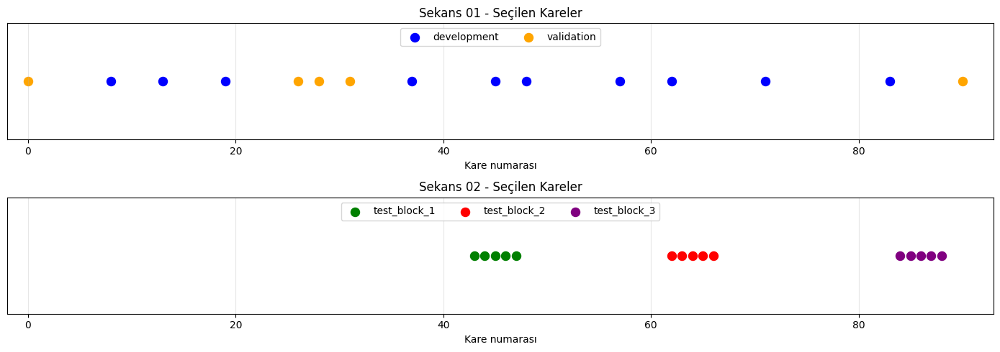

In [15]:
# Seçilen 30 görüntünün bilgilerini CSV dosyasına kaydeder.
# Ayrıca seçimleri gösteren bir zaman çizelgesi oluşturur.

secilen_kayitlar = []

# Sekans 01 - Development
for kare in development_kareleri:
    secilen_kayitlar.append({
        "sequence": "01",
        "frame_index": kare,
        "image_file": f"t{kare:03d}.tif",
        "group": "development"
    })

# Sekans 01 - Validation
for kare in validation_kareleri:
    secilen_kayitlar.append({
        "sequence": "01",
        "frame_index": kare,
        "image_file": f"t{kare:03d}.tif",
        "group": "validation"
    })

# Sekans 02 - Üç test bloğu
for i, blok in enumerate(secili_bloklar, 1):
    for kare in sorted(blok):
        secilen_kayitlar.append({
            "sequence": "02",
            "frame_index": kare,
            "image_file": f"t{kare:03d}.tif",
            "group": f"test_block_{i}"
        })

# Kayıtları DataFrame'e dönüştürür.
selected_frames = pd.DataFrame(secilen_kayitlar)

# CSV dosyasını kaydeder.
csv_yolu = "/content/selected_frames.csv"
selected_frames.to_csv(csv_yolu, index=False)

# Seçim tablosunu gösterir.
display(selected_frames)

print("Toplam kayıt:", len(selected_frames))
print("CSV dosyası kaydedildi:", csv_yolu)

# Seçilen karelerin zaman çizelgesini oluşturur.
fig, eksenler = plt.subplots(2, 1, figsize=(14, 5))

renkler = {
    "development": "blue",
    "validation": "orange",
    "test_block_1": "green",
    "test_block_2": "red",
    "test_block_3": "purple"
}

for sekans, eksen in zip(["01", "02"], eksenler):
    veri = selected_frames[selected_frames["sequence"] == sekans]

    for grup, grup_verisi in veri.groupby("group"):
        eksen.scatter(
            grup_verisi["frame_index"],
            [1] * len(grup_verisi),
            label=grup,
            color=renkler[grup],
            s=75
        )

    eksen.set_title(f"Sekans {sekans} - Seçilen Kareler")
    eksen.set_xlim(-2, 93)
    eksen.set_ylim(0.5, 1.5)
    eksen.set_yticks([])
    eksen.set_xlabel("Kare numarası")
    eksen.grid(axis="x", alpha=0.3)
    eksen.legend(loc="upper center", ncol=3)

plt.tight_layout()

# Görseli rapor klasörüne kaydeder.
os.makedirs("/content/rapor_gorselleri", exist_ok=True)
plt.savefig(
    "/content/rapor_gorselleri/03_secilen_kareler.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

3. Bölüm – Veri Setinin Seçilmesi

In [64]:

# Mevcut görüntü seçim dosyasını kontrol edelim
# Bu kod seçimleri değiştirmez, yalnızca dosyayı inceler.

import pandas as pd
import os

csv_yolu = "/content/selected_frames.csv"

if not os.path.exists(csv_yolu):
    print("HATA: selected_frames.csv bulunamadı.")
else:
    secim_df = pd.read_csv(csv_yolu)

    print("SÜTUNLAR:")
    print(secim_df.columns.tolist())

    print("\nTOPLAM GÖRÜNTÜ:", len(secim_df))

    print("\nGRUPLARA GÖRE GÖRÜNTÜ SAYILARI:")
    print(secim_df.groupby(["sequence", "group"]).size())

    print("\nSEÇİLEN KARELER:")
    for (sekans, grup), veri in secim_df.groupby(["sequence", "group"]):
        print(f"\nSekans {sekans} - {grup}:")
        print(sorted(veri["frame_index"].tolist()))

    print("\nSEED BİLGİSİ:")
    if "seed" in secim_df.columns:
        print("CSV içerisinde kayıtlı seed:", secim_df["seed"].unique())
    else:
        print("CSV içerisinde seed sütunu bulunmuyor.")


SÜTUNLAR:
['sequence', 'frame_index', 'image_file', 'group']

TOPLAM GÖRÜNTÜ: 30

GRUPLARA GÖRE GÖRÜNTÜ SAYILARI:
sequence  group       
1         development     10
          validation       5
2         test_block_1     5
          test_block_2     5
          test_block_3     5
dtype: int64

SEÇİLEN KARELER:

Sekans 1 - development:
[8, 13, 19, 37, 45, 48, 57, 62, 71, 83]

Sekans 1 - validation:
[0, 26, 28, 31, 90]

Sekans 2 - test_block_1:
[43, 44, 45, 46, 47]

Sekans 2 - test_block_2:
[62, 63, 64, 65, 66]

Sekans 2 - test_block_3:
[84, 85, 86, 87, 88]

SEED BİLGİSİ:
CSV içerisinde seed sütunu bulunmuyor.


3. Bölüm – Veri Setinin Seçilmesi

In [65]:

# Mevcut seçimleri koruyarak seed bilgisini CSV'ye ekleyelim

secim_df["seed"] = 29030

secim_df.to_csv(
    "/content/selected_frames.csv",
    index=False
)

print("Seed bilgisi kaydedildi:", secim_df["seed"].iloc[0])
print("Toplam kayıt:", len(secim_df))
display(secim_df.head())


Seed bilgisi kaydedildi: 29030
Toplam kayıt: 30


,sequence,frame_index,image_file,group,seed
0,1,8,t008.tif,development,29030
1,1,13,t013.tif,development,29030
2,1,19,t019.tif,development,29030
3,1,37,t037.tif,development,29030
4,1,45,t045.tif,development,29030


4. Bölüm – Ground Truth (Gerçek Hücre Sayılarının Belirlenmesi)

In [16]:

# 4. AŞAMA – GROUND TRUTH (GERÇEK HÜCRE SAYILARININ BELİRLENMESİ)
# Development ve validation görüntülerinin gerçek hücre sayılarını hesaplar.
# Test görüntülerinin etiketlerine bu aşamada kesinlikle dokunmaz.

# Daha önce kaydettiğimiz 30 görüntülük seçim tablosunu okur.
secim_df = pd.read_csv("/content/selected_frames.csv")

# Yalnızca development ve validation gruplarını seçer.
degerlendirme_df = secim_df[
    secim_df["group"].isin(["development", "validation"])
].copy()

sonuclar = []

for _, satir in degerlendirme_df.iterrows():

    # Sekans ve kare numarasını alır.
    sekans = str(satir["sequence"]).zfill(2)
    kare = int(satir["frame_index"])

    # İlgili Ground Truth TRA etiket dosyasının yolunu oluşturur.
    etiket_yolu = os.path.join(
        veri_yolu,
        f"{sekans}_GT",
        "TRA",
        f"man_track{kare:03d}.tif"
    )

    # Etiket görüntüsünü orijinal piksel değerleriyle okur.
    etiket_goruntu = cv2.imread(
        etiket_yolu,
        cv2.IMREAD_UNCHANGED
    )

    # Dosyanın okunup okunmadığını kontrol eder.
    if etiket_goruntu is None:
        raise FileNotFoundError(
            f"Ground Truth dosyası bulunamadı: {etiket_yolu}"
        )

    # Sıfır arka planı hariç tutarak benzersiz hücre kimliklerini bulur.
    hucre_idleri = np.unique(etiket_goruntu)
    hucre_idleri = hucre_idleri[hucre_idleri > 0]

    # Gerçek hücre sayısını kaydeder.
    sonuclar.append({
        "sequence": sekans,
        "frame_index": kare,
        "image_file": satir["image_file"],
        "group": satir["group"],
        "ground_truth_count": len(hucre_idleri)
    })

# Sonuçları tabloya dönüştürür.
ground_truth_df = pd.DataFrame(sonuclar)

# Sonuç tablosunu CSV olarak kaydeder.
ground_truth_df.to_csv(
    "/content/ground_truth_counts.csv",
    index=False
)

# Hesaplanan gerçek hücre sayılarını gösterir.
display(ground_truth_df)

print("Toplam değerlendirilen görüntü:", len(ground_truth_df))
print("Development görüntüsü:",
      (ground_truth_df["group"] == "development").sum())
print("Validation görüntüsü:",
      (ground_truth_df["group"] == "validation").sum())
print("Ground Truth sonuçları kaydedildi.")


,sequence,frame_index,image_file,group,ground_truth_count
0,01,8,t008.tif,development,23
1,01,13,t013.tif,development,23
2,01,19,t019.tif,development,23
3,01,37,t037.tif,development,24
4,01,45,t045.tif,development,24
5,01,48,t048.tif,development,24
6,01,57,t057.tif,development,21
7,01,62,t062.tif,development,21
8,01,71,t071.tif,development,21
9,01,83,t083.tif,development,20


Toplam değerlendirilen görüntü: 15
Development görüntüsü: 10
Validation görüntüsü: 5
Ground Truth sonuçları kaydedildi.


4. Bölüm - Ground Truth Hücre Sayılarının Görselleştirilmesi

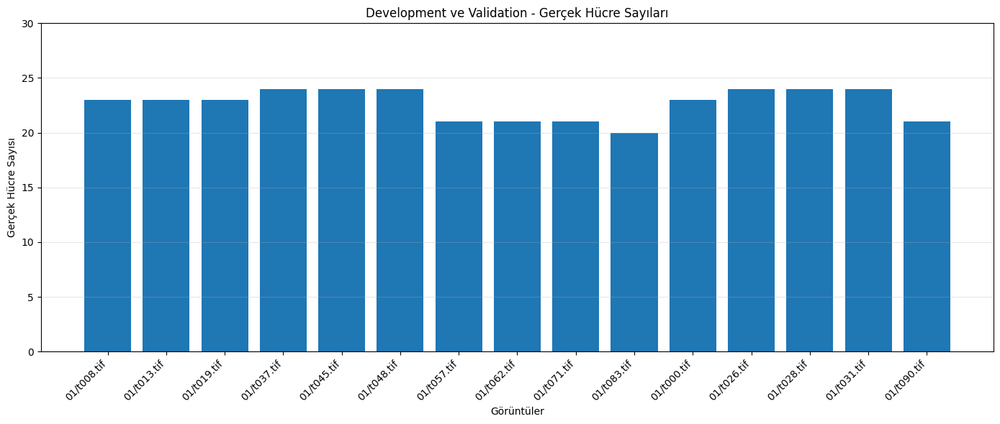

Grup bazında ortalama gerçek hücre sayıları:


,mean,min,max
group,,,
development,22.4,20,24
validation,23.2,21,24


In [17]:

# 4. AŞAMA – GROUND TRUTH SONUÇLARININ GÖRSELLEŞTİRİLMESİ
# Development ve validation görüntülerindeki gerçek hücre
# sayılarını karşılaştırmalı olarak gösterir.

# Görselin boyutunu belirler.
plt.figure(figsize=(14, 6))

# Her görüntünün gerçek hücre sayısını sütun grafikle gösterir.
etiketler = (
    ground_truth_df["sequence"] + "/" +
    ground_truth_df["image_file"]
)

plt.bar(
    etiketler,
    ground_truth_df["ground_truth_count"]
)

# Grafik başlığını ve eksen isimlerini ekler.
plt.title("Development ve Validation - Gerçek Hücre Sayıları")
plt.xlabel("Görüntüler")
plt.ylabel("Gerçek Hücre Sayısı")

# X eksenindeki dosya isimlerini okunabilir hâle getirir.
plt.xticks(rotation=45, ha="right")

# Y eksenindeki değerleri düzenler.
plt.yticks(range(0, 31, 5))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Grafiği rapor klasörüne kaydeder.
plt.savefig(
    os.path.join(rapor_klasoru, "03_ground_truth_counts.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Grupların ortalama hücre sayılarını hesaplar.
print("Grup bazında ortalama gerçek hücre sayıları:")
display(
    ground_truth_df.groupby("group")["ground_truth_count"]
    .agg(["mean", "min", "max"])
    .round(2)
)


4. Bölüm - Ground Truth Hücre Sayılarının Görselleştirilmesi (Hücre Görselleştirmesi)

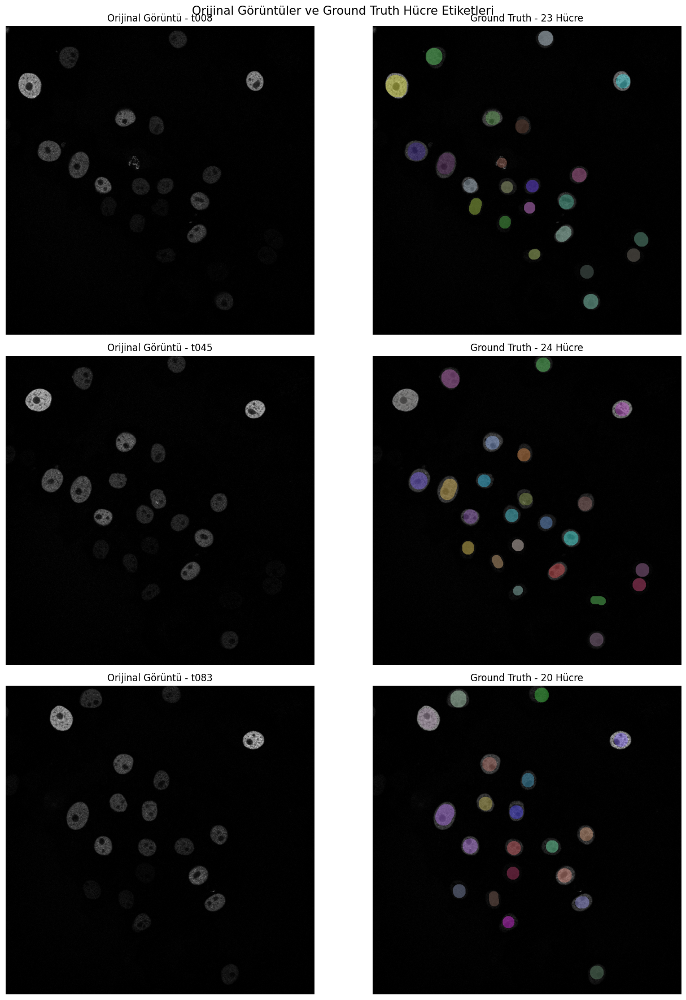

Ground Truth hücre görselleştirmesi kaydedildi.


In [18]:

# 4. AŞAMA – GROUND TRUTH HÜCRE GÖRSELLEŞTİRMESİ
# Orijinal mikroskop görüntülerindeki gerçek hücre etiketlerini
# renkli olarak gösterir ve hücre sayılarını karşılaştırır.

# Development grubundan 3 örnek görüntü seçer.
ornek_kareler = [8, 45, 83]

# Aynı renklerin her çalıştırmada kullanılmasını sağlar.
renk_uretici = np.random.default_rng(29030)

# Görselleştirme alanını oluşturur.
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for i, kare in enumerate(ornek_kareler):

    # Orijinal mikroskop görüntüsünün yolunu oluşturur.
    goruntu_yolu = os.path.join(
        veri_yolu, "01", f"t{kare:03d}.tif"
    )

    # Ground Truth etiket görüntüsünün yolunu oluşturur.
    etiket_yolu = os.path.join(
        veri_yolu, "01_GT", "TRA",
        f"man_track{kare:03d}.tif"
    )

    # İki görüntüyü de okur.
    orijinal = cv2.imread(goruntu_yolu, cv2.IMREAD_UNCHANGED)
    etiket = cv2.imread(etiket_yolu, cv2.IMREAD_UNCHANGED)

    # Dosyaların başarıyla okunup okunmadığını kontrol eder.
    if orijinal is None or etiket is None:
        raise FileNotFoundError(f"t{kare:03d} görüntüsü veya etiketi bulunamadı.")

    # Gerçek hücre kimliklerini bulur.
    hucre_idleri = np.unique(etiket)
    hucre_idleri = hucre_idleri[hucre_idleri > 0]

    # Orijinal görüntüyü üç kanallı renkli görüntüye dönüştürür.
    taban_goruntu = cv2.cvtColor(orijinal, cv2.COLOR_GRAY2RGB)

    # Renkli etiket görüntüsünü hazırlar.
    renkli_etiket = np.zeros(
        (etiket.shape[0], etiket.shape[1], 3),
        dtype=np.uint8
    )

    # Her hücre kimliğine farklı bir renk atar.
    for hucre_id in hucre_idleri:
        renk = renk_uretici.integers(50, 256, size=3)
        renkli_etiket[etiket == hucre_id] = renk

    # Gerçek hücre bölgelerini orijinal görüntü üzerine bindirir.
    hucre_maskesi = etiket > 0

    birlesik_goruntu = taban_goruntu.copy()

    birlesik_goruntu[hucre_maskesi] = (
        0.55 * taban_goruntu[hucre_maskesi]
        + 0.45 * renkli_etiket[hucre_maskesi]
    ).astype(np.uint8)

    # Sol tarafta orijinal görüntüyü gösterir.
    axes[i, 0].imshow(orijinal, cmap="gray")
    axes[i, 0].set_title(f"Orijinal Görüntü - t{kare:03d}")
    axes[i, 0].axis("off")

    # Sağ tarafta Ground Truth etiketlerini gösterir.
    axes[i, 1].imshow(birlesik_goruntu)
    axes[i, 1].set_title(
        f"Ground Truth - {len(hucre_idleri)} Hücre"
    )
    axes[i, 1].axis("off")

plt.suptitle(
    "Orijinal Görüntüler ve Ground Truth Hücre Etiketleri",
    fontsize=15
)

plt.tight_layout()

# Görseli rapor klasörüne kaydeder.
plt.savefig(
    os.path.join(
        rapor_klasoru,
        "04_ground_truth_hucre_gorsellestirme.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Ground Truth hücre görselleştirmesi kaydedildi.")


4. Bölüm – Ground Truth (Gerçek Hücre Sayılarının Belirlenmesi)

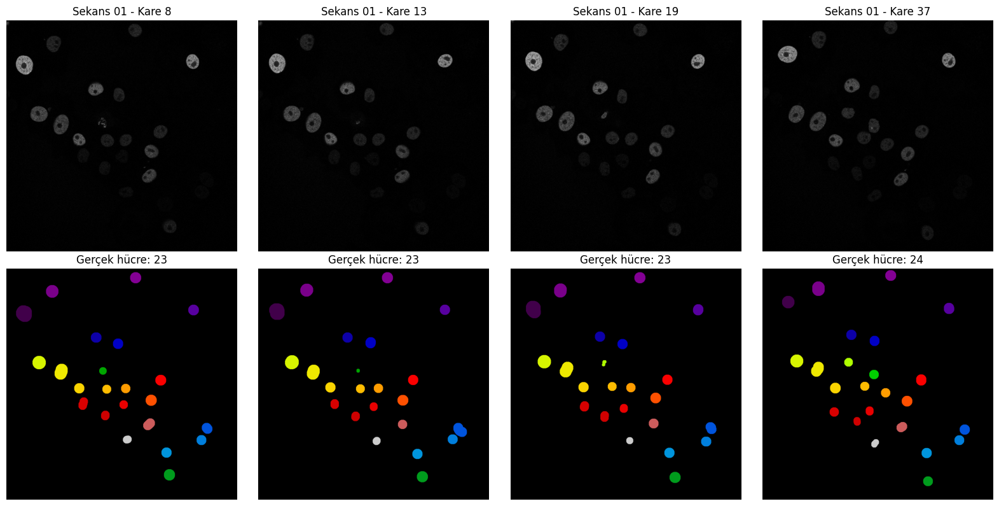

In [67]:

import matplotlib.pyplot as plt
import cv2
import os

# Development ve Validation gruplarından ilk 4 görüntüyü seç
kontrol_df = ground_truth_df.head(4)

fig, eksenler = plt.subplots(2, 4, figsize=(16, 8))

for i, (_, satir) in enumerate(kontrol_df.iterrows()):

    sekans = str(satir["sequence"]).zfill(2)
    kare = int(satir["frame_index"])

    # Orijinal görüntü
    goruntu_yolu = os.path.join(
        veri_yolu, sekans, f"t{kare:03d}.tif"
    )

    # Ground Truth etiket görüntüsü
    etiket_yolu = os.path.join(
        veri_yolu, f"{sekans}_GT", "TRA",
        f"man_track{kare:03d}.tif"
    )

    goruntu = cv2.imread(goruntu_yolu, cv2.IMREAD_UNCHANGED)
    etiket = cv2.imread(etiket_yolu, cv2.IMREAD_UNCHANGED)

    # Orijinal görüntüyü göster
    eksenler[0, i].imshow(goruntu, cmap="gray")
    eksenler[0, i].set_title(
        f"Sekans {sekans} - Kare {kare}"
    )
    eksenler[0, i].axis("off")

    # Ground Truth etiketini göster
    eksenler[1, i].imshow(etiket, cmap="nipy_spectral")
    eksenler[1, i].set_title(
        f"Gerçek hücre: {int(satir['ground_truth_count'])}"
    )
    eksenler[1, i].axis("off")

plt.tight_layout()
plt.show()


4. Bölüm – Ground Truth (Gerçek Hücre Sayılarının Belirlenmesi)

In [68]:

# Development ve Validation etiket dosyalarının kontrolü

eksik_dosyalar = []
kontrol_edilen = 0

for _, satir in degerlendirme_df.iterrows():

    sekans = str(satir["sequence"]).zfill(2)
    kare = int(satir["frame_index"])

    etiket_yolu = os.path.join(
        veri_yolu,
        f"{sekans}_GT",
        "TRA",
        f"man_track{kare:03d}.tif"
    )

    if not os.path.exists(etiket_yolu):
        eksik_dosyalar.append(etiket_yolu)
    else:
        kontrol_edilen += 1

print("Kontrol edilen etiket dosyası:", kontrol_edilen)
print("Eksik dosya sayısı:", len(eksik_dosyalar))

if eksik_dosyalar:
    print("Eksik dosyalar:")
    for dosya in eksik_dosyalar:
        print(dosya)
else:
    print("Tüm Development ve Validation etiket dosyaları mevcut.")


Kontrol edilen etiket dosyası: 15
Eksik dosya sayısı: 0
Tüm Development ve Validation etiket dosyaları mevcut.


5. Bölüm – BASELINE (TEMEL HÜCRE SAYIM YÖNTEMİ)

Görüntü: t008.tif
Otsu eşik değeri: 34.0
Baseline tahmini: 1021
Ground Truth: 23
Mutlak hata: 998


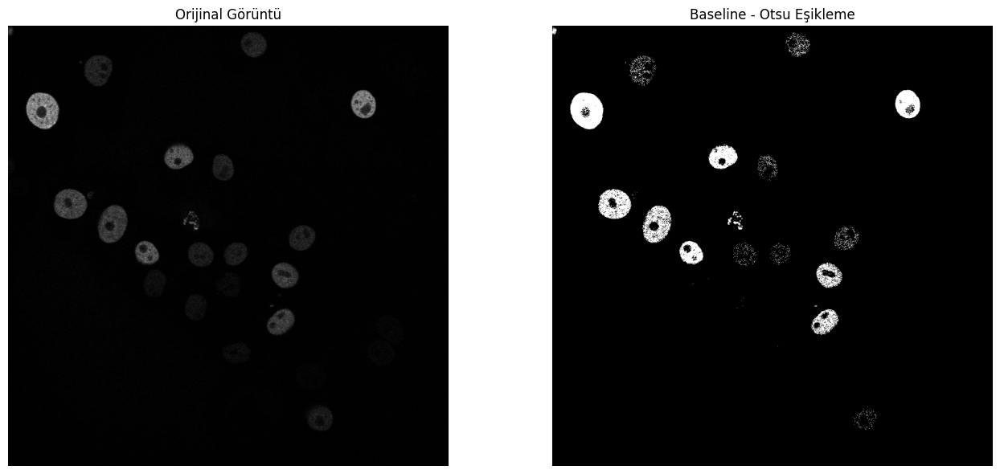

In [20]:

# 5. AŞAMA – BASELINE (TEMEL HÜCRE SAYIM YÖNTEMİ)
# Gelişmiş görüntü işleme yöntemleri kullanmadan,
# Otsu eşikleme ve bağlı bileşen analiziyle hücreleri sayar.

# İlk development görüntüsünü seçer.
baseline_kare = 8

# Orijinal görüntünün dosya yolunu oluşturur.
goruntu_yolu = os.path.join(
    veri_yolu, "01", f"t{baseline_kare:03d}.tif"
)

# Görüntüyü okur.
baseline_goruntu = cv2.imread(
    goruntu_yolu, cv2.IMREAD_GRAYSCALE
)

# Görüntünün okunmasını kontrol eder.
if baseline_goruntu is None:
    raise FileNotFoundError("Baseline görüntüsü okunamadı!")

# Otsu eşikleme uygular.
esik_degeri, ikili_goruntu = cv2.threshold(
    baseline_goruntu,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Bağlı bileşen analizi uygular.
bilesen_sayisi, etiketler, istatistikler, merkezler = (
    cv2.connectedComponentsWithStats(
        ikili_goruntu,
        connectivity=8
    )
)

# Arka planı sayımdan çıkarır.
baseline_tahmin = bilesen_sayisi - 1

# Ground Truth hücre sayısını tablodan alır.
baseline_gercek = int(
    ground_truth_df.loc[
        ground_truth_df["frame_index"] == baseline_kare,
        "ground_truth_count"
    ].iloc[0]
)

# Sonuçları ekrana yazdırır.
print("Görüntü:", f"t{baseline_kare:03d}.tif")
print("Otsu eşik değeri:", esik_degeri)
print("Baseline tahmini:", baseline_tahmin)
print("Ground Truth:", baseline_gercek)
print("Mutlak hata:", abs(baseline_tahmin - baseline_gercek))

# İşlem öncesi ve sonrası görüntüleri karşılaştırır.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(baseline_goruntu, cmap="gray")
axes[0].set_title("Orijinal Görüntü")
axes[0].axis("off")

axes[1].imshow(ikili_goruntu, cmap="gray")
axes[1].set_title("Baseline - Otsu Eşikleme")
axes[1].axis("off")

plt.tight_layout()

# Karşılaştırma görselini kaydeder.
plt.savefig(
    os.path.join(rapor_klasoru, "05_baseline_otsu.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


5. Bölüm - Baseline Hata Analizi ve Bileşen Görselleştirmesi

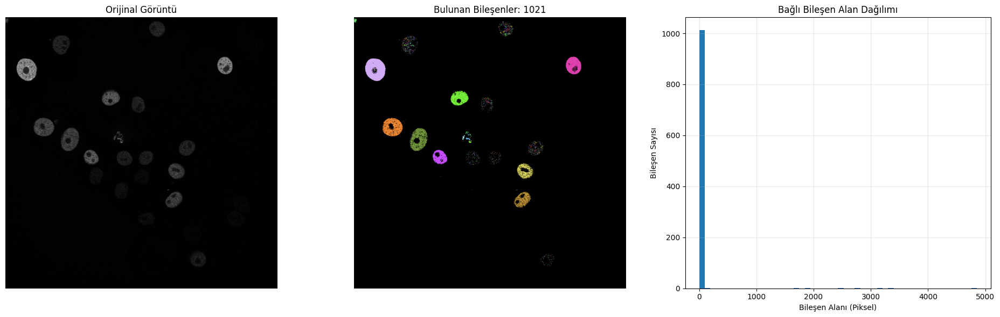

Toplam bileşen: 1021
En küçük bileşen alanı: 1
Medyan bileşen alanı: 1.0
En büyük bileşen alanı: 4856
25. yüzdelik alan: 1.0
75. yüzdelik alan: 2.0


In [21]:

# 5. AŞAMA – BASELINE HATA ANALİZİ
# Otsu eşikleme sonucunda oluşan bağlı bileşenleri
# ve bu bileşenlerin alan dağılımını inceler.

# Arka plan hariç bileşenlerin alanlarını alır.
bilesen_alanlari = istatistikler[1:, cv2.CC_STAT_AREA]

# Her bileşene farklı bir renk atar.
renk_uretici = np.random.default_rng(29030)

renkli_bilesenler = np.zeros(
    (*etiketler.shape, 3),
    dtype=np.uint8
)

for bilesen_id in range(1, bilesen_sayisi):
    renk = renk_uretici.integers(50, 256, size=3)
    renkli_bilesenler[etiketler == bilesen_id] = renk

# Üç farklı analiz görseli oluşturur.
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

# Orijinal görüntü.
axes[0].imshow(baseline_goruntu, cmap="gray")
axes[0].set_title("Orijinal Görüntü")
axes[0].axis("off")

# Bulunan bağlı bileşenler.
axes[1].imshow(renkli_bilesenler)
axes[1].set_title(f"Bulunan Bileşenler: {baseline_tahmin}")
axes[1].axis("off")

# Bileşen alanlarının dağılımı.
axes[2].hist(
    bilesen_alanlari,
    bins=50
)
axes[2].set_title("Bağlı Bileşen Alan Dağılımı")
axes[2].set_xlabel("Bileşen Alanı (Piksel)")
axes[2].set_ylabel("Bileşen Sayısı")
axes[2].grid(alpha=0.3)

plt.tight_layout()

# Analiz görselini rapor klasörüne kaydeder.
plt.savefig(
    os.path.join(rapor_klasoru, "06_baseline_hata_analizi.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Bileşen alanlarına ilişkin istatistikleri gösterir.
print("Toplam bileşen:", len(bilesen_alanlari))
print("En küçük bileşen alanı:", bilesen_alanlari.min())
print("Medyan bileşen alanı:", np.median(bilesen_alanlari))
print("En büyük bileşen alanı:", bilesen_alanlari.max())
print("25. yüzdelik alan:", np.percentile(bilesen_alanlari, 25))
print("75. yüzdelik alan:", np.percentile(bilesen_alanlari, 75))


5. Bölüm - Minimum Bileşen Alanı Eşiğinin Belirlenmesi

In [22]:
# Bileşenlerin alanlarını alır.
# İlk bileşen arka plan olduğu için onu listeye dahil etmez.
bilesen_alanlari = istatistikler[1:, cv2.CC_STAT_AREA]

# Denenecek minimum bileşen alanlarını belirler.
minimum_alanlar = [1, 2, 5, 10, 20, 50, 100, 200]

# Her minimum alan için kalan bileşen sayısını hesaplar.
sonuclar = []

for minimum_alan in minimum_alanlar:

    # Minimum alan şartını sağlayan bileşenleri sayar.
    kalan_sayi = np.sum(bilesen_alanlari >= minimum_alan)

    sonuclar.append({
        "Minimum Alan (piksel)": minimum_alan,
        "Kalan Bileşen Sayısı": int(kalan_sayi),
        "Ground Truth": baseline_gercek,
        "Mutlak Hata": int(abs(kalan_sayi - baseline_gercek))
    })

# Sonuçları tablo olarak gösterir.
alan_filtre_tablosu = pd.DataFrame(sonuclar)

display(alan_filtre_tablosu)

,Minimum Alan (piksel),Kalan Bileşen Sayısı,Ground Truth,Mutlak Hata
0,1,1021,23,998
1,2,424,23,401
2,5,122,23,99
3,10,56,23,33
4,20,21,23,2
5,50,12,23,11
6,100,9,23,14
7,200,8,23,15


Bölüm 5 – Baseline (Temel Hücre Sayım Yöntemi) (Verilerin yüklenmesi ve kontrol edilmesi)

In [23]:

# Development ve Ground Truth tablolarını dosyalardan yükler.
selected_df = pd.read_csv("/content/selected_frames.csv")
ground_truth_df = pd.read_csv("/content/ground_truth_counts.csv")

# Tabloların sütunlarını kontrol eder.
print("Seçilen görüntülerin sütunları:")
print(selected_df.columns.tolist())

print("\nGround Truth tablosunun sütunları:")
print(ground_truth_df.columns.tolist())

# İlk satırları göstererek sütunların içeriğini inceler.
print("\nSeçilen görüntüler:")
display(selected_df.head())

print("\nGround Truth kayıtları:")
display(ground_truth_df.head())


Seçilen görüntülerin sütunları:
['sequence', 'frame_index', 'image_file', 'group']

Ground Truth tablosunun sütunları:
['sequence', 'frame_index', 'image_file', 'group', 'ground_truth_count']

Seçilen görüntüler:


,sequence,frame_index,image_file,group
0,1,8,t008.tif,development
1,1,13,t013.tif,development
2,1,19,t019.tif,development
3,1,37,t037.tif,development
4,1,45,t045.tif,development



Ground Truth kayıtları:


,sequence,frame_index,image_file,group,ground_truth_count
0,1,8,t008.tif,development,23
1,1,13,t013.tif,development,23
2,1,19,t019.tif,development,23
3,1,37,t037.tif,development,24
4,1,45,t045.tif,development,24


Bölüm 5 – Baseline (Temel Hücre Sayım Yöntemi) (Development görüntülerinde Baseline performansının ölçülmesi)

In [24]:

# Development grubundaki görüntüleri seçer.
development_df = selected_df[
    selected_df["group"] == "development"
].copy()

# Sonuçları saklamak için boş liste oluşturur.
baseline_sonuclari = []

# Her development görüntüsünü sırayla işler.
for _, satir in development_df.iterrows():

    # Görüntü bilgilerini alır.
    sekans = int(satir["sequence"])
    kare = int(satir["frame_index"])

    # Görüntü dosyasının yolunu oluşturur.
    goruntu_yolu = os.path.join(
        veri_yolu,
        f"{sekans:02d}",
        f"t{kare:03d}.tif"
    )

    # Orijinal görüntüyü gri tonlamalı okur.
    goruntu = cv2.imread(
        goruntu_yolu,
        cv2.IMREAD_GRAYSCALE
    )

    # Görüntünün okunup okunmadığını kontrol eder.
    if goruntu is None:
        raise FileNotFoundError(goruntu_yolu)

    # Otsu eşikleme uygular.
    _, ikili = cv2.threshold(
        goruntu,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Bağlı bileşenleri bulur.
    toplam, etiketler, istatistikler, merkezler = (
        cv2.connectedComponentsWithStats(
            ikili,
            connectivity=8
        )
    )

    # Arka plan dışındaki bileşenlerin alanlarını alır.
    alanlar = istatistikler[1:, cv2.CC_STAT_AREA]

    # Filtresiz tahmini hesaplar.
    filtresiz_tahmin = toplam - 1

    # Minimum 20 piksel alan filtresi uygular.
    filtreli_tahmin = int(np.sum(alanlar >= 20))

    # Ground Truth değerini sekans ve kare numarasıyla eşleştirir.
    gercek_deger = int(
        ground_truth_df.loc[
            (ground_truth_df["sequence"] == sekans) &
            (ground_truth_df["frame_index"] == kare),
            "ground_truth_count"
        ].iloc[0]
    )

    # Sonuçları listeye ekler.
    baseline_sonuclari.append({
        "sequence": sekans,
        "frame_index": kare,
        "image_file": satir["image_file"],
        "ground_truth": gercek_deger,
        "baseline_prediction": filtresiz_tahmin,
        "baseline_error": abs(filtresiz_tahmin - gercek_deger),
        "filtered_prediction": filtreli_tahmin,
        "filtered_error": abs(filtreli_tahmin - gercek_deger)
    })

# Sonuç listesini DataFrame'e dönüştürür.
baseline_df = pd.DataFrame(baseline_sonuclari)

# Sonuç tablosunu gösterir.
display(baseline_df)


,sequence,frame_index,image_file,ground_truth,baseline_prediction,baseline_error,filtered_prediction,filtered_error
0,1,8,t008.tif,23,1021,998,21,2
1,1,13,t013.tif,23,1026,1003,21,2
2,1,19,t019.tif,23,1013,990,40,17
3,1,37,t037.tif,24,952,928,41,17
4,1,45,t045.tif,24,748,724,41,17
5,1,48,t048.tif,24,872,848,39,15
6,1,57,t057.tif,21,733,712,44,23
7,1,62,t062.tif,21,648,627,43,22
8,1,71,t071.tif,21,702,681,34,13
9,1,83,t083.tif,20,679,659,29,9


Bölüm 5 – Baseline (Temel Hücre Sayım Yöntemi) (Baseline performans metriklerinin hesaplanması)

In [25]:

# Ortalama Mutlak Hata (MAE) hesaplar.
baseline_mae = baseline_df["baseline_error"].mean()
filtered_mae = baseline_df["filtered_error"].mean()

# Kök Ortalama Kare Hata (RMSE) hesaplar.
baseline_rmse = np.sqrt(
    np.mean(
        (baseline_df["baseline_prediction"] -
         baseline_df["ground_truth"]) ** 2
    )
)

filtered_rmse = np.sqrt(
    np.mean(
        (baseline_df["filtered_prediction"] -
         baseline_df["ground_truth"]) ** 2
    )
)

# Ortalama işaretli hatayı (Bias) hesaplar.
baseline_bias = (
    baseline_df["baseline_prediction"] -
    baseline_df["ground_truth"]
).mean()

filtered_bias = (
    baseline_df["filtered_prediction"] -
    baseline_df["ground_truth"]
).mean()

# Metrikleri karşılaştırma tablosuna aktarır.
baseline_metrikleri = pd.DataFrame({
    "Yöntem": ["Filtresiz Baseline", "20 Piksel Alan Filtresi"],
    "MAE": [baseline_mae, filtered_mae],
    "RMSE": [baseline_rmse, filtered_rmse],
    "Bias": [baseline_bias, filtered_bias]
})

display(baseline_metrikleri)

# Sonuçları dosyaya kaydeder.
baseline_metrikleri.to_csv(
    os.path.join(rapor_klasoru, "baseline_metrikleri.csv"),
    index=False
)


,Yöntem,MAE,RMSE,Bias
0,Filtresiz Baseline,817.0,829.740441,817.0
1,20 Piksel Alan Filtresi,13.7,15.372053,12.9


Bölüm 5 – Baseline (Temel Hücre Sayım Yöntemi) (Development sonuçlarının grafikle görselleştirilmesi)

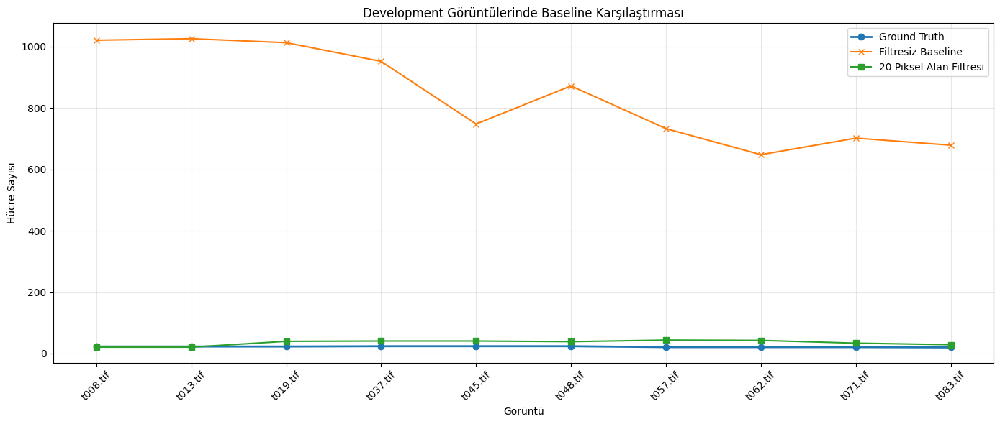

In [26]:

# Görüntü numaralarını grafik için hazırlar.
kareler = baseline_df["image_file"]

# Karşılaştırma grafiğini oluşturur.
plt.figure(figsize=(14, 6))

# Gerçek hücre sayılarını çizer.
plt.plot(
    kareler,
    baseline_df["ground_truth"],
    marker="o",
    linewidth=2,
    label="Ground Truth"
)

# Filtresiz Baseline tahminlerini çizer.
plt.plot(
    kareler,
    baseline_df["baseline_prediction"],
    marker="x",
    label="Filtresiz Baseline"
)

# 20 piksel filtreli tahminleri çizer.
plt.plot(
    kareler,
    baseline_df["filtered_prediction"],
    marker="s",
    label="20 Piksel Alan Filtresi"
)

# Grafik başlık ve eksenlerini ayarlar.
plt.title("Development Görüntülerinde Baseline Karşılaştırması")
plt.xlabel("Görüntü")
plt.ylabel("Hücre Sayısı")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Grafiği rapor klasörüne kaydeder.
plt.savefig(
    os.path.join(rapor_klasoru, "06_baseline_karsilastirma.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


Bölüm 5 – Baseline (Temel Hücre Sayım Yöntemi) (Filtreli Baseline sonuçlarının yakınlaştırılmış karşılaştırması)

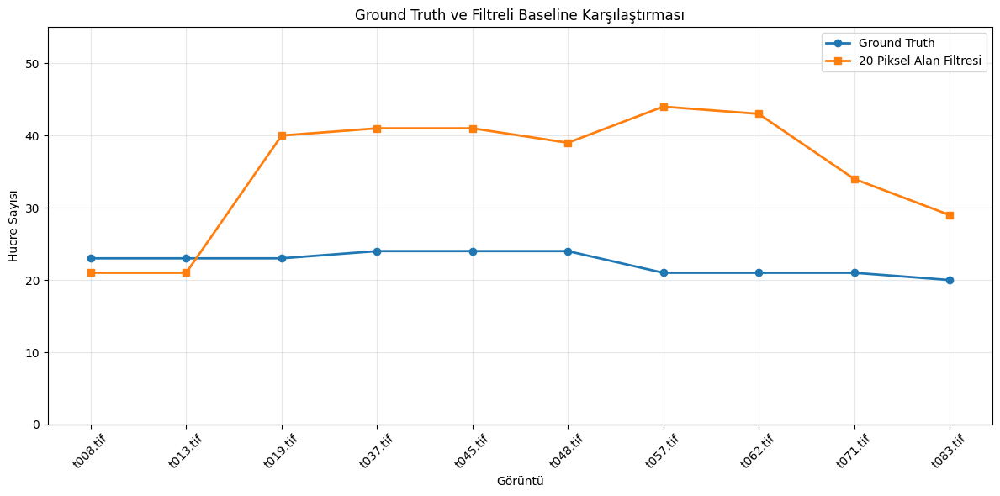

In [27]:

# Ground Truth ve filtreli tahminleri daha net karşılaştırır.
plt.figure(figsize=(12, 6))

plt.plot(
    baseline_df["image_file"],
    baseline_df["ground_truth"],
    marker="o",
    linewidth=2,
    label="Ground Truth"
)

plt.plot(
    baseline_df["image_file"],
    baseline_df["filtered_prediction"],
    marker="s",
    linewidth=2,
    label="20 Piksel Alan Filtresi"
)

# Y eksenini hücre sayılarının çevresine yakınlaştırır.
plt.ylim(0, 55)

plt.title("Ground Truth ve Filtreli Baseline Karşılaştırması")
plt.xlabel("Görüntü")
plt.ylabel("Hücre Sayısı")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Grafiği rapor klasörüne kaydeder.
plt.savefig(
    os.path.join(
        rapor_klasoru,
        "07_baseline_yakinlastirilmis.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


5. Bölüm – Baseline (Temel Hücre Sayma Yöntemi)

In [69]:

# Baseline yönteminin performans metrikleri

gercek = baseline_df["ground_truth"]
tahmin = baseline_df["filtered_prediction"]

hata = tahmin - gercek

mae = np.mean(np.abs(hata))
rmse = np.sqrt(np.mean(hata ** 2))
bias = np.mean(hata)

print("BASELINE PERFORMANS SONUÇLARI")
print("-----------------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"Bias : {bias:.2f}")


BASELINE PERFORMANS SONUÇLARI
-----------------------------
MAE  : 13.70
RMSE : 15.37
Bias : 12.90


5. Bölüm – Baseline (Temel Hücre Sayma Yöntemi)

In [70]:
baseline_df.to_csv(
    "/content/baseline_development_results.csv",
    index=False
)

print("Baseline sonuçları kaydedildi.")
print("Kayıt sayısı:", len(baseline_df))

Baseline sonuçları kaydedildi.
Kayıt sayısı: 10


Bölüm 6 – Yoğunluk Dönüşümleri (Intensity Transformations)

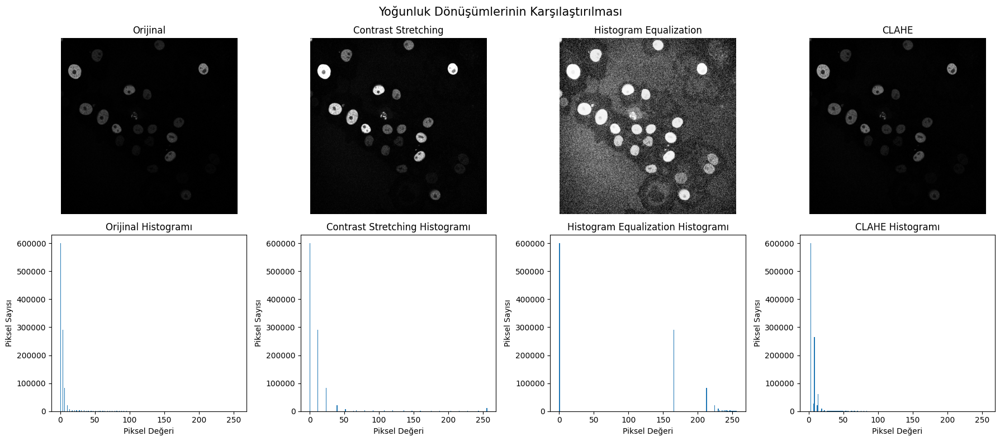

In [28]:

# Development grubundaki 8 numaralı görüntüyü yükler.
kare = 8
goruntu_yolu = os.path.join(veri_yolu, "01", f"t{kare:03d}.tif")
orijinal = cv2.imread(goruntu_yolu, cv2.IMREAD_GRAYSCALE)

if orijinal is None:
    raise FileNotFoundError(goruntu_yolu)

# 1. Contrast Stretching: Piksel değerlerini 0-255 aralığına yayar.
alt_sinir, ust_sinir = np.percentile(orijinal, (1, 99))
contrast = np.clip(
    (orijinal.astype(np.float32) - alt_sinir) *
    255 / (ust_sinir - alt_sinir),
    0, 255
).astype(np.uint8)

# 2. Histogram Equalization: Histogram dağılımını dengeler.
histogram_esitleme = cv2.equalizeHist(orijinal)

# 3. CLAHE: Görüntünün yerel bölgelerinde kontrastı iyileştirir.
clahe_yontemi = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)
clahe_goruntu = clahe_yontemi.apply(orijinal)

# Görüntüleri ve histogramlarını karşılaştırır.
goruntuler = [
    ("Orijinal", orijinal),
    ("Contrast Stretching", contrast),
    ("Histogram Equalization", histogram_esitleme),
    ("CLAHE", clahe_goruntu)
]

fig, eksenler = plt.subplots(2, 4, figsize=(18, 8))

for i, (baslik, goruntu) in enumerate(goruntuler):

    # Üst satırda işlenmiş görüntüyü gösterir.
    eksenler[0, i].imshow(goruntu, cmap="gray")
    eksenler[0, i].set_title(baslik)
    eksenler[0, i].axis("off")

    # Alt satırda görüntünün histogramını gösterir.
    eksenler[1, i].hist(
        goruntu.ravel(),
        bins=256,
        range=(0, 256)
    )
    eksenler[1, i].set_title(f"{baslik} Histogramı")
    eksenler[1, i].set_xlabel("Piksel Değeri")
    eksenler[1, i].set_ylabel("Piksel Sayısı")

plt.suptitle("Yoğunluk Dönüşümlerinin Karşılaştırılması", fontsize=15)
plt.tight_layout()

# Karşılaştırma görselini rapor klasörüne kaydeder.
plt.savefig(
    os.path.join(rapor_klasoru, "08_yogunluk_donusumleri.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


Bölüm 6 – Yoğunluk Dönüşümlerinin Sayısal Başarı Testi

In [29]:

# Development görüntülerini seçer.
development_df = selected_df[
    selected_df["group"] == "development"
].copy()

# Sonuçları saklamak için boş liste oluşturur.
yogunluk_sonuclari = []

# Her development görüntüsünü sırayla işler.
for _, satir in development_df.iterrows():

    sekans = int(satir["sequence"])
    kare = int(satir["frame_index"])

    goruntu_yolu = os.path.join(
        veri_yolu,
        f"{sekans:02d}",
        f"t{kare:03d}.tif"
    )

    orijinal = cv2.imread(
        goruntu_yolu,
        cv2.IMREAD_GRAYSCALE
    )

    if orijinal is None:
        raise FileNotFoundError(goruntu_yolu)

    # Contrast Stretching uygular.
    alt, ust = np.percentile(orijinal, (1, 99))
    contrast = np.clip(
        (orijinal.astype(np.float32) - alt) * 255 / (ust - alt),
        0, 255
    ).astype(np.uint8)

    # Histogram Equalization uygular.
    histogram_esitleme = cv2.equalizeHist(orijinal)

    # CLAHE uygular.
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    clahe_goruntu = clahe.apply(orijinal)

    # Dört yöntemi karşılaştırma listesine ekler.
    yontemler = {
        "Orijinal": orijinal,
        "Contrast Stretching": contrast,
        "Histogram Equalization": histogram_esitleme,
        "CLAHE": clahe_goruntu
    }

    # Her yöntemde Otsu ve bağlı bileşen sayımı yapar.
    for yontem_adi, islenmis in yontemler.items():

        _, ikili = cv2.threshold(
            islenmis,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        toplam, etiketler, istatistikler, merkezler = (
            cv2.connectedComponentsWithStats(
                ikili,
                connectivity=8
            )
        )

        alanlar = istatistikler[1:, cv2.CC_STAT_AREA]

        # Baseline ile aynı 20 piksel alan filtresini uygular.
        tahmin = int(np.sum(alanlar >= 20))

        # Ground Truth değerini bulur.
        gercek = int(
            ground_truth_df.loc[
                (ground_truth_df["sequence"] == sekans) &
                (ground_truth_df["frame_index"] == kare),
                "ground_truth_count"
            ].iloc[0]
        )

        yogunluk_sonuclari.append({
            "sequence": sekans,
            "frame_index": kare,
            "image_file": satir["image_file"],
            "method": yontem_adi,
            "ground_truth": gercek,
            "prediction": tahmin,
            "absolute_error": abs(tahmin - gercek)
        })

# Sonuçları tabloya dönüştürür.
yogunluk_df = pd.DataFrame(yogunluk_sonuclari)

# İlk sonuçları gösterir.
display(yogunluk_df.head(12))


,sequence,frame_index,image_file,method,ground_truth,prediction,absolute_error
0,1,8,t008.tif,Orijinal,23,21,2
1,1,8,t008.tif,Contrast Stretching,23,42,19
2,1,8,t008.tif,Histogram Equalization,23,1580,1557
3,1,8,t008.tif,CLAHE,23,43,20
4,1,13,t013.tif,Orijinal,23,21,2
5,1,13,t013.tif,Contrast Stretching,23,35,12
6,1,13,t013.tif,Histogram Equalization,23,1248,1225
7,1,13,t013.tif,CLAHE,23,32,9
8,1,19,t019.tif,Orijinal,23,40,17
9,1,19,t019.tif,Contrast Stretching,23,31,8


Bölüm 6 – Yoğunluk Dönüşümlerinin Sonuçlarını Görselleştirme ve Karşılaştırma

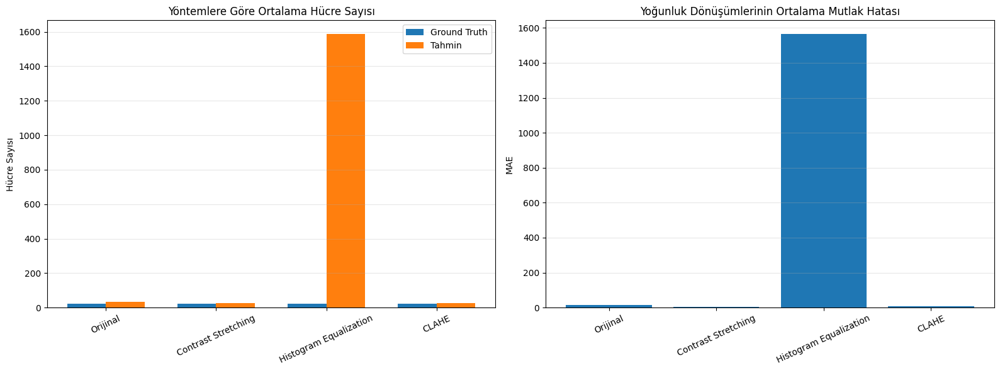

,method,Ortalama_Tahmin,Ortalama_Gercek,MAE
3,Orijinal,35.3,22.4,13.7
1,Contrast Stretching,26.7,22.4,5.9
2,Histogram Equalization,1587.4,22.4,1565.0
0,CLAHE,27.7,22.4,6.7


In [30]:

# Yöntemlerin ortalama hücre sayısını hesaplar.
yontem_ozet = yogunluk_df.groupby("method").agg(
    Ortalama_Tahmin=("prediction", "mean"),
    Ortalama_Gercek=("ground_truth", "mean"),
    MAE=("absolute_error", "mean")
).reset_index()

# Yöntemlerin sıralamasını belirler.
yontem_sirasi = [
    "Orijinal",
    "Contrast Stretching",
    "Histogram Equalization",
    "CLAHE"
]

yontem_ozet["method"] = pd.Categorical(
    yontem_ozet["method"],
    categories=yontem_sirasi,
    ordered=True
)

yontem_ozet = yontem_ozet.sort_values("method")

# İki grafik oluşturur.
fig, eksenler = plt.subplots(1, 2, figsize=(16, 6))

# 1. Ortalama tahmin ve gerçek hücre sayılarını karşılaştırır.
x = np.arange(len(yontem_ozet))
genislik = 0.35

eksenler[0].bar(
    x - genislik / 2,
    yontem_ozet["Ortalama_Gercek"],
    genislik,
    label="Ground Truth"
)

eksenler[0].bar(
    x + genislik / 2,
    yontem_ozet["Ortalama_Tahmin"],
    genislik,
    label="Tahmin"
)

eksenler[0].set_title("Yöntemlere Göre Ortalama Hücre Sayısı")
eksenler[0].set_ylabel("Hücre Sayısı")
eksenler[0].set_xticks(x)
eksenler[0].set_xticklabels(yontem_ozet["method"], rotation=25)
eksenler[0].legend()
eksenler[0].grid(axis="y", alpha=0.3)

# 2. Ortalama mutlak hataları karşılaştırır.
eksenler[1].bar(
    yontem_ozet["method"].astype(str),
    yontem_ozet["MAE"]
)

eksenler[1].set_title("Yoğunluk Dönüşümlerinin Ortalama Mutlak Hatası")
eksenler[1].set_ylabel("MAE")
eksenler[1].tick_params(axis="x", rotation=25)
eksenler[1].grid(axis="y", alpha=0.3)

plt.tight_layout()

# Grafikleri rapor klasörüne kaydeder.
plt.savefig(
    os.path.join(rapor_klasoru, "09_yogunluk_yontem_karsilastirma.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Sayısal karşılaştırma tablosunu da gösterir.
display(yontem_ozet)


Bölüm 6 – Yoğunluk Dönüşümlerinin Sonuçlarını Görselleştirme ve Karşılaştırma (2)

,method,Ortalama_Tahmin,Ortalama_Gercek,MAE
0,Orijinal,35.3,22.4,13.7
1,Contrast Stretching,26.7,22.4,5.9
2,Histogram Equalization,1587.4,22.4,1565.0
3,CLAHE,27.7,22.4,6.7


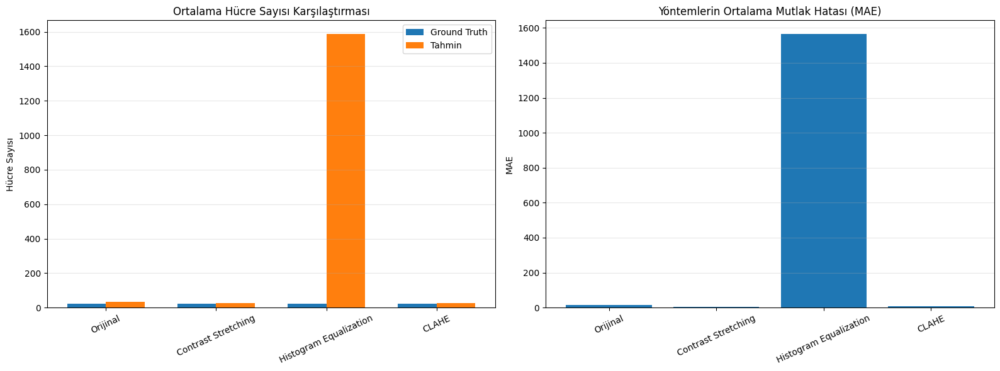

In [31]:

# Dört yoğunluk dönüşümünün ortalama sonuçlarını hesaplar.
yontem_ozet = yogunluk_df.groupby("method").agg(
    Ortalama_Tahmin=("prediction", "mean"),
    Ortalama_Gercek=("ground_truth", "mean"),
    MAE=("absolute_error", "mean")
).reindex([
    "Orijinal",
    "Contrast Stretching",
    "Histogram Equalization",
    "CLAHE"
]).reset_index()

# Sonuç tablosunu ekranda gösterir.
display(yontem_ozet.round(2))

# Sonuç tablosunu CSV dosyasına kaydeder.
yontem_ozet.to_csv(
    os.path.join(rapor_klasoru, "yogunluk_donusum_sonuclari.csv"),
    index=False
)

# İki karşılaştırma grafiği oluşturur.
fig, eksenler = plt.subplots(1, 2, figsize=(16, 6))

# Birinci grafik: Gerçek ve tahmin edilen hücre sayıları.
x = np.arange(len(yontem_ozet))
genislik = 0.35

eksenler[0].bar(
    x - genislik / 2,
    yontem_ozet["Ortalama_Gercek"],
    genislik,
    label="Ground Truth"
)

eksenler[0].bar(
    x + genislik / 2,
    yontem_ozet["Ortalama_Tahmin"],
    genislik,
    label="Tahmin"
)

eksenler[0].set_title("Ortalama Hücre Sayısı Karşılaştırması")
eksenler[0].set_ylabel("Hücre Sayısı")
eksenler[0].set_xticks(x)
eksenler[0].set_xticklabels(yontem_ozet["method"], rotation=25)
eksenler[0].legend()
eksenler[0].grid(axis="y", alpha=0.3)

# İkinci grafik: Ortalama mutlak hata.
eksenler[1].bar(
    yontem_ozet["method"].astype(str),
    yontem_ozet["MAE"]
)

eksenler[1].set_title("Yöntemlerin Ortalama Mutlak Hatası (MAE)")
eksenler[1].set_ylabel("MAE")
eksenler[1].tick_params(axis="x", rotation=25)
eksenler[1].grid(axis="y", alpha=0.3)

plt.tight_layout()

# Grafiği kaydeder.
plt.savefig(
    os.path.join(rapor_klasoru, "09_yogunluk_yontem_karsilastirma.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


Bölüm 6 – Görüntü Bazında Yoğunluk Dönüşümü Karşılaştırması

,ground_truth,Orijinal,Contrast Stretching,Histogram Equalization,CLAHE
image_file,,,,,
t008.tif,23,21,42,1580,43
t013.tif,23,21,35,1248,32
t019.tif,23,40,31,1427,39
t037.tif,24,41,20,1526,20
t045.tif,24,41,23,1471,22
t048.tif,24,39,23,1839,23
t057.tif,21,44,21,1401,21
t062.tif,21,43,19,1493,21
t071.tif,21,34,24,2217,25


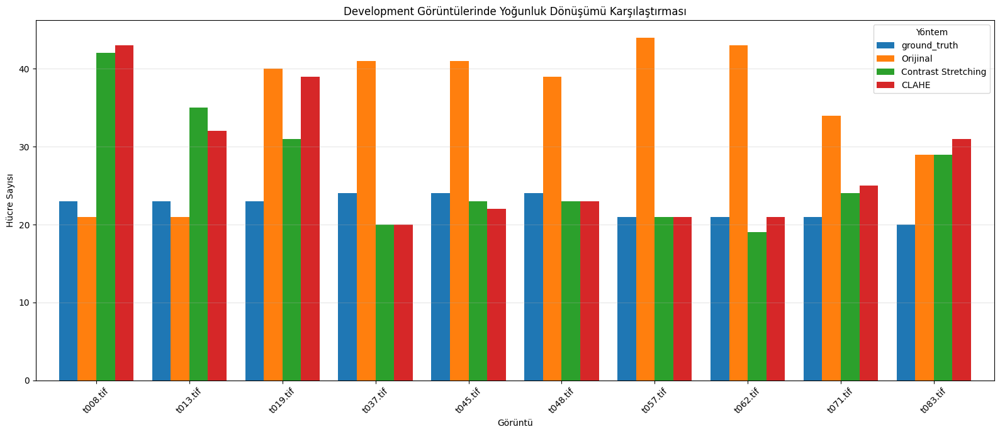

In [32]:

# Her görüntü için dört yöntemin tahminlerini karşılaştırır.
karsilastirma = yogunluk_df.pivot(
    index="image_file",
    columns="method",
    values="prediction"
)

# Gerçek hücre sayılarını ekler.
gercek_sayilar = (
    yogunluk_df[["image_file", "ground_truth"]]
    .drop_duplicates()
    .set_index("image_file")
)

karsilastirma = karsilastirma.join(gercek_sayilar)

# Sütunları düzenler.
karsilastirma = karsilastirma[
    [
        "ground_truth",
        "Orijinal",
        "Contrast Stretching",
        "Histogram Equalization",
        "CLAHE"
    ]
]

display(karsilastirma)

# Görüntü bazında karşılaştırma grafiği oluşturur.
karsilastirma[
    [
        "ground_truth",
        "Orijinal",
        "Contrast Stretching",
        "CLAHE"
    ]
].plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

plt.title("Development Görüntülerinde Yoğunluk Dönüşümü Karşılaştırması")
plt.xlabel("Görüntü")
plt.ylabel("Hücre Sayısı")
plt.xticks(rotation=45)
plt.legend(title="Yöntem")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(rapor_klasoru, "10_yogunluk_kare_bazli_karsilastirma.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


Bölüm 6 – Yoğunluk Dönüşümlerinin Görsel Kalite Açısından Karşılaştırılması

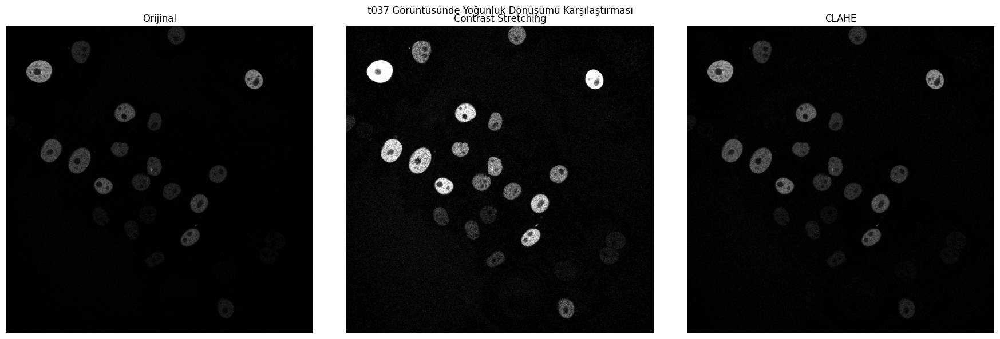

In [35]:

# t037 görüntüsünün tam dosya yolunu belirler.
ornek_yol = "/content/Fluo-N2DH-GOWT1/01/t037.tif"

# Orijinal görüntüyü gri tonlamalı yükler.
ornek = cv2.imread(ornek_yol, cv2.IMREAD_GRAYSCALE)

# Dosyanın doğru yüklendiğini kontrol eder.
if ornek is None:
    raise FileNotFoundError("t037.tif görüntüsü bulunamadı.")

# Contrast Stretching uygular.
alt = np.percentile(ornek, 1)
ust = np.percentile(ornek, 99)

if ust > alt:
    contrast = np.clip(
        (ornek.astype(np.float32) - alt) * 255 / (ust - alt),
        0, 255
    ).astype(np.uint8)
else:
    contrast = ornek.copy()

# CLAHE uygular.
clahe_nesnesi = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)
clahe_goruntu = clahe_nesnesi.apply(ornek)

# Üç görüntüyü yan yana gösterir.
fig, eksenler = plt.subplots(1, 3, figsize=(18, 6))

goruntuler = [
    (ornek, "Orijinal"),
    (contrast, "Contrast Stretching"),
    (clahe_goruntu, "CLAHE")
]

for ax, (goruntu, baslik) in zip(eksenler, goruntuler):
    ax.imshow(goruntu, cmap="gray")
    ax.set_title(baslik)
    ax.axis("off")

plt.suptitle("t037 Görüntüsünde Yoğunluk Dönüşümü Karşılaştırması")
plt.tight_layout()

plt.savefig(
    os.path.join(
        rapor_klasoru,
        "11_yogunluk_gorsel_karsilastirma.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


7. Bölüm – Filtreleme Yöntemlerinin Görsel Karşılaştırılması

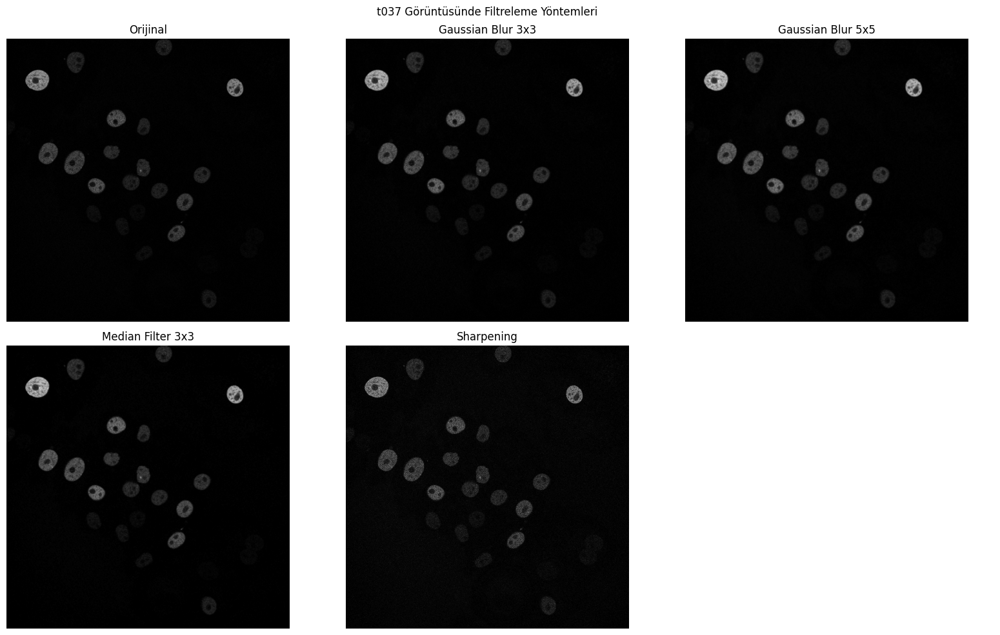

In [36]:

# BÖLÜM 7.1 - FİLTRELEME YÖNTEMLERİNİN GÖRSEL KARŞILAŞTIRMASI

# Gaussian Blur: 3x3 ve 5x5 kernel boyutları.
gaussian_3 = cv2.GaussianBlur(ornek, (3, 3), 0)
gaussian_5 = cv2.GaussianBlur(ornek, (5, 5), 0)

# Median Filter: 3x3 kernel boyutu.
median_3 = cv2.medianBlur(ornek, 3)

# Sharpening: Görüntüdeki kenarları belirginleştiren kernel.
keskinlestirme_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(ornek, -1, keskinlestirme_kernel)

# Orijinal ve filtrelenmiş görüntüleri karşılaştır.
filtreler = [
    (ornek, "Orijinal"),
    (gaussian_3, "Gaussian Blur 3x3"),
    (gaussian_5, "Gaussian Blur 5x5"),
    (median_3, "Median Filter 3x3"),
    (sharpened, "Sharpening")
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (goruntu, baslik) in zip(axes.ravel(), filtreler):
    ax.imshow(goruntu, cmap="gray")
    ax.set_title(baslik)
    ax.axis("off")

# Kullanılmayan son grafiği kapat.
axes.ravel()[-1].axis("off")

plt.suptitle("t037 Görüntüsünde Filtreleme Yöntemleri")
plt.tight_layout()

# Görseli rapor klasörüne kaydet.
plt.savefig(
    os.path.join(rapor_klasoru, "12_filtre_gorsel_karsilastirma.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


Bölüm 7 – Filtrelerin Hücre Sayımına Etkisinin Sayısal Olarak Değerlendirilmesi

In [39]:

# BÖLÜM 7.2 - FİLTRELERİN HÜCRE SAYIMINA ETKİSİ

# Daha önce oluşturduğumuz görüntü seçim tablosunu yükle.
secimler = pd.read_csv("/content/selected_frames.csv")

# Development görüntülerini seç.
development = secimler[
    secimler["group"] == "development"
].copy()

# Gerçek hücre sayılarını seçim tablosuna ekle.
ground_truth_df = pd.read_csv(
    "/content/ground_truth_counts.csv"
)

development = development.merge(
    ground_truth_df[
        ["sequence", "frame_index", "image_file", "ground_truth_count"]
    ],
    on=["sequence", "frame_index", "image_file"],
    how="left"
)

# Karşılaştırılacak filtre yöntemleri.
filtre_yontemleri = [
    "Orijinal",
    "Gaussian 3x3",
    "Gaussian 5x5",
    "Median 3x3",
    "Sharpening"
]

sonuclar = []

# Her development görüntüsünü sırayla işle.
for _, satir in development.iterrows():

    # Görüntünün dosya yolunu oluştur.
    klasor = f"{int(satir['sequence']):02d}"
    goruntu_yolu = f"/content/Fluo-N2DH-GOWT1/{klasor}/{satir['image_file']}"

    # Görüntüyü gri tonlamalı yükle.
    goruntu = cv2.imread(goruntu_yolu, cv2.IMREAD_GRAYSCALE)

    if goruntu is None:
        raise FileNotFoundError(goruntu_yolu)

    # Filtre uygulanmış görüntüleri oluştur.
    filtreli_goruntuler = {
        "Orijinal": goruntu,
        "Gaussian 3x3": cv2.GaussianBlur(goruntu, (3, 3), 0),
        "Gaussian 5x5": cv2.GaussianBlur(goruntu, (5, 5), 0),
        "Median 3x3": cv2.medianBlur(goruntu, 3),
        "Sharpening": cv2.filter2D(
            goruntu, -1,
            np.array([[0, -1, 0],
                      [-1, 5, -1],
                      [0, -1, 0]])
        )
    }

    # Her filtre için Otsu ve bağlı bileşen sayımı uygula.
    for yontem, filtreli in filtreli_goruntuler.items():

        _, ikili = cv2.threshold(
            filtreli, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        # Bağlı bileşenleri belirle.
        adet, etiketler, istatistikler, merkezler = (
            cv2.connectedComponentsWithStats(ikili, connectivity=8)
        )

        # Arka plan hariç, alanı en az 20 piksel olan bileşenleri say.
        tahmin = sum(
            1 for alan in istatistikler[1:, cv2.CC_STAT_AREA]
            if alan >= 20
        )

        # Sonuçları kaydet.
        gercek_sayi = int(satir["ground_truth_count"])

        sonuclar.append({
            "image_file": satir["image_file"],
            "method": yontem,
            "ground_truth": gercek_sayi,
            "prediction": tahmin,
            "absolute_error": abs(tahmin - gercek_sayi)
        })

# Sonuçları tabloya dönüştür.
filtre_df = pd.DataFrame(sonuclar)

# Her yöntemin ortalama tahminini ve MAE değerini hesapla.
filtre_ozet = (
    filtre_df.groupby("method")
    .agg(
        mean_prediction=("prediction", "mean"),
        mean_ground_truth=("ground_truth", "mean"),
        MAE=("absolute_error", "mean")
    )
    .reindex(filtre_yontemleri)
    .reset_index()
)

# Sonuçları ekrana yazdır.
display(filtre_ozet.round(2))

# Sonuçları CSV olarak kaydet.
filtre_df.to_csv(
    "/content/filtreleme_deney_sonuclari.csv",
    index=False
)

filtre_ozet.to_csv(
    "/content/filtreleme_yontem_ozeti.csv",
    index=False
)


,method,mean_prediction,mean_ground_truth,MAE
0,Orijinal,35.3,22.4,13.7
1,Gaussian 3x3,32.6,22.4,12.6
2,Gaussian 5x5,28.1,22.4,9.5
3,Median 3x3,36.0,22.4,13.6
4,Sharpening,50.7,22.4,28.3


Bölüm 7 – Filtreleme Yöntemlerinin Karşılaştırma Grafiği

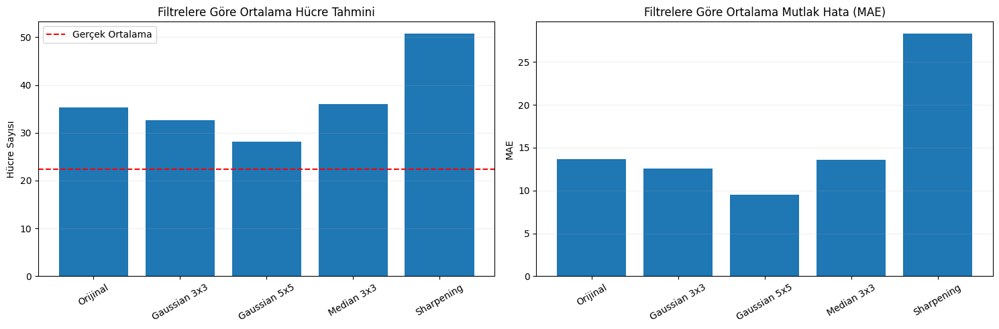

In [40]:

# BÖLÜM 7.3 - FİLTRELEME YÖNTEMLERİNİN KARŞILAŞTIRMA GRAFİĞİ

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Ortalama hücre tahminlerini karşılaştır.
axes[0].bar(
    filtre_ozet["method"],
    filtre_ozet["mean_prediction"]
)
axes[0].axhline(
    filtre_ozet["mean_ground_truth"].iloc[0],
    color="red",
    linestyle="--",
    label="Gerçek Ortalama"
)
axes[0].set_title("Filtrelere Göre Ortalama Hücre Tahmini")
axes[0].set_ylabel("Hücre Sayısı")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.2)

# MAE değerlerini karşılaştır.
axes[1].bar(
    filtre_ozet["method"],
    filtre_ozet["MAE"]
)
axes[1].set_title("Filtrelere Göre Ortalama Mutlak Hata (MAE)")
axes[1].set_ylabel("MAE")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    os.path.join(rapor_klasoru, "13_filtreleme_yontem_karsilastirma.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


Bölüm 7 – Filtrelerin Hücre Sayımına Etkisi (dosya kontrolü)

In [71]:
import os

print("Filtreleme ile ilgili dosyalar:")

for dosya in sorted(os.listdir(rapor_klasoru)):
    if "filtre" in dosya.lower() or "filter" in dosya.lower():
        print(dosya)

Filtreleme ile ilgili dosyalar:
12_filtre_gorsel_karsilastirma.png
13_filtreleme_yontem_karsilastirma.png


8. Bölüm – Segmentasyon Yöntemlerinin Görsel Karşılaştırılması

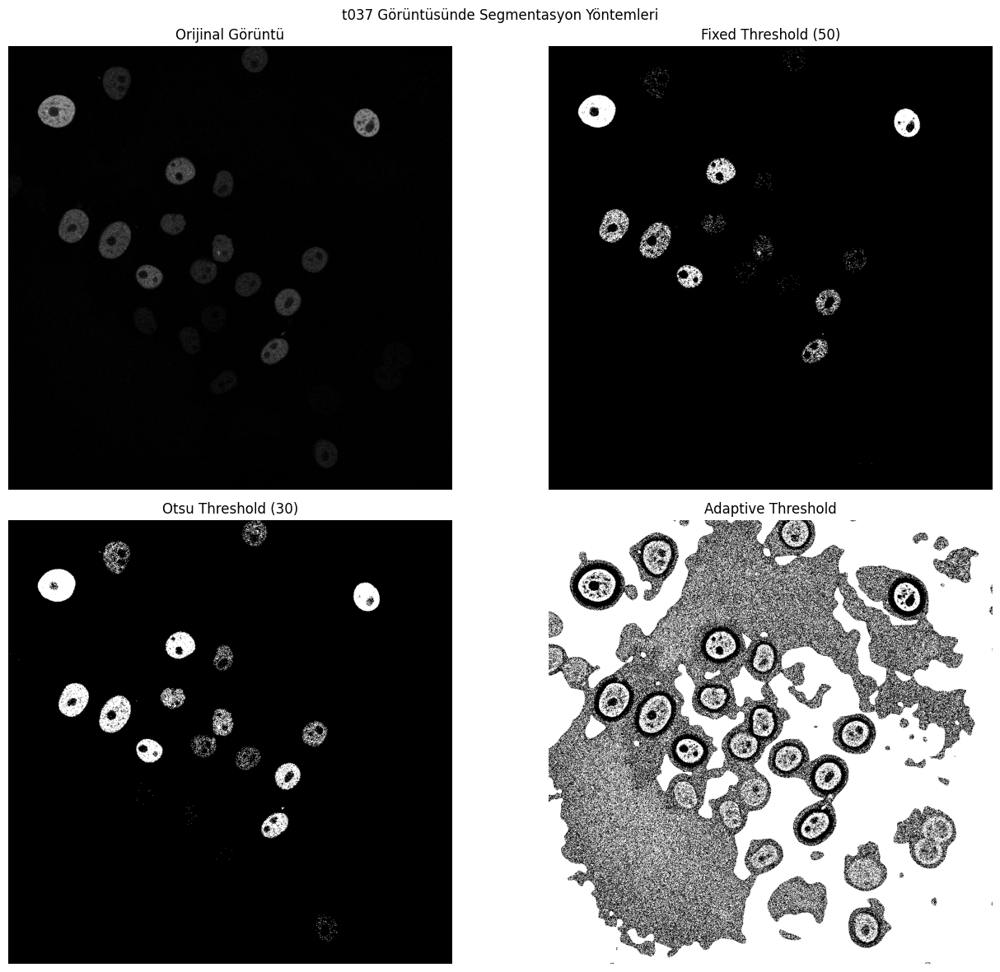

Fixed Threshold: 50
Otsu Threshold: 30.0


In [41]:

# BÖLÜM 8.1 - SEGMENTASYON YÖNTEMLERİNİN GÖRSEL KARŞILAŞTIRMASI

# Sabit eşikleme için eşik değeri.
sabit_esik = 50

# 1. Fixed Threshold (Sabit Eşikleme)
_, sabit_segmentasyon = cv2.threshold(
    ornek,
    sabit_esik,
    255,
    cv2.THRESH_BINARY
)

# 2. Otsu Thresholding (Otsu Eşikleme)
otsu_esik, otsu_segmentasyon = cv2.threshold(
    ornek,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 3. Adaptive Thresholding (Adaptif Eşikleme)
adaptif_segmentasyon = cv2.adaptiveThreshold(
    ornek,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    51,
    2
)

# Orijinal görüntü ve üç segmentasyon sonucunu karşılaştır.
segmentasyonlar = [
    (ornek, "Orijinal Görüntü"),
    (sabit_segmentasyon, f"Fixed Threshold ({sabit_esik})"),
    (otsu_segmentasyon, f"Otsu Threshold ({otsu_esik:.0f})"),
    (adaptif_segmentasyon, "Adaptive Threshold")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (goruntu, baslik) in zip(axes.ravel(), segmentasyonlar):
    ax.imshow(goruntu, cmap="gray")
    ax.set_title(baslik)
    ax.axis("off")

plt.suptitle("t037 Görüntüsünde Segmentasyon Yöntemleri")
plt.tight_layout()

# Karşılaştırma görselini rapor klasörüne kaydet.
plt.savefig(
    os.path.join(
        rapor_klasoru,
        "14_segmentasyon_gorsel_karsilastirma.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Kullanılan eşik değerini ekrana yazdır.
print("Fixed Threshold:", sabit_esik)
print("Otsu Threshold:", otsu_esik)


Bölüm 8 – Segmentasyon Yöntemlerinin Sayısal Karşılaştırılmas

In [42]:

# BÖLÜM 8.2 - SEGMENTASYON YÖNTEMLERİNİN SAYISAL KARŞILAŞTIRILMASI

# Development görüntülerini ve gerçek hücre sayılarını hazırla.
secimler = pd.read_csv("/content/selected_frames.csv")
ground_truth_df = pd.read_csv("/content/ground_truth_counts.csv")

development = secimler[
    secimler["group"] == "development"
].copy()

development = development.merge(
    ground_truth_df[
        ["sequence", "frame_index", "image_file", "ground_truth_count"]
    ],
    on=["sequence", "frame_index", "image_file"],
    how="left"
)

# Deney sonuçlarını saklamak için liste.
segmentasyon_sonuclari = []

# Her development görüntüsünü işle.
for _, satir in development.iterrows():

    klasor = f"{int(satir['sequence']):02d}"
    goruntu_yolu = (
        f"/content/Fluo-N2DH-GOWT1/{klasor}/{satir['image_file']}"
    )

    goruntu = cv2.imread(goruntu_yolu, cv2.IMREAD_GRAYSCALE)

    if goruntu is None:
        raise FileNotFoundError(goruntu_yolu)

    # 1. Sabit eşikleme.
    _, fixed = cv2.threshold(
        goruntu, 50, 255, cv2.THRESH_BINARY
    )

    # 2. Otsu eşikleme.
    _, otsu = cv2.threshold(
        goruntu, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # 3. Adaptif eşikleme.
    adaptive = cv2.adaptiveThreshold(
        goruntu, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        51, 2
    )

    yontemler = {
        "Fixed Threshold": fixed,
        "Otsu Threshold": otsu,
        "Adaptive Threshold": adaptive
    }

    # Her yöntemin bağlı bileşenlerini say.
    for yontem, ikili in yontemler.items():

        adet, etiketler, istatistikler, merkezler = (
            cv2.connectedComponentsWithStats(
                ikili, connectivity=8
            )
        )

        # Arka planı sayma; 20 pikselden küçük bileşenleri ele.
        tahmin = sum(
            1 for alan in istatistikler[1:, cv2.CC_STAT_AREA]
            if alan >= 20
        )

        gercek = int(satir["ground_truth_count"])

        segmentasyon_sonuclari.append({
            "image_file": satir["image_file"],
            "method": yontem,
            "ground_truth": gercek,
            "prediction": tahmin,
            "absolute_error": abs(tahmin - gercek)
        })

# Sonuç tablosu.
segmentasyon_df = pd.DataFrame(segmentasyon_sonuclari)

# Yöntemlerin ortalama performansını hesapla.
segmentasyon_ozet = (
    segmentasyon_df.groupby("method")
    .agg(
        mean_prediction=("prediction", "mean"),
        mean_ground_truth=("ground_truth", "mean"),
        MAE=("absolute_error", "mean")
    )
    .reindex([
        "Fixed Threshold",
        "Otsu Threshold",
        "Adaptive Threshold"
    ])
    .reset_index()
)

display(segmentasyon_ozet.round(2))

# Sonuçları CSV dosyalarına kaydet.
segmentasyon_df.to_csv(
    "/content/segmentasyon_deney_sonuclari.csv",
    index=False
)

segmentasyon_ozet.to_csv(
    "/content/segmentasyon_yontem_ozeti.csv",
    index=False
)


,method,mean_prediction,mean_ground_truth,MAE
0,Fixed Threshold,24.4,22.4,7.0
1,Otsu Threshold,35.3,22.4,13.7
2,Adaptive Threshold,109.7,22.4,87.3


Bölüm 8 – Segmentasyon Yöntemlerinin Grafiksel Karşılaştırılması

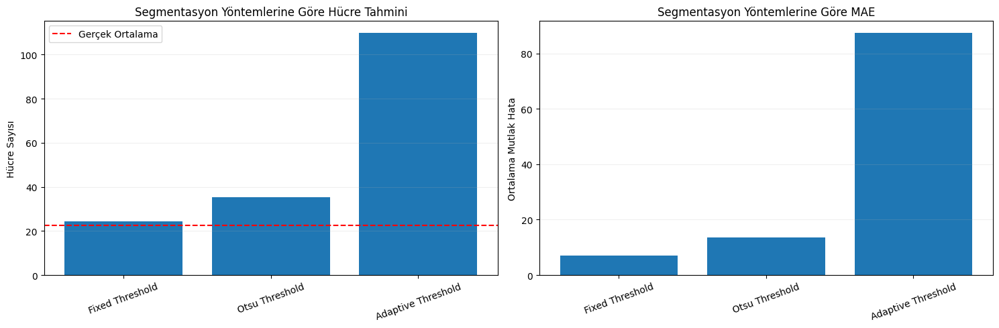

In [43]:

# BÖLÜM 8.3 - SEGMENTASYON YÖNTEMLERİNİN GRAFİKSEL KARŞILAŞTIRILMASI

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Ortalama hücre tahminlerini karşılaştır.
axes[0].bar(
    segmentasyon_ozet["method"],
    segmentasyon_ozet["mean_prediction"]
)

axes[0].axhline(
    segmentasyon_ozet["mean_ground_truth"].iloc[0],
    color="red",
    linestyle="--",
    label="Gerçek Ortalama"
)

axes[0].set_title("Segmentasyon Yöntemlerine Göre Hücre Tahmini")
axes[0].set_ylabel("Hücre Sayısı")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.2)

# MAE değerlerini karşılaştır.
axes[1].bar(
    segmentasyon_ozet["method"],
    segmentasyon_ozet["MAE"]
)

axes[1].set_title("Segmentasyon Yöntemlerine Göre MAE")
axes[1].set_ylabel("Ortalama Mutlak Hata")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    os.path.join(
        rapor_klasoru,
        "15_segmentasyon_yontem_karsilastirma.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


Bölüm 8 – Segmentasyon Yöntemleri (Dosya Kontrolü)

In [72]:
import os

print("Segmentasyon ile ilgili dosyalar:")

for dosya in sorted(os.listdir(rapor_klasoru)):
    if "segment" in dosya.lower() or "esik" in dosya.lower():
        print(dosya)

Segmentasyon ile ilgili dosyalar:
14_segmentasyon_gorsel_karsilastirma.png
15_segmentasyon_yontem_karsilastirma.png


Bölüm 9 – Temel Morfolojik İşlemler

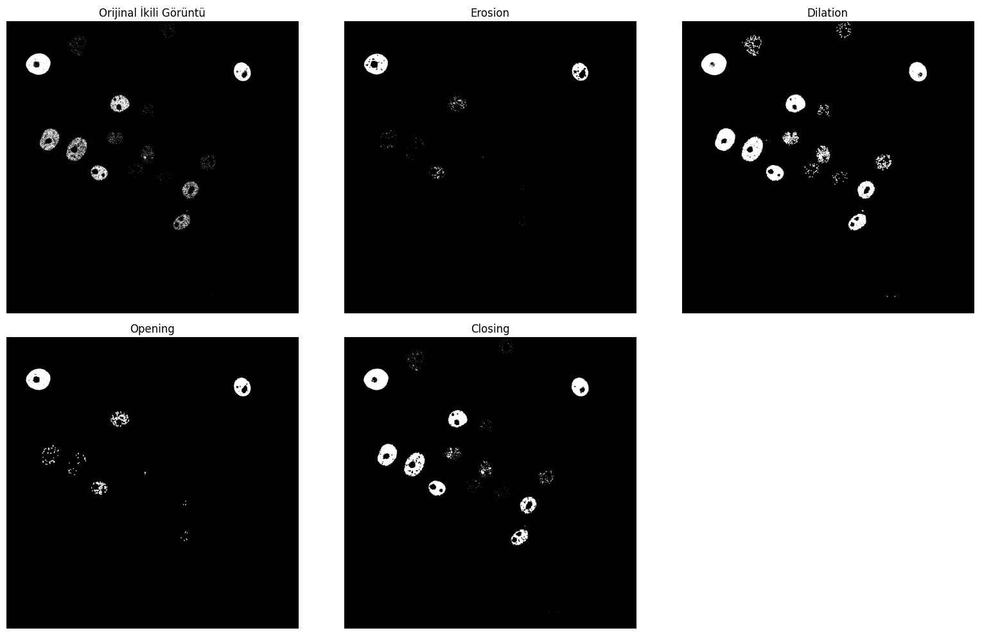

In [44]:

# Bölüm 9.1 - Temel Morfolojik İşlemler

# Orijinal görüntüye 50 eşik değeriyle sabit eşikleme uyguluyoruz.
_, ikili_goruntu = cv2.threshold(
    ornek, 50, 255, cv2.THRESH_BINARY
)

# 3x3 boyutunda dikdörtgen yapısal eleman oluşturuyoruz.
kernel_3 = cv2.getStructuringElement(
    cv2.MORPH_RECT, (3, 3)
)

# Dört temel morfolojik işlemi uyguluyoruz.
erosion = cv2.erode(ikili_goruntu, kernel_3, iterations=1)
dilation = cv2.dilate(ikili_goruntu, kernel_3, iterations=1)
opening = cv2.morphologyEx(
    ikili_goruntu, cv2.MORPH_OPEN, kernel_3
)
closing = cv2.morphologyEx(
    ikili_goruntu, cv2.MORPH_CLOSE, kernel_3
)

# Sonuçları görsel olarak karşılaştırıyoruz.
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

goruntuler = [
    ("Orijinal İkili Görüntü", ikili_goruntu),
    ("Erosion", erosion),
    ("Dilation", dilation),
    ("Opening", opening),
    ("Closing", closing)
]

for ax, (baslik, goruntu) in zip(axes.flat, goruntuler):
    ax.imshow(goruntu, cmap="gray")
    ax.set_title(baslik)
    ax.axis("off")

# Son hücreyi boş bırakıyoruz.
axes.flat[5].axis("off")

plt.tight_layout()

# Görseli rapor klasörüne kaydediyoruz.
plt.savefig(
    "/content/rapor_gorselleri/16_morfolojik_temel_islemler.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Bölüm 9 – Kernel Boyutu Karşılaştırması

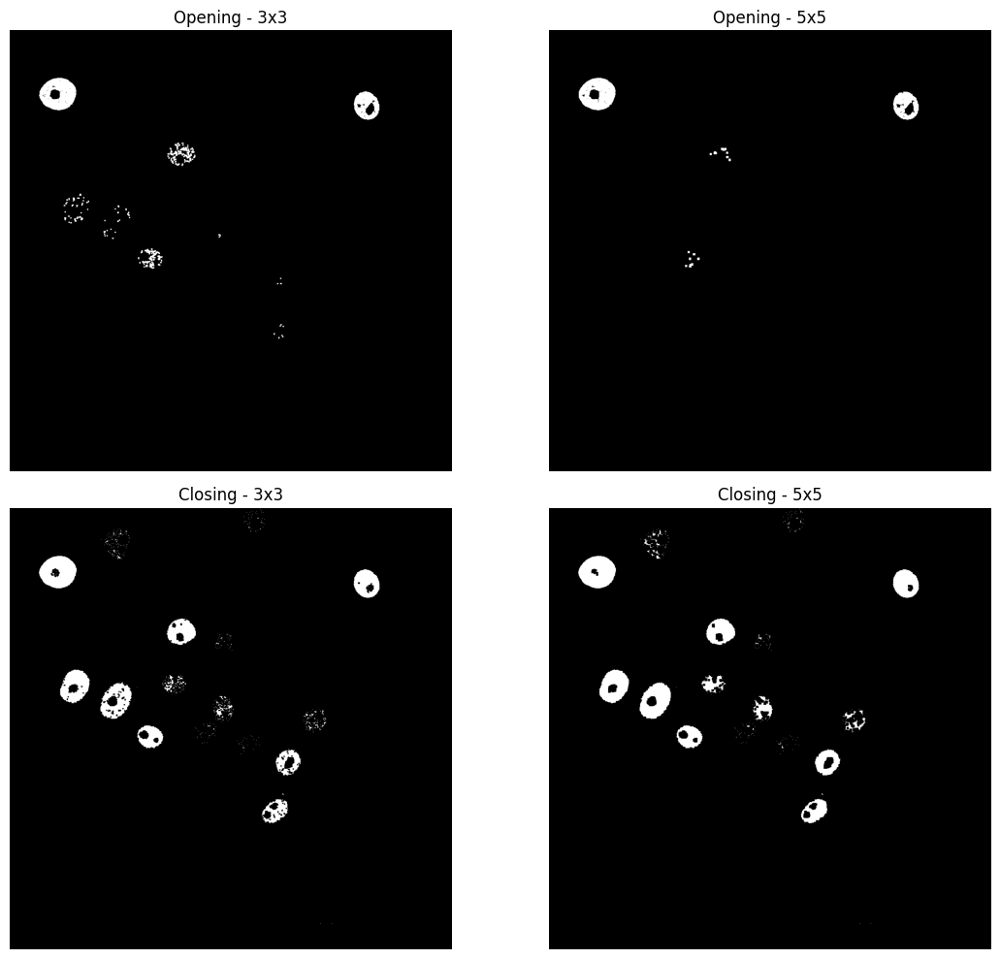

In [45]:

# Bölüm 9.2 - Kernel Boyutu Karşılaştırması

# 3x3 ve 5x5 yapısal elemanları oluşturuyoruz.
kernel_3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
kernel_5 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

# 3x3 kernel ile morfolojik işlemler
opening_3 = cv2.morphologyEx(
    ikili_goruntu, cv2.MORPH_OPEN, kernel_3
)
closing_3 = cv2.morphologyEx(
    ikili_goruntu, cv2.MORPH_CLOSE, kernel_3
)

# 5x5 kernel ile morfolojik işlemler
opening_5 = cv2.morphologyEx(
    ikili_goruntu, cv2.MORPH_OPEN, kernel_5
)
closing_5 = cv2.morphologyEx(
    ikili_goruntu, cv2.MORPH_CLOSE, kernel_5
)

# Sonuçları karşılaştırmalı gösteriyoruz.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sonuclar = [
    ("Opening - 3x3", opening_3),
    ("Opening - 5x5", opening_5),
    ("Closing - 3x3", closing_3),
    ("Closing - 5x5", closing_5)
]

for ax, (baslik, goruntu) in zip(axes.flat, sonuclar):
    ax.imshow(goruntu, cmap="gray")
    ax.set_title(baslik)
    ax.axis("off")

plt.tight_layout()

# Görseli rapor klasörüne kaydediyoruz.
plt.savefig(
    "/content/rapor_gorselleri/17_kernel_boyutu_karsilastirma.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Bölüm 9 – Morfolojik İşlem Sırası Karşılaştırması

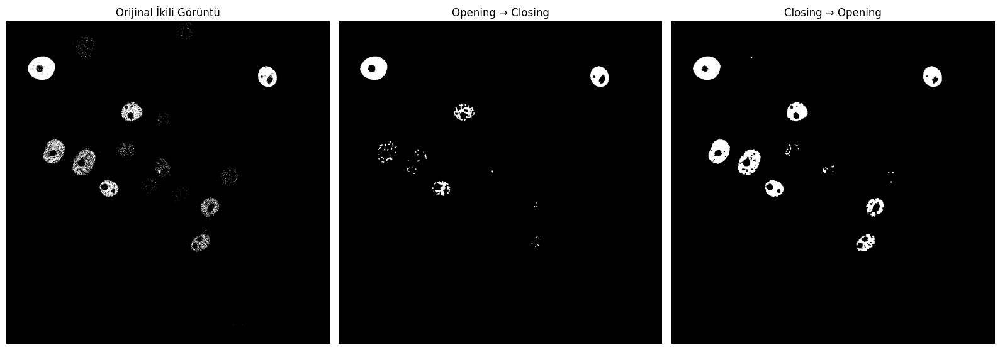

In [46]:

# Bölüm 9.3 - Morfolojik İşlem Sırası Karşılaştırması

# 3x3 kernel kullanıyoruz.
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# İlk sıra: Önce Opening, ardından Closing.
opening_then_closing = cv2.morphologyEx(
    ikili_goruntu, cv2.MORPH_OPEN, kernel
)
opening_then_closing = cv2.morphologyEx(
    opening_then_closing, cv2.MORPH_CLOSE, kernel
)

# İkinci sıra: Önce Closing, ardından Opening.
closing_then_opening = cv2.morphologyEx(
    ikili_goruntu, cv2.MORPH_CLOSE, kernel
)
closing_then_opening = cv2.morphologyEx(
    closing_then_opening, cv2.MORPH_OPEN, kernel
)

# Sonuçları görsel olarak karşılaştırıyoruz.
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

goruntuler = [
    ("Orijinal İkili Görüntü", ikili_goruntu),
    ("Opening → Closing", opening_then_closing),
    ("Closing → Opening", closing_then_opening)
]

for ax, (baslik, goruntu) in zip(axes, goruntuler):
    ax.imshow(goruntu, cmap="gray")
    ax.set_title(baslik)
    ax.axis("off")

plt.tight_layout()

# Görseli rapor klasörüne kaydediyoruz.
plt.savefig(
    "/content/rapor_gorselleri/18_morfolojik_islem_sirasi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Bölüm 9 – Morfolojik İşlem Sonuçlarının Sayılması

In [47]:

# Bölüm 9.4 - Morfolojik İşlem Sonuçlarının Sayılması

# Karşılaştıracağımız görüntüleri bir araya getiriyoruz.
morfolojik_sonuclar = {
    "Orijinal": ikili_goruntu,
    "Opening 3x3": opening_3,
    "Closing 3x3": closing_3,
    "Opening -> Closing": opening_then_closing,
    "Closing -> Opening": closing_then_opening
}

# Her görüntüdeki bağlı bileşenleri sayıyoruz.
sayim_sonuclari = []

for yontem, goruntu in morfolojik_sonuclar.items():

    # Bağlı bileşen analizi uyguluyoruz.
    adet, etiketler, istatistikler, merkezler = (
        cv2.connectedComponentsWithStats(
            goruntu, connectivity=8
        )
    )

    # Arka planı hariç tutuyoruz.
    alanlar = istatistikler[1:, cv2.CC_STAT_AREA]

    # Alanı en az 20 piksel olan bileşenleri sayıyoruz.
    hucre_sayisi = np.sum(alanlar >= 20)

    sayim_sonuclari.append({
        "Yöntem": yontem,
        "Tahmini Bileşen Sayısı": int(hucre_sayisi)
    })

# Sonuçları tablo hâlinde gösteriyoruz.
morfoloji_df = pd.DataFrame(sayim_sonuclari)

display(morfoloji_df)

# Tabloyu CSV olarak kaydediyoruz.
morfoloji_df.to_csv(
    "/content/rapor_gorselleri/morfoloji_sayim_sonuclari.csv",
    index=False
)


,Yöntem,Tahmini Bileşen Sayısı
0,Orijinal,20
1,Opening 3x3,28
2,Closing 3x3,20
3,Opening -> Closing,23
4,Closing -> Opening,14


Bölüm 9– Morfolojik Yöntemlerin Geliştirme Verisinde Değerlendirilmesi

In [48]:

# Bölüm 9.5 - Morfolojik Yöntemlerin Geliştirme Verisinde Değerlendirilmesi

# İki farklı kernel boyutu oluşturuyoruz.
kernel_3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
kernel_5 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

# Karşılaştırılacak yöntemleri tanımlıyoruz.
yontemler = {
    "Orijinal": None,
    "Opening 3x3": ("open", kernel_3),
    "Closing 3x3": ("close", kernel_3),
    "Opening 5x5": ("open", kernel_5),
    "Closing 5x5": ("close", kernel_5),
    "Opening -> Closing": ("open_close", kernel_3),
    "Closing -> Opening": ("close_open", kernel_3)
}

sonuclar = []

# Geliştirme grubundaki 10 görüntüyü tek tek inceliyoruz.
for _, satir in development.iterrows():

    # Görüntü yolunu oluşturuyoruz.
    sira = int(satir["sequence"])
    dosya = satir["image_file"]
    yol = f"/content/Fluo-N2DH-GOWT1/{sira:02d}/{dosya}"

    # Görüntüyü gri tonlamalı okuyoruz.
    goruntu = cv2.imread(yol, cv2.IMREAD_GRAYSCALE)

    # Sabit eşikleme uyguluyoruz.
    _, ikili = cv2.threshold(
        goruntu, 50, 255, cv2.THRESH_BINARY
    )

    gercek_sayi = int(satir["ground_truth_count"])

    for yontem, ayar in yontemler.items():

        # Orijinal görüntü veya morfolojik işlem.
        if ayar is None:
            islenmis = ikili.copy()

        elif ayar[0] == "open":
            islenmis = cv2.morphologyEx(
                ikili, cv2.MORPH_OPEN, ayar[1]
            )

        elif ayar[0] == "close":
            islenmis = cv2.morphologyEx(
                ikili, cv2.MORPH_CLOSE, ayar[1]
            )

        elif ayar[0] == "open_close":
            islenmis = cv2.morphologyEx(
                ikili, cv2.MORPH_OPEN, ayar[1]
            )
            islenmis = cv2.morphologyEx(
                islenmis, cv2.MORPH_CLOSE, ayar[1]
            )

        elif ayar[0] == "close_open":
            islenmis = cv2.morphologyEx(
                ikili, cv2.MORPH_CLOSE, ayar[1]
            )
            islenmis = cv2.morphologyEx(
                islenmis, cv2.MORPH_OPEN, ayar[1]
            )

        # Bağlı bileşenleri sayıyoruz.
        adet, etiketler, istatistikler, merkezler = (
            cv2.connectedComponentsWithStats(
                islenmis, connectivity=8
            )
        )

        # 20 pikselden küçük bileşenleri sayım dışında bırakıyoruz.
        alanlar = istatistikler[1:, cv2.CC_STAT_AREA]
        tahmin = int(np.sum(alanlar >= 20))

        sonuclar.append({
            "image_file": dosya,
            "Yöntem": yontem,
            "Gerçek Hücre Sayısı": gercek_sayi,
            "Tahmini Hücre Sayısı": tahmin,
            "Mutlak Hata": abs(gercek_sayi - tahmin)
        })

# Sonuçları tabloya dönüştürüyoruz.
morfoloji_deney_df = pd.DataFrame(sonuclar)

# Yöntemlerin ortalama hata değerlerini hesaplıyoruz.
morfoloji_ozet = (
    morfoloji_deney_df
    .groupby("Yöntem")
    .agg(
        Ortalama_Tahmin=("Tahmini Hücre Sayısı", "mean"),
        Ortalama_Gercek=("Gerçek Hücre Sayısı", "mean"),
        MAE=("Mutlak Hata", "mean")
    )
    .reset_index()
    .sort_values("MAE")
)

display(morfoloji_ozet.round(2))

# Ayrıntılı ve özet sonuçları kaydediyoruz.
morfoloji_deney_df.to_csv(
    "/content/rapor_gorselleri/morfoloji_gelistirme_sonuclari.csv",
    index=False
)

morfoloji_ozet.to_csv(
    "/content/rapor_gorselleri/morfoloji_yontem_ozeti.csv",
    index=False
)


,Yöntem,Ortalama_Tahmin,Ortalama_Gercek,MAE
2,Closing 5x5,22.9,22.4,4.7
3,Opening -> Closing,24.9,22.4,5.9
6,Orijinal,24.4,22.4,7.0
1,Closing 3x3,20.5,22.4,7.3
5,Opening 5x5,15.2,22.4,7.4
0,Closing -> Opening,21.1,22.4,7.9
4,Opening 3x3,34.0,22.4,13.2


Bölüm 9 – Erosion ve Dilation işlemlerinin sayısal değerlendirilmesi

In [49]:

# Erosion ve Dilation işlemlerini 10 geliştirme görüntüsünde değerlendiriyoruz.

ek_sonuclar = []

for _, satir in development.iterrows():

    sira = int(satir["sequence"])
    dosya = satir["image_file"]
    yol = f"/content/Fluo-N2DH-GOWT1/{sira:02d}/{dosya}"

    goruntu = cv2.imread(yol, cv2.IMREAD_GRAYSCALE)

    _, ikili = cv2.threshold(
        goruntu, 50, 255, cv2.THRESH_BINARY
    )

    gercek = int(satir["ground_truth_count"])

    for yontem, islenmis in [
        ("Erosion 3x3", cv2.erode(ikili, kernel_3, iterations=1)),
        ("Dilation 3x3", cv2.dilate(ikili, kernel_3, iterations=1))
    ]:

        adet, etiketler, istatistikler, merkezler = (
            cv2.connectedComponentsWithStats(
                islenmis, connectivity=8
            )
        )

        alanlar = istatistikler[1:, cv2.CC_STAT_AREA]
        tahmin = int(np.sum(alanlar >= 20))

        ek_sonuclar.append({
            "image_file": dosya,
            "Yöntem": yontem,
            "Gerçek Hücre Sayısı": gercek,
            "Tahmini Hücre Sayısı": tahmin,
            "Mutlak Hata": abs(gercek - tahmin)
        })

erosion_dilation_df = pd.DataFrame(ek_sonuclar)

erosion_dilation_ozet = (
    erosion_dilation_df
    .groupby("Yöntem")
    .agg(
        Ortalama_Tahmin=("Tahmini Hücre Sayısı", "mean"),
        Ortalama_Gercek=("Gerçek Hücre Sayısı", "mean"),
        MAE=("Mutlak Hata", "mean")
    )
    .reset_index()
)

display(erosion_dilation_ozet.round(2))


,Yöntem,Ortalama_Tahmin,Ortalama_Gercek,MAE
0,Dilation 3x3,47.6,22.4,25.2
1,Erosion 3x3,14.2,22.4,8.2


Bölüm 9 – Tüm Morfolojik Yöntemlerin Birleştirilmesi

,Yöntem,Ortalama_Tahmin,Ortalama_Gercek,MAE
2,Closing 5x5,22.9,22.4,4.7
5,Opening -> Closing,24.9,22.4,5.9
8,Orijinal,24.4,22.4,7.0
1,Closing 3x3,20.5,22.4,7.3
7,Opening 5x5,15.2,22.4,7.4
0,Closing -> Opening,21.1,22.4,7.9
4,Erosion 3x3,14.2,22.4,8.2
6,Opening 3x3,34.0,22.4,13.2
3,Dilation 3x3,47.6,22.4,25.2


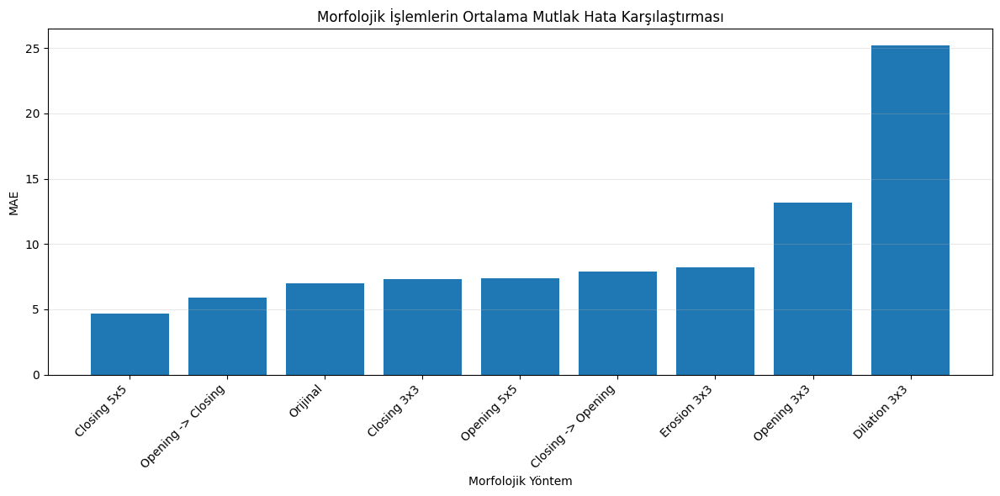

In [50]:

# Bölüm 9.7 - Tüm Morfolojik Yöntemlerin Birleştirilmesi

# Önceki morfoloji sonuçlarıyla Erosion/Dilation sonuçlarını birleştiriyoruz.
tum_morfoloji = pd.concat(
    [morfoloji_deney_df, erosion_dilation_df],
    ignore_index=True
)

# Her yöntemin ortalama tahminini ve MAE değerini hesaplıyoruz.
tum_morfoloji_ozet = (
    tum_morfoloji
    .groupby("Yöntem")
    .agg(
        Ortalama_Tahmin=("Tahmini Hücre Sayısı", "mean"),
        Ortalama_Gercek=("Gerçek Hücre Sayısı", "mean"),
        MAE=("Mutlak Hata", "mean")
    )
    .reset_index()
    .sort_values("MAE")
)

display(tum_morfoloji_ozet.round(2))

# Sonuç tablosunu CSV olarak kaydediyoruz.
tum_morfoloji_ozet.to_csv(
    "/content/rapor_gorselleri/19_tum_morfoloji_sonuclari.csv",
    index=False
)

# MAE değerlerini grafik üzerinde karşılaştırıyoruz.
plt.figure(figsize=(12, 6))

plt.bar(
    tum_morfoloji_ozet["Yöntem"],
    tum_morfoloji_ozet["MAE"]
)

plt.title("Morfolojik İşlemlerin Ortalama Mutlak Hata Karşılaştırması")
plt.xlabel("Morfolojik Yöntem")
plt.ylabel("MAE")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Grafiği rapor klasörüne kaydediyoruz.
plt.savefig(
    "/content/rapor_gorselleri/19_morfoloji_mae_karsilastirma.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Bölüm 9 – Morfolojik İşlemler (Dosya Kontrol)

In [73]:
import os

print("Morfolojik işlem dosyaları:")

for dosya in sorted(os.listdir(rapor_klasoru)):
    if "morfoloji" in dosya.lower() or "morfolojik" in dosya.lower():
        print(dosya)

Morfolojik işlem dosyaları:
16_morfolojik_temel_islemler.png
18_morfolojik_islem_sirasi.png
19_morfoloji_mae_karsilastirma.png
19_tum_morfoloji_sonuclari.csv
morfoloji_gelistirme_sonuclari.csv
morfoloji_sayim_sonuclari.csv
morfoloji_yontem_ozeti.csv


Bölüm 10 – Önceki Deneylerin Kontrolü

In [52]:

# Bölüm 10.1 - Önceki Deneylerin Kontrolü

# Önceki bölümlerde oluşturduğumuz deney tablolarını kontrol ediyoruz.
deney_tablolari = {
    "Yoğunluk Dönüşümleri": yogunluk_df,
    "Filtreleme": filtre_df,
    "Segmentasyon": segmentasyon_df,
    "Morfoloji": morfoloji_deney_df,
    "Erosion ve Dilation": erosion_dilation_df
}

for ad, tablo in deney_tablolari.items():
    print("\n", "=" * 50)
    print(ad)
    print("Satır sayısı:", len(tablo))
    print("Sütunlar:", tablo.columns.tolist())
    print("Deney yöntemleri:", tablo.iloc[:, 0].unique())



Yoğunluk Dönüşümleri
Satır sayısı: 40
Sütunlar: ['sequence', 'frame_index', 'image_file', 'method', 'ground_truth', 'prediction', 'absolute_error']
Deney yöntemleri: [1]

Filtreleme
Satır sayısı: 50
Sütunlar: ['image_file', 'method', 'ground_truth', 'prediction', 'absolute_error']
Deney yöntemleri: ['t008.tif' 't013.tif' 't019.tif' 't037.tif' 't045.tif' 't048.tif'
 't057.tif' 't062.tif' 't071.tif' 't083.tif']

Segmentasyon
Satır sayısı: 30
Sütunlar: ['image_file', 'method', 'ground_truth', 'prediction', 'absolute_error']
Deney yöntemleri: ['t008.tif' 't013.tif' 't019.tif' 't037.tif' 't045.tif' 't048.tif'
 't057.tif' 't062.tif' 't071.tif' 't083.tif']

Morfoloji
Satır sayısı: 70
Sütunlar: ['image_file', 'Yöntem', 'Gerçek Hücre Sayısı', 'Tahmini Hücre Sayısı', 'Mutlak Hata']
Deney yöntemleri: ['t008.tif' 't013.tif' 't019.tif' 't037.tif' 't045.tif' 't048.tif'
 't057.tif' 't062.tif' 't071.tif' 't083.tif']

Erosion ve Dilation
Satır sayısı: 20
Sütunlar: ['image_file', 'Yöntem', 'Gerçek Hücr

Bölüm 10 – Önceki Deneylerin ve Yöntemlerin Kontrol Edilmesi

In [53]:
# Bölüm 10.1 - Deney yöntemlerini doğru sütunlardan kontrol etme

deney_tablolari = {
    "Yoğunluk Dönüşümleri": (yogunluk_df, "method"),
    "Filtreleme": (filtre_df, "method"),
    "Segmentasyon": (segmentasyon_df, "method"),
    "Morfoloji": (morfoloji_deney_df, "Yöntem"),
    "Erosion ve Dilation": (erosion_dilation_df, "Yöntem")
}

toplam_deney = 0

for ad, (tablo, yontem_sutunu) in deney_tablolari.items():
    yontemler = tablo[yontem_sutunu].unique()

    print("\n" + "=" * 50)
    print(ad)
    print("Toplam kayıt:", len(tablo))
    print("Farklı yöntem/konfigürasyon sayısı:", len(yontemler))

    for yontem in yontemler:
        print("-", yontem)

    toplam_deney += len(yontemler)

print("\n" + "=" * 50)
print("Toplam yöntem/konfigürasyon sayısı:", toplam_deney)


Yoğunluk Dönüşümleri
Toplam kayıt: 40
Farklı yöntem/konfigürasyon sayısı: 4
- Orijinal
- Contrast Stretching
- Histogram Equalization
- CLAHE

Filtreleme
Toplam kayıt: 50
Farklı yöntem/konfigürasyon sayısı: 5
- Orijinal
- Gaussian 3x3
- Gaussian 5x5
- Median 3x3
- Sharpening

Segmentasyon
Toplam kayıt: 30
Farklı yöntem/konfigürasyon sayısı: 3
- Fixed Threshold
- Otsu Threshold
- Adaptive Threshold

Morfoloji
Toplam kayıt: 70
Farklı yöntem/konfigürasyon sayısı: 7
- Orijinal
- Opening 3x3
- Closing 3x3
- Opening 5x5
- Closing 5x5
- Opening -> Closing
- Closing -> Opening

Erosion ve Dilation
Toplam kayıt: 20
Farklı yöntem/konfigürasyon sayısı: 2
- Erosion 3x3
- Dilation 3x3

Toplam yöntem/konfigürasyon sayısı: 21


Bölüm 10 – Üç Tam İşlem Hattının (Pipeline) Oluşturulması ve Test Edilmesi

PIPELINE PERFORMANS SONUÇLARI


,pipeline,MAE,Ortalama_Sure,RMSE
0,Pipeline A,3.9,0.1183,4.5056
1,Pipeline B,3.6,0.0602,4.0497
2,Pipeline C,8.4,0.0304,9.8387


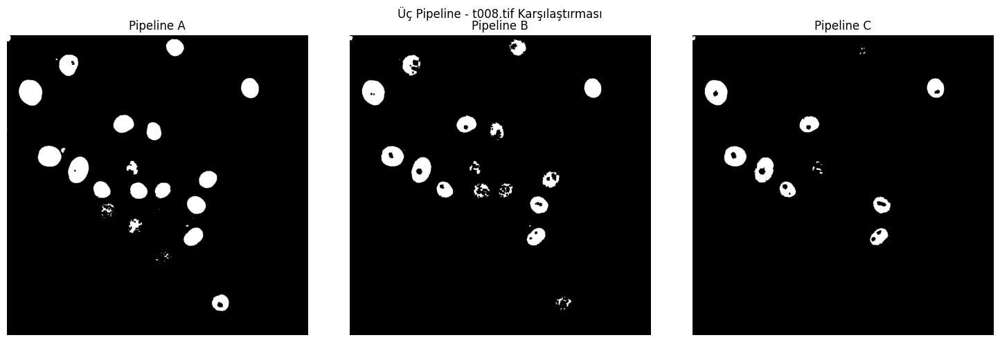

In [54]:

# Bölüm 10.2 - Üç tam işlem hattının oluşturulması ve test edilmesi

import time

# Pipeline A: Contrast Stretching -> Gaussian 5x5
# -> Sabit eşikleme -> Closing 5x5

# Pipeline B: CLAHE -> Median 3x3
# -> Otsu eşikleme -> Closing 5x5

# Pipeline C: Orijinal -> Gaussian 3x3
# -> Otsu eşikleme -> Opening -> Closing

def pipeline_islet(goruntu, pipeline_adi):

    # 1. Yoğunluk dönüşümü ve filtreleme
    if pipeline_adi == "Pipeline A":
        alt = np.percentile(goruntu, 1)
        ust = np.percentile(goruntu, 99)
        islenmis = np.clip(
            (goruntu.astype(np.float32) - alt) * 255 / (ust - alt + 1e-5),
            0, 255
        ).astype(np.uint8)

        islenmis = cv2.GaussianBlur(islenmis, (5, 5), 0)

    elif pipeline_adi == "Pipeline B":
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        islenmis = clahe.apply(goruntu)
        islenmis = cv2.medianBlur(islenmis, 3)

    else:
        islenmis = cv2.GaussianBlur(goruntu, (3, 3), 0)

    # 2. Segmentasyon
    if pipeline_adi == "Pipeline A":
        _, ikili = cv2.threshold(
            islenmis, 50, 255, cv2.THRESH_BINARY
        )
    else:
        _, ikili = cv2.threshold(
            islenmis, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

    # 3. Morfolojik işlemler
    if pipeline_adi in ["Pipeline A", "Pipeline B"]:
        kernel = np.ones((5, 5), np.uint8)
        sonuc = cv2.morphologyEx(
            ikili, cv2.MORPH_CLOSE, kernel
        )
    else:
        kernel = np.ones((3, 3), np.uint8)
        acilmis = cv2.morphologyEx(
            ikili, cv2.MORPH_OPEN, kernel
        )
        sonuc = cv2.morphologyEx(
            acilmis, cv2.MORPH_CLOSE, kernel
        )

    # 4. Bağlantılı bileşenlerle hücre sayımı
    adet, etiketler, istatistikler, merkezler = (
        cv2.connectedComponentsWithStats(sonuc, 8)
    )

    tahmin = sum(
        1 for alan in istatistikler[1:, cv2.CC_STAT_AREA]
        if alan >= 20
    )

    return tahmin, sonuc


# Geliştirme görüntülerini kullanıyoruz.
pipeline_sonuclari = []
pipeline_gorselleri = {}

for pipeline_adi in ["Pipeline A", "Pipeline B", "Pipeline C"]:

    for _, satir in baseline_df.iterrows():

        # Görüntü yolunu oluştur
        klasor = f"{int(satir['sequence']):02d}"
        yol = f"/content/Fluo-N2DH-GOWT1/{klasor}/{satir['image_file']}"

        goruntu = cv2.imread(yol, cv2.IMREAD_GRAYSCALE)

        # İşlem süresini ölç
        baslangic = time.perf_counter()
        tahmin, ikili_sonuc = pipeline_islet(
            goruntu, pipeline_adi
        )
        sure = time.perf_counter() - baslangic

        gercek = int(satir["ground_truth"])

        pipeline_sonuclari.append({
            "pipeline": pipeline_adi,
            "image_file": satir["image_file"],
            "ground_truth": gercek,
            "prediction": tahmin,
            "absolute_error": abs(gercek - tahmin),
            "squared_error": (gercek - tahmin) ** 2,
            "time_seconds": sure
        })

        # İlk görüntünün sonuçlarını görselleştirmek için sakla
        if satir["image_file"] == "t008.tif":
            pipeline_gorselleri[pipeline_adi] = ikili_sonuc


# Sonuçları tabloya aktar
pipeline_df = pd.DataFrame(pipeline_sonuclari)

# Her pipeline için performans ölçümleri
pipeline_ozet = pipeline_df.groupby("pipeline").agg(
    MAE=("absolute_error", "mean"),
    MSE=("squared_error", "mean"),
    Ortalama_Sure=("time_seconds", "mean")
).reset_index()

pipeline_ozet["RMSE"] = np.sqrt(pipeline_ozet["MSE"])
pipeline_ozet = pipeline_ozet.drop(columns=["MSE"])

print("PIPELINE PERFORMANS SONUÇLARI")
display(pipeline_ozet.round(4))

# Sonuçları kaydet
pipeline_df.to_csv(
    "/content/rapor_gorselleri/pipeline_deney_sonuclari.csv",
    index=False
)

pipeline_ozet.to_csv(
    "/content/rapor_gorselleri/pipeline_performans_ozeti.csv",
    index=False
)

# İlk geliştirme görüntüsü için pipeline çıktıları
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (adi, sonuc) in zip(axes, pipeline_gorselleri.items()):
    ax.imshow(sonuc, cmap="gray")
    ax.set_title(adi)
    ax.axis("off")

plt.suptitle("Üç Pipeline - t008.tif Karşılaştırması")
plt.tight_layout()

plt.savefig(
    "/content/rapor_gorselleri/20_pipeline_gorsel_karsilastirma.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Bölüm 10 – Doğrulama Verilerinin Hazırlanması

In [55]:
# Bölüm 10.3.1 - Doğrulama verilerini hazırlama

secimler = pd.read_csv("/content/selected_frames.csv")
gercek_sayilar = pd.read_csv("/content/ground_truth_counts.csv")

print("Seçim dosyasının sütunları:")
print(secimler.columns.tolist())

print("\nGerçek hücre sayıları dosyasının sütunları:")
print(gercek_sayilar.columns.tolist())

print("\nDoğrulama görüntüleri:")
display(secimler[secimler["group"] == "validation"])

print("\nGerçek hücre sayıları:")
display(gercek_sayilar)

Seçim dosyasının sütunları:
['sequence', 'frame_index', 'image_file', 'group']

Gerçek hücre sayıları dosyasının sütunları:
['sequence', 'frame_index', 'image_file', 'group', 'ground_truth_count']

Doğrulama görüntüleri:


,sequence,frame_index,image_file,group
10,1,0,t000.tif,validation
11,1,26,t026.tif,validation
12,1,28,t028.tif,validation
13,1,31,t031.tif,validation
14,1,90,t090.tif,validation



Gerçek hücre sayıları:


,sequence,frame_index,image_file,group,ground_truth_count
0,1,8,t008.tif,development,23
1,1,13,t013.tif,development,23
2,1,19,t019.tif,development,23
3,1,37,t037.tif,development,24
4,1,45,t045.tif,development,24
5,1,48,t048.tif,development,24
6,1,57,t057.tif,development,21
7,1,62,t062.tif,development,21
8,1,71,t071.tif,development,21
9,1,83,t083.tif,development,20


Bölüm 10 – Üç Pipeline'ın Doğrulama Görüntülerinde Değerlendirilmesi

In [56]:

# Bölüm 10.3.2 - Üç pipeline'ın doğrulama görüntülerinde değerlendirilmesi

# Doğrulama görüntülerini seç
validation_df = gercek_sayilar[
    gercek_sayilar["group"] == "validation"
].copy()

validation_sonuclari = []

for pipeline_adi in ["Pipeline A", "Pipeline B", "Pipeline C"]:

    for _, satir in validation_df.iterrows():

        klasor = f"{int(satir['sequence']):02d}"
        yol = (
            f"/content/Fluo-N2DH-GOWT1/"
            f"{klasor}/{satir['image_file']}"
        )

        goruntu = cv2.imread(yol, cv2.IMREAD_GRAYSCALE)

        baslangic = time.perf_counter()

        tahmin, ikili_sonuc = pipeline_islet(
            goruntu, pipeline_adi
        )

        sure = time.perf_counter() - baslangic

        gercek = int(satir["ground_truth_count"])
        hata = tahmin - gercek

        validation_sonuclari.append({
            "pipeline": pipeline_adi,
            "image_file": satir["image_file"],
            "ground_truth": gercek,
            "prediction": tahmin,
            "error": hata,
            "absolute_error": abs(hata),
            "squared_error": hata ** 2,
            "time_seconds": sure
        })

# Sonuç tablosu
validation_pipeline_df = pd.DataFrame(validation_sonuclari)

# Pipeline bazında performans ölçümleri
validation_ozet = validation_pipeline_df.groupby(
    "pipeline"
).agg(
    MAE=("absolute_error", "mean"),
    MSE=("squared_error", "mean"),
    Bias=("error", "mean"),
    Ortalama_Sure=("time_seconds", "mean")
).reset_index()

validation_ozet["RMSE"] = np.sqrt(validation_ozet["MSE"])
validation_ozet = validation_ozet.drop(columns=["MSE"])

print("DOĞRULAMA SONUÇLARI")
display(validation_ozet.round(4))

print("\nGörüntü bazında tahminler:")
display(
    validation_pipeline_df[
        ["pipeline", "image_file", "ground_truth",
         "prediction", "absolute_error"]
    ]
)

# CSV dosyalarını kaydet
validation_pipeline_df.to_csv(
    "/content/rapor_gorselleri/validation_pipeline_sonuclari.csv",
    index=False
)

validation_ozet.to_csv(
    "/content/rapor_gorselleri/validation_pipeline_ozeti.csv",
    index=False
)


DOĞRULAMA SONUÇLARI


,pipeline,MAE,Bias,Ortalama_Sure,RMSE
0,Pipeline A,1.6,0.0,0.1024,2.0000
1,Pipeline B,3.8,-2.6,0.0471,4.2661
2,Pipeline C,4.6,-1.4,0.0233,6.0498



Görüntü bazında tahminler:


,pipeline,image_file,ground_truth,prediction,absolute_error
0,Pipeline A,t000.tif,23,23,0
1,Pipeline A,t026.tif,24,25,1
2,Pipeline A,t028.tif,24,23,1
3,Pipeline A,t031.tif,24,21,3
4,Pipeline A,t090.tif,21,24,3
5,Pipeline B,t000.tif,23,25,2
6,Pipeline B,t026.tif,24,19,5
7,Pipeline B,t028.tif,24,18,6
8,Pipeline B,t031.tif,24,19,5
9,Pipeline B,t090.tif,21,22,1


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [57]:

# Bölüm 10.4 - Nihai pipeline ayarlarını JSON dosyasına kaydetme

import json

final_pipeline = {
    "pipeline_name": "Pipeline A",
    "selection_criterion": "Lowest validation MAE",
    "validation_metrics": {
        "MAE": 1.6,
        "RMSE": 2.0,
        "Bias": 0.0,
        "mean_time_seconds": 0.1024
    },
    "steps": {
        "grayscale": True,
        "contrast_stretching": {
            "lower_percentile": 1,
            "upper_percentile": 99
        },
        "gaussian_blur": {
            "kernel_size": [5, 5],
            "sigma": 0
        },
        "segmentation": {
            "method": "fixed_threshold",
            "threshold": 50
        },
        "morphology": {
            "operation": "closing",
            "kernel_size": [5, 5]
        },
        "connected_components": {
            "connectivity": 8,
            "minimum_area": 20
        }
    }
}

json_yolu = "/content/rapor_gorselleri/final_pipeline.json"

with open(json_yolu, "w", encoding="utf-8") as dosya:
    json.dump(final_pipeline, dosya, ensure_ascii=False, indent=4)

print("Nihai pipeline ayarları kaydedildi:")
print(json.dumps(final_pipeline, ensure_ascii=False, indent=4))


Nihai pipeline ayarları kaydedildi:
{
    "pipeline_name": "Pipeline A",
    "selection_criterion": "Lowest validation MAE",
    "validation_metrics": {
        "MAE": 1.6,
        "RMSE": 2.0,
        "Bias": 0.0,
        "mean_time_seconds": 0.1024
    },
    "steps": {
        "grayscale": true,
        "contrast_stretching": {
            "lower_percentile": 1,
            "upper_percentile": 99
        },
        "gaussian_blur": {
            "kernel_size": [
                5,
                5
            ],
            "sigma": 0
        },
        "segmentation": {
            "method": "fixed_threshold",
            "threshold": 50
        },
        "morphology": {
            "operation": "closing",
            "kernel_size": [
                5,
                5
            ]
        },
        "connected_components": {
            "connectivity": 8,
            "minimum_area": 20
        }
    }
}


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [79]:
import os

print("Deney dosyaları aranıyor:\n")

for kok, klasorler, dosyalar in os.walk("/content"):
    for dosya in dosyalar:
        if "experiment" in dosya.lower() or "deney" in dosya.lower():
            print(os.path.join(kok, dosya))

Deney dosyaları aranıyor:

/content/filtreleme_deney_sonuclari.csv
/content/segmentasyon_deney_sonuclari.csv
/content/rapor_gorselleri/pipeline_deney_sonuclari.csv


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [80]:
import pandas as pd

deney_df = pd.read_csv(
    "/content/rapor_gorselleri/pipeline_deney_sonuclari.csv"
)

print("Toplam kayıt sayısı:", len(deney_df))
print("\nSütunlar:")
print(deney_df.columns.tolist())

display(deney_df)

Toplam kayıt sayısı: 30

Sütunlar:
['pipeline', 'image_file', 'ground_truth', 'prediction', 'absolute_error', 'squared_error', 'time_seconds']


,pipeline,image_file,ground_truth,prediction,absolute_error,squared_error,time_seconds
0,Pipeline A,t008.tif,23,26,3,9,0.052182
1,Pipeline A,t013.tif,23,24,1,1,0.135878
2,Pipeline A,t019.tif,23,24,1,1,0.108378
3,Pipeline A,t037.tif,24,28,4,16,0.128395
4,Pipeline A,t045.tif,24,23,1,1,0.104944
5,Pipeline A,t048.tif,24,29,5,25,0.122317
6,Pipeline A,t057.tif,21,25,4,16,0.112594
7,Pipeline A,t062.tif,21,27,6,36,0.129168
8,Pipeline A,t071.tif,21,28,7,49,0.148529
9,Pipeline A,t083.tif,20,27,7,49,0.140810


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [81]:
pipeline_ozet_kontrol = deney_df.groupby("pipeline").agg(
    MAE=("absolute_error", "mean"),
    RMSE=("squared_error", lambda x: (x.mean()) ** 0.5),
    Ortalama_Sure=("time_seconds", "mean")
).reset_index()

display(pipeline_ozet_kontrol.round(4))

,pipeline,MAE,RMSE,Ortalama_Sure
0,Pipeline A,3.9,4.5056,0.1183
1,Pipeline B,3.6,4.0497,0.0602
2,Pipeline C,8.4,9.8387,0.0304


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [82]:
for dosya in [
    "/content/morfoloji_yontem_ozeti.csv",
    "/content/segmentasyon_yontem_ozeti.csv",
    "/content/filtreleme_yontem_ozeti.csv"
]:
    print(dosya, "->", os.path.exists(dosya))

/content/morfoloji_yontem_ozeti.csv -> False
/content/segmentasyon_yontem_ozeti.csv -> True
/content/filtreleme_yontem_ozeti.csv -> True


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [83]:
import os

for kok, klasorler, dosyalar in os.walk("/content"):
    for dosya in dosyalar:
        if "morfoloji" in dosya.lower():
            print(os.path.join(kok, dosya))

/content/rapor_gorselleri/19_morfoloji_mae_karsilastirma.png
/content/rapor_gorselleri/19_tum_morfoloji_sonuclari.csv
/content/rapor_gorselleri/16_morfolojik_temel_islemler.png
/content/rapor_gorselleri/18_morfolojik_islem_sirasi.png
/content/rapor_gorselleri/morfoloji_gelistirme_sonuclari.csv
/content/rapor_gorselleri/morfoloji_yontem_ozeti.csv
/content/rapor_gorselleri/morfoloji_sayim_sonuclari.csv


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [84]:
import pandas as pd

dosyalar = {
    "Filtreleme": "/content/filtreleme_yontem_ozeti.csv",
    "Segmentasyon": "/content/segmentasyon_yontem_ozeti.csv",
    "Morfoloji": "/content/rapor_gorselleri/morfoloji_yontem_ozeti.csv"
}

for grup, yol in dosyalar.items():
    df = pd.read_csv(yol)

    print("\n", "=" * 50)
    print(grup)
    print("Kayıt sayısı:", len(df))
    print("Sütunlar:", df.columns.tolist())

    display(df)


Filtreleme
Kayıt sayısı: 5
Sütunlar: ['method', 'mean_prediction', 'mean_ground_truth', 'MAE']


,method,mean_prediction,mean_ground_truth,MAE
0,Orijinal,35.3,22.4,13.7
1,Gaussian 3x3,32.6,22.4,12.6
2,Gaussian 5x5,28.1,22.4,9.5
3,Median 3x3,36.0,22.4,13.6
4,Sharpening,50.7,22.4,28.3



Segmentasyon
Kayıt sayısı: 3
Sütunlar: ['method', 'mean_prediction', 'mean_ground_truth', 'MAE']


,method,mean_prediction,mean_ground_truth,MAE
0,Fixed Threshold,24.4,22.4,7.0
1,Otsu Threshold,35.3,22.4,13.7
2,Adaptive Threshold,109.7,22.4,87.3



Morfoloji
Kayıt sayısı: 7
Sütunlar: ['Yöntem', 'Ortalama_Tahmin', 'Ortalama_Gercek', 'MAE']


,Yöntem,Ortalama_Tahmin,Ortalama_Gercek,MAE
0,Closing 5x5,22.9,22.4,4.7
1,Opening -> Closing,24.9,22.4,5.9
2,Orijinal,24.4,22.4,7.0
3,Closing 3x3,20.5,22.4,7.3
4,Opening 5x5,15.2,22.4,7.4
5,Closing -> Opening,21.1,22.4,7.9
6,Opening 3x3,34.0,22.4,13.2


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [85]:
filtre_df = pd.read_csv(
    "/content/filtreleme_yontem_ozeti.csv"
)

segment_df = pd.read_csv(
    "/content/segmentasyon_yontem_ozeti.csv"
)

morfoloji_df = pd.read_csv(
    "/content/rapor_gorselleri/morfoloji_yontem_ozeti.csv"
)

filtre_df = filtre_df.rename(columns={
    "method": "Yontem",
    "MAE": "MAE"
})
filtre_df["Deney_Grubu"] = "Filtreleme"

segment_df = segment_df.rename(columns={
    "method": "Yontem",
    "MAE": "MAE"
})
segment_df["Deney_Grubu"] = "Segmentasyon"

morfoloji_df = morfoloji_df.rename(columns={
    "Yöntem": "Yontem",
    "MAE": "MAE"
})
morfoloji_df["Deney_Grubu"] = "Morfoloji"

birlesik_deney_df = pd.concat(
    [filtre_df, segment_df, morfoloji_df],
    ignore_index=True,
    sort=False
)

birlesik_deney_df.insert(
    0, "Deney_ID",
    [f"EXP-{i:02d}" for i in range(1, len(birlesik_deney_df)+1)]
)

birlesik_deney_df.to_csv(
    "/content/rapor_gorselleri/kontrollu_deney_ozeti.csv",
    index=False
)

print("Toplam yöntem kaydı:", len(birlesik_deney_df))
display(birlesik_deney_df)

Toplam yöntem kaydı: 15


,Deney_ID,Yontem,mean_prediction,mean_ground_truth,MAE,Deney_Grubu,Ortalama_Tahmin,Ortalama_Gercek
0,EXP-01,Orijinal,35.3,22.4,13.7,Filtreleme,NaN,NaN
1,EXP-02,Gaussian 3x3,32.6,22.4,12.6,Filtreleme,NaN,NaN
2,EXP-03,Gaussian 5x5,28.1,22.4,9.5,Filtreleme,NaN,NaN
3,EXP-04,Median 3x3,36.0,22.4,13.6,Filtreleme,NaN,NaN
4,EXP-05,Sharpening,50.7,22.4,28.3,Filtreleme,NaN,NaN
5,EXP-06,Fixed Threshold,24.4,22.4,7.0,Segmentasyon,NaN,NaN
6,EXP-07,Otsu Threshold,35.3,22.4,13.7,Segmentasyon,NaN,NaN
7,EXP-08,Adaptive Threshold,109.7,22.4,87.3,Segmentasyon,NaN,NaN
8,EXP-09,Closing 5x5,NaN,NaN,4.7,Morfoloji,22.9,22.4
9,EXP-10,Opening -> Closing,NaN,NaN,5.9,Morfoloji,24.9,22.4


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [86]:
birlesik_deney_df["Ortalama_Tahmin"] = (
    birlesik_deney_df["mean_prediction"]
    .combine_first(birlesik_deney_df["Ortalama_Tahmin"])
)

birlesik_deney_df["Ortalama_Gercek"] = (
    birlesik_deney_df["mean_ground_truth"]
    .combine_first(birlesik_deney_df["Ortalama_Gercek"])
)

birlesik_deney_df = birlesik_deney_df.drop(
    columns=["mean_prediction", "mean_ground_truth"]
)

birlesik_deney_df.to_csv(
    "/content/rapor_gorselleri/kontrollu_deney_ozeti.csv",
    index=False
)

display(birlesik_deney_df)

,Deney_ID,Yontem,MAE,Deney_Grubu,Ortalama_Tahmin,Ortalama_Gercek
0,EXP-01,Orijinal,13.7,Filtreleme,35.3,22.4
1,EXP-02,Gaussian 3x3,12.6,Filtreleme,32.6,22.4
2,EXP-03,Gaussian 5x5,9.5,Filtreleme,28.1,22.4
3,EXP-04,Median 3x3,13.6,Filtreleme,36.0,22.4
4,EXP-05,Sharpening,28.3,Filtreleme,50.7,22.4
5,EXP-06,Fixed Threshold,7.0,Segmentasyon,24.4,22.4
6,EXP-07,Otsu Threshold,13.7,Segmentasyon,35.3,22.4
7,EXP-08,Adaptive Threshold,87.3,Segmentasyon,109.7,22.4
8,EXP-09,Closing 5x5,4.7,Morfoloji,22.9,22.4
9,EXP-10,Opening -> Closing,5.9,Morfoloji,24.9,22.4


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [87]:
import os

print("Yoğunluk dönüşümü dosyaları:")

for kok, klasorler, dosyalar in os.walk("/content"):
    for dosya in dosyalar:
        if "yogunluk" in dosya.lower() or "intensity" in dosya.lower():
            print(os.path.join(kok, dosya))

Yoğunluk dönüşümü dosyaları:
/content/rapor_gorselleri/09_yogunluk_yontem_karsilastirma.png
/content/rapor_gorselleri/10_yogunluk_kare_bazli_karsilastirma.png
/content/rapor_gorselleri/yogunluk_donusum_sonuclari.csv
/content/rapor_gorselleri/08_yogunluk_donusumleri.png
/content/rapor_gorselleri/11_yogunluk_gorsel_karsilastirma.png


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [88]:
yogunluk_df = pd.read_csv(
    "/content/rapor_gorselleri/yogunluk_donusum_sonuclari.csv"
)

print("Yoğunluk dönüşümü kayıt sayısı:", len(yogunluk_df))
print("Sütunlar:", yogunluk_df.columns.tolist())

display(yogunluk_df)

Yoğunluk dönüşümü kayıt sayısı: 4
Sütunlar: ['method', 'Ortalama_Tahmin', 'Ortalama_Gercek', 'MAE']


,method,Ortalama_Tahmin,Ortalama_Gercek,MAE
0,Orijinal,35.3,22.4,13.7
1,Contrast Stretching,26.7,22.4,5.9
2,Histogram Equalization,1587.4,22.4,1565.0
3,CLAHE,27.7,22.4,6.7


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [90]:
yogunluk_ek = yogunluk_df.rename(
    columns={"method": "Yontem"}
).copy()

yogunluk_ek["Deney_Grubu"] = "Yoğunluk Dönüşümü"

# Önceden oluşturulmuş Deney_ID sütununu kaldır
birlesik_temiz = birlesik_deney_df.drop(
    columns=["Deney_ID"],
    errors="ignore"
).copy()

tum_deneyler_df = pd.concat(
    [yogunluk_ek, birlesik_temiz],
    ignore_index=True,
    sort=False
)

tum_deneyler_df.insert(
    0,
    "Deney_ID",
    [f"EXP-{i:02d}" for i in range(1, len(tum_deneyler_df)+1)]
)

tum_deneyler_df.to_csv(
    "/content/rapor_gorselleri/tum_kontrollu_deneyler.csv",
    index=False
)

print("Toplam yöntem sayısı:", len(tum_deneyler_df))
display(tum_deneyler_df)

Toplam yöntem sayısı: 19


,Deney_ID,Yontem,Ortalama_Tahmin,Ortalama_Gercek,MAE,Deney_Grubu
0,EXP-01,Orijinal,35.3,22.4,13.7,Yoğunluk Dönüşümü
1,EXP-02,Contrast Stretching,26.7,22.4,5.9,Yoğunluk Dönüşümü
2,EXP-03,Histogram Equalization,1587.4,22.4,1565.0,Yoğunluk Dönüşümü
3,EXP-04,CLAHE,27.7,22.4,6.7,Yoğunluk Dönüşümü
4,EXP-05,Orijinal,35.3,22.4,13.7,Filtreleme
5,EXP-06,Gaussian 3x3,32.6,22.4,12.6,Filtreleme
6,EXP-07,Gaussian 5x5,28.1,22.4,9.5,Filtreleme
7,EXP-08,Median 3x3,36.0,22.4,13.6,Filtreleme
8,EXP-09,Sharpening,50.7,22.4,28.3,Filtreleme
9,EXP-10,Fixed Threshold,24.4,22.4,7.0,Segmentasyon


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [91]:
import json

with open(
    "/content/rapor_gorselleri/final_pipeline.json",
    "r"
) as dosya:
    final_ayarlar = json.load(dosya)

print(json.dumps(final_ayarlar, indent=4, ensure_ascii=False))

{
    "pipeline_name": "Pipeline A",
    "selection_criterion": "Lowest validation MAE",
    "validation_metrics": {
        "MAE": 1.6,
        "RMSE": 2.0,
        "Bias": 0.0,
        "mean_time_seconds": 0.1024
    },
    "steps": {
        "grayscale": true,
        "contrast_stretching": {
            "lower_percentile": 1,
            "upper_percentile": 99
        },
        "gaussian_blur": {
            "kernel_size": [
                5,
                5
            ],
            "sigma": 0
        },
        "segmentation": {
            "method": "fixed_threshold",
            "threshold": 50
        },
        "morphology": {
            "operation": "closing",
            "kernel_size": [
                5,
                5
            ]
        },
        "connected_components": {
            "connectivity": 8,
            "minimum_area": 20
        }
    }
}


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [92]:

# Kontrollü deney tablosuna işlem ve parametre sütunlarını ekle

tum_deneyler_df["Yogunluk_Donusumu"] = "—"
tum_deneyler_df["Filtre"] = "—"
tum_deneyler_df["Segmentasyon"] = "—"
tum_deneyler_df["Morfoloji"] = "—"
tum_deneyler_df["Parametreler"] = "—"

# 1. Yoğunluk dönüşümü
mask = tum_deneyler_df["Deney_Grubu"] == "Yoğunluk Dönüşümü"

yogunluk_parametreleri = {
    "Orijinal": ("Orijinal görüntü", "Ek parametre yok"),
    "Contrast Stretching": (
        "Contrast Stretching",
        "Alt yüzde 1, üst yüzde 99"
    ),
    "Histogram Equalization": (
        "Histogram Equalization",
        "Histogram eşitleme"
    ),
    "CLAHE": (
        "CLAHE",
        "clipLimit=2.0, tileGridSize=8x8"
    )
}

for indeks in tum_deneyler_df[mask].index:
    yontem = tum_deneyler_df.loc[indeks, "Yontem"]
    islem, parametre = yogunluk_parametreleri[yontem]
    tum_deneyler_df.loc[indeks, "Yogunluk_Donusumu"] = islem
    tum_deneyler_df.loc[indeks, "Parametreler"] = parametre

# 2. Filtreleme
mask = tum_deneyler_df["Deney_Grubu"] == "Filtreleme"

filtre_parametreleri = {
    "Orijinal": ("Filtre uygulanmadı", "—"),
    "Gaussian 3x3": ("Gaussian Blur", "Kernel 3x3"),
    "Gaussian 5x5": ("Gaussian Blur", "Kernel 5x5"),
    "Median 3x3": ("Median Filter", "Kernel 3x3"),
    "Sharpening": ("Sharpening", "Keskinleştirme çekirdeği")
}

for indeks in tum_deneyler_df[mask].index:
    yontem = tum_deneyler_df.loc[indeks, "Yontem"]
    islem, parametre = filtre_parametreleri[yontem]
    tum_deneyler_df.loc[indeks, "Filtre"] = islem
    tum_deneyler_df.loc[indeks, "Parametreler"] = parametre

# 3. Segmentasyon
mask = tum_deneyler_df["Deney_Grubu"] == "Segmentasyon"

segmentasyon_parametreleri = {
    "Fixed Threshold": ("Fixed Threshold", "Eşik=50"),
    "Otsu Threshold": ("Otsu Threshold", "Otomatik eşik"),
    "Adaptive Threshold": (
        "Adaptive Gaussian Threshold",
        "blockSize=51, C=2"
    )
}

for indeks in tum_deneyler_df[mask].index:
    yontem = tum_deneyler_df.loc[indeks, "Yontem"]
    islem, parametre = segmentasyon_parametreleri[yontem]
    tum_deneyler_df.loc[indeks, "Segmentasyon"] = islem
    tum_deneyler_df.loc[indeks, "Parametreler"] = parametre

# 4. Morfoloji
mask = tum_deneyler_df["Deney_Grubu"] == "Morfoloji"

morfoloji_parametreleri = {
    "Orijinal": ("Morfolojik işlem yok", "—"),
    "Closing 5x5": ("Closing", "Kernel 5x5"),
    "Opening -> Closing": (
        "Opening -> Closing",
        "Her iki işlem için kernel 3x3"
    ),
    "Closing 3x3": ("Closing", "Kernel 3x3"),
    "Opening 5x5": ("Opening", "Kernel 5x5"),
    "Closing -> Opening": (
        "Closing -> Opening",
        "Her iki işlem için kernel 3x3"
    ),
    "Opening 3x3": ("Opening", "Kernel 3x3")
}

for indeks in tum_deneyler_df[mask].index:
    yontem = tum_deneyler_df.loc[indeks, "Yontem"]
    islem, parametre = morfoloji_parametreleri[yontem]
    tum_deneyler_df.loc[indeks, "Morfoloji"] = islem
    tum_deneyler_df.loc[indeks, "Parametreler"] = parametre

# Sonuçları kaydet
tum_deneyler_df.to_csv(
    "/content/rapor_gorselleri/tum_kontrollu_deneyler.csv",
    index=False
)

print("Kontrollü deney sayısı:", len(tum_deneyler_df))
print("Sütunlar:", tum_deneyler_df.columns.tolist())

display(tum_deneyler_df)


Kontrollü deney sayısı: 19
Sütunlar: ['Deney_ID', 'Yontem', 'Ortalama_Tahmin', 'Ortalama_Gercek', 'MAE', 'Deney_Grubu', 'Yogunluk_Donusumu', 'Filtre', 'Segmentasyon', 'Morfoloji', 'Parametreler']


,Deney_ID,Yontem,Ortalama_Tahmin,Ortalama_Gercek,MAE,Deney_Grubu,Yogunluk_Donusumu,Filtre,Segmentasyon,Morfoloji,Parametreler
0,EXP-01,Orijinal,35.3,22.4,13.7,Yoğunluk Dönüşümü,Orijinal görüntü,—,—,—,Ek parametre yok
1,EXP-02,Contrast Stretching,26.7,22.4,5.9,Yoğunluk Dönüşümü,Contrast Stretching,—,—,—,"Alt yüzde 1, üst yüzde 99"
2,EXP-03,Histogram Equalization,1587.4,22.4,1565.0,Yoğunluk Dönüşümü,Histogram Equalization,—,—,—,Histogram eşitleme
3,EXP-04,CLAHE,27.7,22.4,6.7,Yoğunluk Dönüşümü,CLAHE,—,—,—,"clipLimit=2.0, tileGridSize=8x8"
4,EXP-05,Orijinal,35.3,22.4,13.7,Filtreleme,—,Filtre uygulanmadı,—,—,—
5,EXP-06,Gaussian 3x3,32.6,22.4,12.6,Filtreleme,—,Gaussian Blur,—,—,Kernel 3x3
6,EXP-07,Gaussian 5x5,28.1,22.4,9.5,Filtreleme,—,Gaussian Blur,—,—,Kernel 5x5
7,EXP-08,Median 3x3,36.0,22.4,13.6,Filtreleme,—,Median Filter,—,—,Kernel 3x3
8,EXP-09,Sharpening,50.7,22.4,28.3,Filtreleme,—,Sharpening,—,—,Keskinleştirme çekirdeği
9,EXP-10,Fixed Threshold,24.4,22.4,7.0,Segmentasyon,—,—,Fixed Threshold,—,Eşik=50


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [94]:

pipeline_karsilastirma = pd.DataFrame([
    {
        "Pipeline": "Pipeline A",
        "Islem_Sirasi": "Grayscale -> Contrast Stretching -> Gaussian Blur -> Fixed Threshold -> Closing -> CCL",
        "Parametreler": "Percentile 1-99; Gaussian 5x5; threshold 50; Closing 5x5; CCL connectivity 8, min area 20",
        "Development_MAE": 3.9,
        "Validation_MAE": 1.6,
        "Validation_RMSE": 2.0,
        "Validation_Bias": 0.0,
        "Validation_Ortalama_Sure": 0.1024,
        "Secildi": "Evet"
    },
    {
        "Pipeline": "Pipeline B",
        "Islem_Sirasi": "Grayscale -> CLAHE -> Median Filter -> Otsu -> Closing -> CCL",
        "Parametreler": "CLAHE clipLimit 2.0, tile 8x8; Median 3x3; Closing 5x5; CCL min area 20",
        "Development_MAE": 3.6,
        "Validation_MAE": 3.8,
        "Validation_RMSE": 4.2661,
        "Validation_Bias": -2.6,
        "Validation_Ortalama_Sure": 0.0471,
        "Secildi": "Hayır"
    },
    {
        "Pipeline": "Pipeline C",
        "Islem_Sirasi": "Grayscale -> Gaussian Blur -> Otsu -> Opening -> Closing -> CCL",
        "Parametreler": "Gaussian 3x3; Opening 3x3; Closing 3x3; CCL min area 20",
        "Development_MAE": 8.4,
        "Validation_MAE": 4.6,
        "Validation_RMSE": 6.0498,
        "Validation_Bias": -1.4,
        "Validation_Ortalama_Sure": 0.0233,
        "Secildi": "Hayır"
    }
])

pipeline_karsilastirma.to_csv(
    "/content/rapor_gorselleri/pipeline_karsilastirma_tablosu.csv",
    index=False
)

display(pipeline_karsilastirma)


,Pipeline,Islem_Sirasi,Parametreler,Development_MAE,Validation_MAE,Validation_RMSE,Validation_Bias,Validation_Ortalama_Sure,Secildi
0,Pipeline A,Grayscale -> Contrast Stretching -> Gaussian B...,Percentile 1-99; Gaussian 5x5; threshold 50; C...,3.9,1.6,2.0000,0.0,0.1024,Evet
1,Pipeline B,Grayscale -> CLAHE -> Median Filter -> Otsu ->...,"CLAHE clipLimit 2.0, tile 8x8; Median 3x3; Clo...",3.6,3.8,4.2661,-2.6,0.0471,Hayır
2,Pipeline C,Grayscale -> Gaussian Blur -> Otsu -> Opening ...,Gaussian 3x3; Opening 3x3; Closing 3x3; CCL mi...,8.4,4.6,6.0498,-1.4,0.0233,Hayır


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [95]:

import os

kontrol_dosyalari = [
    "/content/rapor_gorselleri/tum_kontrollu_deneyler.csv",
    "/content/rapor_gorselleri/pipeline_karsilastirma_tablosu.csv",
    "/content/rapor_gorselleri/pipeline_deney_sonuclari.csv",
    "/content/rapor_gorselleri/validation_pipeline_sonuclari.csv",
    "/content/rapor_gorselleri/validation_pipeline_ozeti.csv",
    "/content/final_pipeline.json",
    "/content/test_predictions_locked.csv"
]

for dosya in kontrol_dosyalari:
    print(
        "OK" if os.path.exists(dosya) else "EKSIK",
        os.path.basename(dosya)
    )

print("\nKontrollü deney:", len(tum_deneyler_df))
print("Pipeline sayısı:", len(pipeline_karsilastirma))


OK tum_kontrollu_deneyler.csv
OK pipeline_karsilastirma_tablosu.csv
OK pipeline_deney_sonuclari.csv
OK validation_pipeline_sonuclari.csv
OK validation_pipeline_ozeti.csv
EKSIK final_pipeline.json
OK test_predictions_locked.csv

Kontrollü deney: 19
Pipeline sayısı: 3


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [96]:

import os

bulunan_dosyalar = []

for kok, klasorler, dosyalar in os.walk("/content"):
    if "final_pipeline.json" in dosyalar:
        bulunan_dosyalar.append(
            os.path.join(kok, "final_pipeline.json")
        )

if bulunan_dosyalar:
    print("Bulunan dosyalar:")
    for dosya in bulunan_dosyalar:
        print(dosya)
else:
    print("final_pipeline.json bulunamadı.")


Bulunan dosyalar:
/content/rapor_gorselleri/final_pipeline.json


Bölüm 10 – Nihai Pipeline Ayarlarının JSON Dosyasına Kaydedilmesi

In [97]:
import shutil
import os

kaynak = "/content/rapor_gorselleri/final_pipeline.json"
hedef = "/content/final_pipeline.json"

shutil.copy2(kaynak, hedef)

print("Kopyalama başarılı:", os.path.exists(hedef))
print("Yeni konum:", hedef)

Kopyalama başarılı: True
Yeni konum: /content/final_pipeline.json


Bölüm 11 – Test görüntülerinin belirlenmesi

In [58]:
# Bölüm 11.1 - Test görüntülerinin belirlenmesi

# Test grubundaki görüntüleri seçiyoruz.
test_secimleri = secimler[
    secimler["group"].astype(str).str.startswith("test")
].copy()

# Test görüntülerinin listesini gösteriyoruz.
print("Toplam test görüntüsü:", len(test_secimleri))

display(
    test_secimleri[
        ["sequence", "frame_index", "image_file", "group"]
    ].sort_values(["group", "frame_index"])
)

# Her test bloğundaki görüntü sayısını kontrol ediyoruz.
print("\nTest bloklarındaki görüntü sayıları:")
display(test_secimleri.groupby("group").size())

Toplam test görüntüsü: 15


,sequence,frame_index,image_file,group
15,2,43,t043.tif,test_block_1
16,2,44,t044.tif,test_block_1
17,2,45,t045.tif,test_block_1
18,2,46,t046.tif,test_block_1
19,2,47,t047.tif,test_block_1
20,2,62,t062.tif,test_block_2
21,2,63,t063.tif,test_block_2
22,2,64,t064.tif,test_block_2
23,2,65,t065.tif,test_block_2
24,2,66,t066.tif,test_block_2



Test bloklarındaki görüntü sayıları:


,0
group,
test_block_1,5
test_block_2,5
test_block_3,5


Bölüm 11 – Pipeline A ile test tahminlerinin oluşturulması

In [59]:
# Bölüm 11.2 - Pipeline A ile test tahminlerinin oluşturulması

import time

test_tahminleri = []

for _, satir in test_secimleri.iterrows():

    # Test görüntüsünün dosya yolunu oluşturuyoruz.
    goruntu_yolu = (
        f"/content/Fluo-N2DH-GOWT1/02/{satir['image_file']}"
    )

    # Görüntüyü gri tonlamalı olarak okuyoruz.
    goruntu = cv2.imread(goruntu_yolu, cv2.IMREAD_GRAYSCALE)

    if goruntu is None:
        raise FileNotFoundError(f"Görüntü okunamadı: {goruntu_yolu}")

    # Pipeline A'nın çalışma süresini ölçüyoruz.
    baslangic = time.perf_counter()

    # Nihai algoritmayı uyguluyoruz.
    tahmin, ikili_sonuc = pipeline_islet(goruntu, "Pipeline A")

    bitis = time.perf_counter()
    islem_suresi = bitis - baslangic

    # Tahmin sonuçlarını kaydediyoruz.
    test_tahminleri.append({
        "sequence": satir["sequence"],
        "frame_index": satir["frame_index"],
        "image_file": satir["image_file"],
        "block_id": satir["group"],
        "final_prediction": tahmin,
        "time_seconds": islem_suresi
    })

# Sonuçları DataFrame'e dönüştürüyoruz.
test_tahmin_df = pd.DataFrame(test_tahminleri)

# Tahmin dosyasını kaydediyoruz.
test_tahmin_df.to_csv(
    "/content/test_predictions_locked.csv",
    index=False
)

print("Test görüntüsü sayısı:", len(test_tahmin_df))
print("Ortalama işlem süresi:",
      round(test_tahmin_df["time_seconds"].mean(), 4), "saniye")

display(test_tahmin_df)

Test görüntüsü sayısı: 15
Ortalama işlem süresi: 0.0741 saniye


,sequence,frame_index,image_file,block_id,final_prediction,time_seconds
0,2,43,t043.tif,test_block_1,30,0.088209
1,2,44,t044.tif,test_block_1,32,0.116120
2,2,45,t045.tif,test_block_1,28,0.060858
3,2,46,t046.tif,test_block_1,31,0.070458
4,2,47,t047.tif,test_block_1,30,0.120361
5,2,62,t062.tif,test_block_2,37,0.086568
6,2,63,t063.tif,test_block_2,34,0.052723
7,2,64,t064.tif,test_block_2,34,0.065082
8,2,65,t065.tif,test_block_2,34,0.089067
9,2,66,t066.tif,test_block_2,36,0.059777


Bölüm 11 – Test tahminlerinin görselleştirilmesi

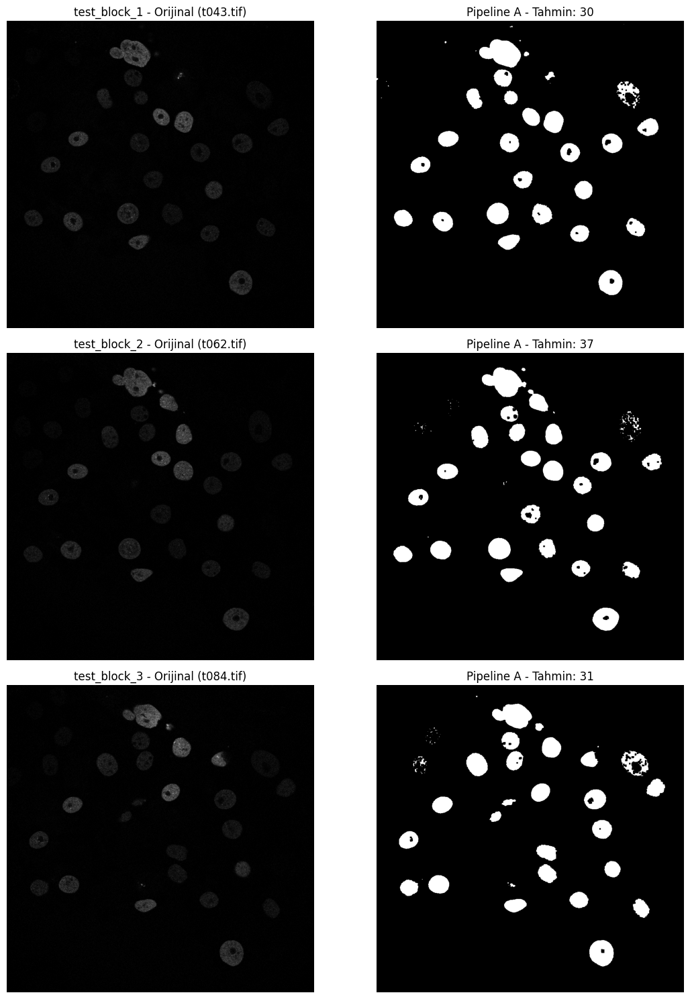

In [60]:
# Bölüm 11.3 - Test tahminlerinin görselleştirilmesi

# Her test bloğundan ilk görüntüyü seçiyoruz.
ornek_testler = (
    test_secimleri
    .sort_values(["group", "frame_index"])
    .groupby("group")
    .first()
    .reset_index()
)

fig, eksenler = plt.subplots(3, 2, figsize=(12, 15))

for i, (_, satir) in enumerate(ornek_testler.iterrows()):

    # Görüntüyü okuyoruz.
    yol = f"/content/Fluo-N2DH-GOWT1/02/{satir['image_file']}"
    goruntu = cv2.imread(yol, cv2.IMREAD_GRAYSCALE)

    # Nihai Pipeline A'yı uyguluyoruz.
    tahmin, ikili_sonuc = pipeline_islet(goruntu, "Pipeline A")

    # Orijinal görüntüyü gösteriyoruz.
    eksenler[i, 0].imshow(goruntu, cmap="gray")
    eksenler[i, 0].set_title(
        f"{satir['group']} - Orijinal ({satir['image_file']})"
    )
    eksenler[i, 0].axis("off")

    # Segmentasyon çıktısını gösteriyoruz.
    eksenler[i, 1].imshow(ikili_sonuc, cmap="gray")
    eksenler[i, 1].set_title(
        f"Pipeline A - Tahmin: {tahmin}"
    )
    eksenler[i, 1].axis("off")

plt.tight_layout()

# Görseli rapor klasörüne kaydediyoruz.
plt.savefig(
    "/content/rapor_gorselleri/figure_test_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Bölüm 12 – Nihai pipeline ve baseline parametrelerinin kaydedilmesi

In [98]:
import os
import json

# Nihai pipeline dosyasını kontrol ediyoruz.
pipeline_yolu = "/content/final_pipeline.json"

print("Pipeline dosyası mevcut:", os.path.exists(pipeline_yolu))

if os.path.exists(pipeline_yolu):
    with open(pipeline_yolu, "r") as f:
        final_pipeline = json.load(f)

    print("\nNihai Pipeline A:")
    print(json.dumps(final_pipeline, indent=4, ensure_ascii=False))

# Önceden kaydedilmiş test tahminlerini kontrol ediyoruz.
tahmin_yolu = "/content/test_predictions_locked.csv"

print("\nTest tahmin dosyası mevcut:", os.path.exists(tahmin_yolu))

if os.path.exists(tahmin_yolu):
    mevcut_tahminler = pd.read_csv(tahmin_yolu)

    print("Tahmin sayısı:", len(mevcut_tahminler))
    display(mevcut_tahminler.head())

Pipeline dosyası mevcut: True

Nihai Pipeline A:
{
    "pipeline_name": "Pipeline A",
    "selection_criterion": "Lowest validation MAE",
    "validation_metrics": {
        "MAE": 1.6,
        "RMSE": 2.0,
        "Bias": 0.0,
        "mean_time_seconds": 0.1024
    },
    "steps": {
        "grayscale": true,
        "contrast_stretching": {
            "lower_percentile": 1,
            "upper_percentile": 99
        },
        "gaussian_blur": {
            "kernel_size": [
                5,
                5
            ],
            "sigma": 0
        },
        "segmentation": {
            "method": "fixed_threshold",
            "threshold": 50
        },
        "morphology": {
            "operation": "closing",
            "kernel_size": [
                5,
                5
            ]
        },
        "connected_components": {
            "connectivity": 8,
            "minimum_area": 20
        }
    }
}

Test tahmin dosyası mevcut: True
Tahmin sayısı: 15


,sequence,frame_index,image_file,block_id,final_prediction,time_seconds
0,2,43,t043.tif,test_block_1,30,0.088209
1,2,44,t044.tif,test_block_1,32,0.116120
2,2,45,t045.tif,test_block_1,28,0.060858
3,2,46,t046.tif,test_block_1,31,0.070458
4,2,47,t047.tif,test_block_1,30,0.120361


Bölüm 12 – Baseline Yönteminin Test Görüntülerinde Uygulanması

In [99]:
import time
import cv2
import pandas as pd

baseline_test_sonuclari = []

for _, satir in test_secimleri.iterrows():

    goruntu_yolu = (
        f"/content/Fluo-N2DH-GOWT1/02/{satir['image_file']}"
    )

    goruntu = cv2.imread(
        goruntu_yolu,
        cv2.IMREAD_GRAYSCALE
    )

    if goruntu is None:
        raise FileNotFoundError(goruntu_yolu)

    baslangic = time.perf_counter()

    # Baseline: Otsu + Connected Components
    _, ikili = cv2.threshold(
        goruntu,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    sayi, etiketler, istatistikler, merkezler = (
        cv2.connectedComponentsWithStats(
            ikili,
            connectivity=8
        )
    )

    alanlar = istatistikler[1:, cv2.CC_STAT_AREA]

    tahmin = int((alanlar >= 20).sum())

    bitis = time.perf_counter()

    baseline_test_sonuclari.append({
        "sequence": satir["sequence"],
        "frame_index": satir["frame_index"],
        "image_file": satir["image_file"],
        "block_id": satir["group"],
        "baseline_prediction": tahmin,
        "baseline_time_seconds": bitis - baslangic
    })

baseline_test_df = pd.DataFrame(baseline_test_sonuclari)

print("Baseline test görüntüsü:", len(baseline_test_df))
print(
    "Baseline ortalama işlem süresi:",
    round(baseline_test_df["baseline_time_seconds"].mean(), 4),
    "saniye"
)

display(baseline_test_df)

Baseline test görüntüsü: 15
Baseline ortalama işlem süresi: 0.0122 saniye


,sequence,frame_index,image_file,block_id,baseline_prediction,baseline_time_seconds
0,2,43,t043.tif,test_block_1,74,0.011435
1,2,44,t044.tif,test_block_1,86,0.011004
2,2,45,t045.tif,test_block_1,81,0.011213
3,2,46,t046.tif,test_block_1,83,0.010420
4,2,47,t047.tif,test_block_1,96,0.013095
5,2,62,t062.tif,test_block_2,53,0.013079
6,2,63,t063.tif,test_block_2,53,0.012881
7,2,64,t064.tif,test_block_2,48,0.012849
8,2,65,t065.tif,test_block_2,56,0.011338
9,2,66,t066.tif,test_block_2,52,0.017514


Bölüm 12 – Baseline ve Pipeline A Segmentasyonlarının Görsel Karşılaştırılması

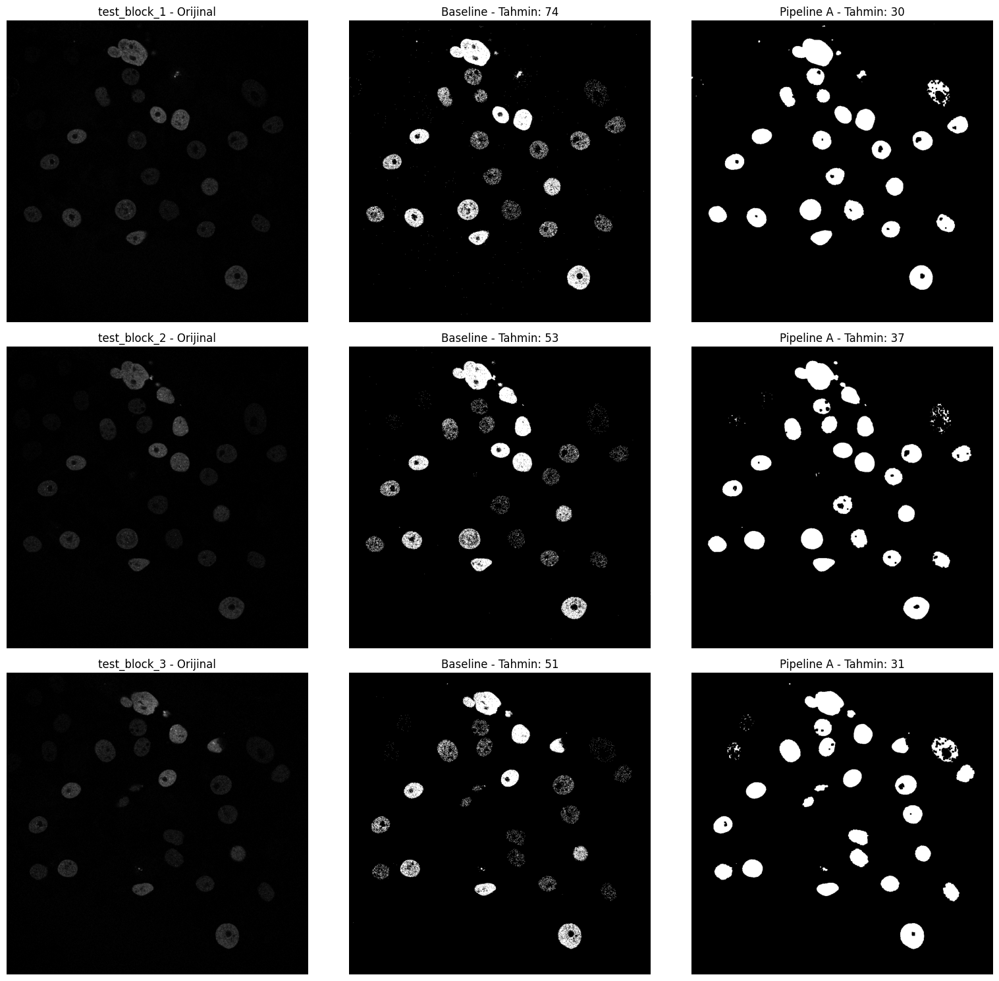

In [100]:
# Her test bloğundan ilk görüntüyü seçiyoruz.
ornek_testler = (
    test_secimleri
    .sort_values(["group", "frame_index"])
    .groupby("group")
    .first()
    .reset_index()
)

fig, eksenler = plt.subplots(3, 3, figsize=(16, 15))

for i, (_, satir) in enumerate(ornek_testler.iterrows()):

    yol = f"/content/Fluo-N2DH-GOWT1/02/{satir['image_file']}"

    goruntu = cv2.imread(yol, cv2.IMREAD_GRAYSCALE)

    # Baseline segmentasyonu
    _, baseline_ikili = cv2.threshold(
        goruntu, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    sayi, etiketler, istatistikler, merkezler = (
        cv2.connectedComponentsWithStats(
            baseline_ikili, connectivity=8
        )
    )

    alanlar = istatistikler[1:, cv2.CC_STAT_AREA]
    baseline_tahmin = int((alanlar >= 20).sum())

    # Pipeline A segmentasyonu
    pipeline_tahmin, pipeline_ikili = pipeline_islet(
        goruntu, "Pipeline A"
    )

    # Orijinal görüntü
    eksenler[i, 0].imshow(goruntu, cmap="gray")
    eksenler[i, 0].set_title(
        f"{satir['group']} - Orijinal"
    )
    eksenler[i, 0].axis("off")

    # Baseline
    eksenler[i, 1].imshow(baseline_ikili, cmap="gray")
    eksenler[i, 1].set_title(
        f"Baseline - Tahmin: {baseline_tahmin}"
    )
    eksenler[i, 1].axis("off")

    # Pipeline A
    eksenler[i, 2].imshow(pipeline_ikili, cmap="gray")
    eksenler[i, 2].set_title(
        f"Pipeline A - Tahmin: {pipeline_tahmin}"
    )
    eksenler[i, 2].axis("off")

plt.tight_layout()

plt.savefig(
    "/content/rapor_gorselleri/figure_baseline_pipeline_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Bölüm 12 – Baseline ve Pipeline A Tahminlerinin Birleştirilmesi

In [101]:
# Pipeline A tahminlerini yüklüyoruz.
pipeline_a_df = pd.read_csv(
    "/content/test_predictions_locked.csv"
)

# İki yöntemin ortak sütunlarına göre birleştiriyoruz.
test_kilitli_df = pd.merge(
    pipeline_a_df,
    baseline_test_df,
    on=["sequence", "frame_index", "image_file", "block_id"],
    how="inner"
)

# Sütunları düzenliyoruz.
test_kilitli_df = test_kilitli_df[
    [
        "sequence",
        "frame_index",
        "image_file",
        "block_id",
        "baseline_prediction",
        "baseline_time_seconds",
        "final_prediction",
        "time_seconds"
    ]
]

# İki yöntemin tahminlerini tek dosyaya kaydediyoruz.
test_kilitli_df.to_csv(
    "/content/test_predictions_locked.csv",
    index=False
)

print("Toplam test görüntüsü:", len(test_kilitli_df))
print("Eksik tahmin var mı:", test_kilitli_df.isnull().any().any())

display(test_kilitli_df)

Toplam test görüntüsü: 15
Eksik tahmin var mı: False


,sequence,frame_index,image_file,block_id,baseline_prediction,baseline_time_seconds,final_prediction,time_seconds
0,2,43,t043.tif,test_block_1,74,0.011435,30,0.088209
1,2,44,t044.tif,test_block_1,86,0.011004,32,0.116120
2,2,45,t045.tif,test_block_1,81,0.011213,28,0.060858
3,2,46,t046.tif,test_block_1,83,0.010420,31,0.070458
4,2,47,t047.tif,test_block_1,96,0.013095,30,0.120361
5,2,62,t062.tif,test_block_2,53,0.013079,37,0.086568
6,2,63,t063.tif,test_block_2,53,0.012881,34,0.052723
7,2,64,t064.tif,test_block_2,48,0.012849,34,0.065082
8,2,65,t065.tif,test_block_2,56,0.011338,34,0.089067
9,2,66,t066.tif,test_block_2,52,0.017514,36,0.059777


Bölüm 12 – Test Tahminlerinin ve Pipeline Dosyasının Kontrolü

In [102]:
import os
import json
import pandas as pd

# Kilitlenmiş tahmin dosyasını tekrar okuyoruz.
kontrol_df = pd.read_csv(
    "/content/test_predictions_locked.csv"
)

# Pipeline parametrelerini okuyoruz.
with open("/content/final_pipeline.json", "r") as f:
    pipeline_kontrol = json.load(f)

print("TEST TAHMİN KONTROLÜ")
print("--------------------")
print("Toplam kayıt:", len(kontrol_df))
print("Baseline tahminleri:", kontrol_df["baseline_prediction"].notna().sum())
print("Pipeline A tahminleri:", kontrol_df["final_prediction"].notna().sum())
print("Eksik değer:", kontrol_df.isnull().sum().sum())

print("\nTEST BLOKLARI")
display(kontrol_df.groupby("block_id").size())

print("\nPIPELINE DOSYASI")
print("Pipeline:", pipeline_kontrol["pipeline_name"])

print("\nDOSYA KONTROLÜ")
for dosya in [
    "/content/final_pipeline.json",
    "/content/test_predictions_locked.csv"
]:
    print(os.path.basename(dosya), ":", os.path.exists(dosya))

TEST TAHMİN KONTROLÜ
--------------------
Toplam kayıt: 15
Baseline tahminleri: 15
Pipeline A tahminleri: 15
Eksik değer: 0

TEST BLOKLARI


,0
block_id,
test_block_1,5
test_block_2,5
test_block_3,5



PIPELINE DOSYASI
Pipeline: Pipeline A

DOSYA KONTROLÜ
final_pipeline.json : True
test_predictions_locked.csv : True


Bölüm 12 – Baseline ve Pipeline A Test Tahminlerinin Görselleştirilmesi

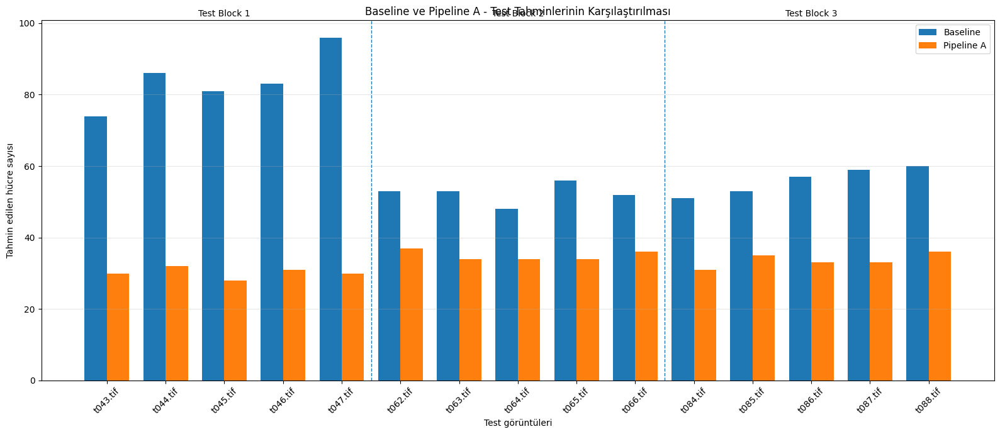

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Kilitlenmiş tahmin dosyasını okuyoruz.
grafik_df = pd.read_csv(
    "/content/test_predictions_locked.csv"
)

grafik_df = grafik_df.sort_values(
    ["block_id", "frame_index"]
).reset_index(drop=True)

# Grafik alanını oluşturuyoruz.
fig, ax = plt.subplots(figsize=(16, 7))

x = np.arange(len(grafik_df))
genislik = 0.38

# Baseline tahminleri
ax.bar(
    x - genislik / 2,
    grafik_df["baseline_prediction"],
    genislik,
    label="Baseline"
)

# Pipeline A tahminleri
ax.bar(
    x + genislik / 2,
    grafik_df["final_prediction"],
    genislik,
    label="Pipeline A"
)

# Kare numaraları
ax.set_xticks(x)
ax.set_xticklabels(
    grafik_df["image_file"],
    rotation=45
)

# Test bloklarının sınırları
ax.axvline(4.5, linestyle="--", linewidth=1)
ax.axvline(9.5, linestyle="--", linewidth=1)

ax.text(2, 102, "Test Block 1", ha="center")
ax.text(7, 102, "Test Block 2", ha="center")
ax.text(12, 102, "Test Block 3", ha="center")

ax.set_title(
    "Baseline ve Pipeline A - Test Tahminlerinin Karşılaştırılması"
)
ax.set_xlabel("Test görüntüleri")
ax.set_ylabel("Tahmin edilen hücre sayısı")

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Rapor klasörüne kaydediyoruz.
plt.savefig(
    "/content/rapor_gorselleri/21_test_tahmin_karsilastirma.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Bölüm 12 – Baseline Parametrelerinin Kaydedilmesi

In [104]:
import json

baseline_parameters = {
    "method": "Otsu Thresholding + Connected Component Labeling",
    "thresholding": {
        "method": "Otsu",
        "type": "Binary"
    },
    "connected_components": {
        "connectivity": 8,
        "minimum_area": 20
    },
    "prediction_rule": "Count components with area >= 20"
}

baseline_path = "/content/rapor_gorselleri/baseline_parameters.json"

with open(baseline_path, "w", encoding="utf-8") as f:
    json.dump(
        baseline_parameters,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Baseline parametreleri kaydedildi.")
print("Dosya:", baseline_path)

with open(baseline_path, "r", encoding="utf-8") as f:
    print(json.dumps(json.load(f), ensure_ascii=False, indent=4))

Baseline parametreleri kaydedildi.
Dosya: /content/rapor_gorselleri/baseline_parameters.json
{
    "method": "Otsu Thresholding + Connected Component Labeling",
    "thresholding": {
        "method": "Otsu",
        "type": "Binary"
    },
    "connected_components": {
        "connectivity": 8,
        "minimum_area": 20
    },
    "prediction_rule": "Count components with area >= 20"
}


Bölüm 12 – GitHub Ön Test Dosyalarının Kontrolü

In [105]:
import os

kontrol_dosyalari = [
    "/content/final_pipeline.json",
    "/content/rapor_gorselleri/baseline_parameters.json",
    "/content/test_predictions_locked.csv",
    "/content/rapor_gorselleri/21_test_tahmin_karsilastirma.png"
]

print("GITHUB ÖN TEST DOSYA KONTROLÜ")
print("-" * 40)

for dosya in kontrol_dosyalari:
    print(
        "OK" if os.path.exists(dosya) else "EKSIK",
        os.path.basename(dosya)
    )

GITHUB ÖN TEST DOSYA KONTROLÜ
----------------------------------------
OK final_pipeline.json
OK baseline_parameters.json
OK test_predictions_locked.csv
OK 21_test_tahmin_karsilastirma.png


Github için dosyaları hazırla

In [106]:
import os
import shutil
import zipfile

# GitHub ön-test dosyaları için hazırlık klasörü
kaynaklar = {
    "/content/final_pipeline.json": "final_pipeline.json",
    "/content/rapor_gorselleri/baseline_parameters.json": "baseline_parameters.json",
    "/content/test_predictions_locked.csv": "test_predictions_locked.csv",
    "/content/rapor_gorselleri/21_test_tahmin_karsilastirma.png": "21_test_tahmin_karsilastirma.png",
    "/content/rapor_gorselleri/figure_baseline_pipeline_test.png": "figure_baseline_pipeline_test.png",
    "/content/rapor_gorselleri/tum_kontrollu_deneyler.csv": "tum_kontrollu_deneyler.csv",
    "/content/rapor_gorselleri/pipeline_karsilastirma_tablosu.csv": "pipeline_karsilastirma_tablosu.csv",
    "/content/rapor_gorselleri/pipeline_deney_sonuclari.csv": "pipeline_deney_sonuclari.csv",
    "/content/rapor_gorselleri/validation_pipeline_sonuclari.csv": "validation_pipeline_sonuclari.csv",
    "/content/rapor_gorselleri/validation_pipeline_ozeti.csv": "validation_pipeline_ozeti.csv"
}

hedef = "/content/github_on_test"
os.makedirs(hedef, exist_ok=True)

basarili = []
eksik = []

for kaynak, dosya_adi in kaynaklar.items():
    if os.path.exists(kaynak):
        shutil.copy2(kaynak, os.path.join(hedef, dosya_adi))
        basarili.append(dosya_adi)
    else:
        eksik.append(kaynak)

# Dosya listesini göster
print("Kopyalanan dosyalar:")
for dosya in basarili:
    print("OK:", dosya)

print("\nEksik dosyalar:")
for dosya in eksik:
    print("EKSIK:", dosya)

# Hazırlanan dosyaları ZIP yap
zip_yolu = "/content/github_on_test.zip"

with zipfile.ZipFile(zip_yolu, "w", zipfile.ZIP_DEFLATED) as zip_dosyasi:
    for dosya in os.listdir(hedef):
        zip_dosyasi.write(
            os.path.join(hedef, dosya),
            arcname=dosya
        )

print("\nZIP hazır:", os.path.exists(zip_yolu))

Kopyalanan dosyalar:
OK: final_pipeline.json
OK: baseline_parameters.json
OK: test_predictions_locked.csv
OK: 21_test_tahmin_karsilastirma.png
OK: figure_baseline_pipeline_test.png
OK: tum_kontrollu_deneyler.csv
OK: pipeline_karsilastirma_tablosu.csv
OK: pipeline_deney_sonuclari.csv
OK: validation_pipeline_sonuclari.csv
OK: validation_pipeline_ozeti.csv

Eksik dosyalar:

ZIP hazır: True
